# Does adding the OpenStreetMap features improve the baseline, and why is the result what it is?

This notebook trains the team's baseline (Delaware, GraphSAGE, classification) with and without the OpenStreetMap (OSM) road features built in
`osm_features_and_eda.ipynb` (its Stage 13 hand-off), compares the results, and then asks **why** the change is the size it is.

**The baseline.** The benchmark paper (Nippani et al., NeurIPS 2023, [arXiv 2311.00164](https://arxiv.org/abs/2311.00164)) reports GraphSAGE with Node2Vec
embeddings as node features ("To enhance the prediction of GNN, we add Node2Vec embeddings as node features", Section 3.1): AUROC 87.6 for Delaware (Table 2).
The team's code (`aaronteork/CS5284_GML`, `main` at commit `299962d`) is a **modified reproduction** of that model, not an exact one (see its `docs/baseline_differences.md`),
so our numbers are compared with the team's committed results, and with the paper only for scale. The team's code also runs every model without Node2Vec, which we use to explain the result.

**How the comparison is kept fair**
- The baseline's code is used unchanged (a pinned copy). A small driver (`osm_train.py`, written below) appends the OSM columns to the baseline's road features; nothing in `src/` is edited.
- The **control run** uses the same driver with no OSM columns, so its inputs are exactly the baseline's. A difference between the control and an OSM run comes from the OSM columns.
- Same years (train 2009-2012, validation 2013-2017, test 2018-2022, the paper's Table 7), the same three seeds, the same model selection and evaluation.
- The OSM columns contain no accident information, and none were selected, dropped or filled using accident counts. The zips in `data/` are never modified (checked).

**Runs** (Delaware, GraphSAGE, 3 seeds, 100 epochs)

| | control (no OSM) | all OSM features | all OSM, gap-filled tags |
|---|---|---|---|
| with Node2Vec (the paper's setting) | already trained | retrained on the current table | optional (`RUN_ALL_FILLED`) |
| without Node2Vec (explains the result) | the team's committed run (not retrained) | **to train** | - |

Section 14 adds the same OSM features to the other baseline settings (MLP classification, MLP regression and GraphSAGE regression, with Node2Vec), so that the final report can compare every input setting for both models and both tasks. Section 15 records the same comparison for GatedGCN and Graph Transformer, which were trained with the team's main training script.

The three Node2Vec runs were trained before the feature groups were renamed. Section 4.1 checks that the renamed feature table gives **exactly** the same model inputs before reusing them.
**The no-Node2Vec control is the team's committed run** (`main` at `299962d`, GraphSAGE without Node2Vec, seeds 0-2) instead of a retrain: the Node2Vec control
trained here reproduces the team's committed result to four decimals, so their runs are the same pipeline's output. A finished seed is never trained again,
so an interrupted session loses at most one seed.

**You need** in `My Drive/cs5284_project/data/`: `DE.zip`, the two hand-off files from `osm_features_and_eda.ipynb` (`DE_osm_features.parquet`, `DE_osm_features_meta.json`),
and, for the reuse check only, the older table `DE_osm_model_features.parquet` with its meta file (delete them only after this notebook has run). A GPU runtime.

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

/bin/bash: line 1: nvidia-smi: command not found


## 1. Setup

In [2]:
# A working folder for the baseline code. Everything below is written into it, so no GitHub access is needed.
import os
from pathlib import Path

WORK_DIR = Path("/content/baseline_osm")
for folder in ("src/data", "src/eval", "src/model"):
    (WORK_DIR / folder).mkdir(parents=True, exist_ok=True)
os.chdir(WORK_DIR)
Path("src/__init__.py").touch()
print("working folder:", Path.cwd())

working folder: /content/baseline_osm


### The baseline code (a pinned copy)

The next cells write the team's baseline into the working folder, exactly as it is in their repository (`aaronteork/CS5284_GML`, branch `main`, commit `299962d`): `requirements.txt` and the `src/` package (data loading and caches, Node2Vec embeddings, the MLP and GraphSAGE models, training, evaluation). They are copies for running, not edits; the docstrings and comments are theirs. Collapse this part of the notebook after the first run.

In [3]:
%%writefile requirements.txt
# One environment for preprocessing, GPU embeddings, training and notebooks.
# Python 3.10-3.12. The merged implementation does not require karateclub/PyG.
torch==2.5.1
numpy==1.26.4
pandas==2.2.3
scipy==1.13.1
networkx==3.4.2
scikit-learn==1.5.2
tqdm==4.67.1

# Notebooks
matplotlib==3.9.2
seaborn==0.13.2
plotly==5.24.1
ipywidgets==8.1.5

Writing requirements.txt


In [4]:
%%writefile src/data/__init__.py
from .dataset import DATA_DIR, MonthlyData, RoadAccidentDataset, download_state

__all__ = ["DATA_DIR", "MonthlyData", "RoadAccidentDataset", "download_state"]

Writing src/data/__init__.py


In [5]:
%%writefile src/data/cache.py
"""Persistent monthly and structural feature caches adapted from baseline-fw."""
import json
import time
from pathlib import Path

import networkx as nx
import numpy as np
import pandas as pd
from tqdm.auto import tqdm


def load_node_cache(state_dir, columns, num_nodes):
    state_dir = Path(state_dir)
    files = sorted((state_dir / "Nodes").glob("node_features_*_*.csv"),
                   key=lambda p: tuple(map(int, p.stem.split("_")[-2:])))
    if not files:
        raise ValueError(f"No monthly node features in {state_dir}")
    signature = {"version": 2, "columns": columns, "num_nodes": num_nodes,
                 "sources": [[p.name, p.stat().st_size, p.stat().st_mtime_ns] for p in files]}
    cache_dir = state_dir / "cache"
    metadata = cache_dir / "monthly_inputs.json"
    paths = {key: cache_dir / f"{key}.npy" for key in ("weather", "coords")}
    if metadata.exists() and all(p.exists() for p in paths.values()):
        if json.loads(metadata.read_text(encoding="utf-8")) == signature:
            return {k: np.load(p, mmap_mode="r") for k, p in paths.items()}, files
    cache_dir.mkdir(exist_ok=True)
    weather = np.lib.format.open_memmap(paths["weather"].with_suffix(".tmp.npy"),
                mode="w+", dtype=np.float32, shape=(len(files), num_nodes, len(columns)))
    coords = None
    for i, path in enumerate(tqdm(files, desc=f"Cache {state_dir.name} weather", unit="month")):
        df = pd.read_csv(path)
        if len(df) != num_nodes:
            raise ValueError(f"{path} has {len(df)} nodes; expected {num_nodes}")
        if i == 0:
            coords = df[["lon", "lat"]].to_numpy(dtype=np.float32)
        weather[i] = df[columns].to_numpy(dtype=np.float32)
    weather.flush()
    del weather
    np.save(paths["coords"].with_suffix(".tmp.npy"), coords)
    for path in paths.values():
        path.with_suffix(".tmp.npy").replace(path)
    metadata.write_text(json.dumps(signature, indent=2) + "\n", encoding="utf-8")
    return {k: np.load(p, mmap_mode="r") for k, p in paths.items()}, files


def load_static_cache(state_dir, edge_index, num_nodes, k=500, seed=0):
    state_dir = Path(state_dir)
    cache_dir = state_dir / "cache"
    cache_dir.mkdir(exist_ok=True)
    graph_file = state_dir / "adj_matrix.pt"
    signature = dict(version=1, num_nodes=num_nodes, k=min(k, num_nodes), seed=seed,
                     graph_size=graph_file.stat().st_size, graph_mtime=graph_file.stat().st_mtime_ns)
    meta, path = cache_dir / "static_inputs.json", cache_dir / "static_inputs.npz"
    if meta.exists() and path.exists() and json.loads(meta.read_text(encoding="utf-8")) == signature:
        with np.load(path) as cache:
            return {key: cache[key].copy() for key in cache.files}
    src, dst = edge_index.numpy()
    in_degree = np.bincount(dst, minlength=num_nodes)
    out_degree = np.bincount(src, minlength=num_nodes)
    eye = np.eye(max(in_degree.max(), out_degree.max()) + 1, dtype=np.float32)
    degree = np.concatenate([eye[in_degree], eye[out_degree]], axis=1)
    graph = nx.DiGraph()
    graph.add_nodes_from(range(num_nodes))
    graph.add_edges_from(edge_index.t().tolist())
    print(f"{state_dir.name}: computing approximate betweenness (k={signature['k']}, once per graph)", flush=True)
    started = time.perf_counter()
    centrality = nx.betweenness_centrality(graph, k=signature["k"], normalized=True, seed=seed)
    bc = np.array([centrality[i] for i in range(num_nodes)], dtype=np.float32)[:, None]
    arrays = dict(degree=degree, centrality=bc)
    temporary = path.with_suffix(".tmp.npz")
    np.savez(temporary, **arrays)
    temporary.replace(path)
    meta.write_text(json.dumps(signature, indent=2) + "\n", encoding="utf-8")
    print(f"{state_dir.name}: structural cache ready in {time.perf_counter()-started:.1f}s", flush=True)
    return arrays

Writing src/data/cache.py


In [6]:
%%writefile src/data/dataset.py
import json
import shutil
import urllib.error
import urllib.request
import zipfile
from dataclasses import dataclass
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import torch

DATA_DIR = Path(__file__).resolve().parents[2] / "data"

DATAVERSE_URL = "https://dataverse.harvard.edu"
DATAVERSE_DOI = "doi:10.7910/DVN/V71K5R"
WEATHER_COLUMNS = ["tavg", "tmin", "tmax", "prcp", "wspd", "pres"]

# Same column order as the paper's code; keys missing from a state become zero columns.
ROAD_FLAG_KEYS = [
    "oneway", "access_ramp", "bus_stop", "crossing", "disused", "elevator",
    "escape", "living_street", "motorway", "motorway_link", "primary",
    "primary_link", "residential", "rest_area", "road", "secondary",
    "secondary_link", "stairs", "tertiary", "tertiary_link", "trunk",
    "trunk_link", "unclassified", "unsurfaced",
]


def download_state(state, data_dir=DATA_DIR, zip_path=None, keep_zip=False):
    """Download and extract a state's dataset into `data_dir/<state>/`.

    Pass `zip_path` to extract an already-downloaded zip (e.g. from Google Drive)
    instead of downloading from Harvard Dataverse.
    """
    data_dir = Path(data_dir)
    state_dir = data_dir / state
    if (state_dir / "adj_matrix.pt").exists():
        return state_dir

    data_dir.mkdir(parents=True, exist_ok=True)
    if zip_path is None:
        zip_path = data_dir / f"{state}.zip"
        if not zip_path.exists():
            _download_from_dataverse(f"{state}.zip", zip_path)
    zip_path = Path(zip_path)

    print(f"Extracting {zip_path.name}...")
    tmp_dir = data_dir / f"_extract_{state}"
    shutil.rmtree(tmp_dir, ignore_errors=True)
    with zipfile.ZipFile(zip_path) as archive:
        archive.extractall(tmp_dir)

    # Zips differ in layout (`DE/...` vs files at the root), so locate the folder by its contents.
    adj_files = list(tmp_dir.rglob("adj_matrix.pt"))
    if len(adj_files) != 1:
        raise RuntimeError(f"Expected one adj_matrix.pt in {zip_path}, found {len(adj_files)}")
    shutil.move(str(adj_files[0].parent), str(state_dir))
    shutil.rmtree(tmp_dir, ignore_errors=True)

    if not keep_zip and zip_path.parent == data_dir:
        zip_path.unlink()
    print(f"{state} ready at {state_dir}")
    return state_dir


def _download_from_dataverse(filename, dest):
    url = f"{DATAVERSE_URL}/api/datasets/:persistentId/?persistentId={DATAVERSE_DOI}"
    print(f"Looking up {filename} on Harvard Dataverse...", flush=True)
    with _open_dataverse(url, filename, dest) as response:
        files = json.load(response)["data"]["latestVersion"]["files"]
    file_ids = {f["dataFile"]["filename"]: f["dataFile"]["id"] for f in files}
    if filename not in file_ids:
        raise ValueError(f"{filename} not on Dataverse; available: {sorted(file_ids)}")

    file_url = f"{DATAVERSE_URL}/api/access/datafile/{file_ids[filename]}"
    tmp = dest.with_suffix(".part")
    print(f"Downloading {filename}...")
    with _open_dataverse(file_url, filename, dest) as response, open(tmp, "wb") as f:
        shutil.copyfileobj(response, f, length=1 << 20)
    tmp.rename(dest)


def _open_dataverse(url, filename, dest):
    try:
        return urllib.request.urlopen(url, timeout=60)
    except urllib.error.HTTPError as exc:
        if exc.code == 403:
            raise RuntimeError(
                f"Harvard Dataverse returned HTTP 403 for {filename}. "
                "Download the ZIP in your browser from https://doi.org/10.7910/DVN/V71K5R "
                f"and place it at {dest}, then rerun. In the Colab notebook, this maps to "
                f"My Drive/cs5284_project/data/{filename}. "
                "The loader will extract the local ZIP without contacting Dataverse."
            ) from exc
        raise


@dataclass
class MonthlyData:
    """Inputs and labels for one month.

    The graph is directed: two-way roads appear as two edges, one-way roads as one.
    Labels are per physical road (undirected), so an accident road's reverse
    direction is never treated as accident-free.
    """
    year: int
    month: int
    x: torch.Tensor           # [num_nodes, F] node features (embeddings + normalised weather)
    edge_index: torch.Tensor  # [2, num_edges] directed edges, for message passing
    edge_attr: torch.Tensor   # [num_edges, D] edge features
    road_edge: torch.Tensor   # [num_roads] one representative directed edge per road
    y: torch.Tensor           # [num_roads] accident count this month

    @property
    def road_index(self):
        return self.edge_index[:, self.road_edge]

    @property
    def road_attr(self):
        return self.edge_attr[self.road_edge]

    def to(self, device):
        return MonthlyData(
            self.year, self.month,
            *(t.to(device) for t in (self.x, self.edge_index, self.edge_attr, self.road_edge, self.y)),
        )


class RoadAccidentDataset:
    """Merged feature pipeline; only Node2Vec inclusion varies in the ablation.

    Targets remain physical roads; the graph is directed for message passing.
    Continuous weather/AADT statistics and missing-value filling use training
    years. Missing traffic years carry forward only an earlier available report.
    """

    def __init__(self, state, train_years, data_dir=DATA_DIR,
                 node_embedding_path=None, download=True):
        from .cache import load_node_cache, load_static_cache
        self.state, self.train_years = state, list(train_years)
        self.dir = Path(data_dir) / state
        self.target_unit = "physical"
        if download:
            download_state(state, data_dir)
        adj = torch.load(self.dir / "adj_matrix.pt", map_location="cpu", weights_only=False).coalesce()
        self.num_nodes = adj.shape[0]
        self.edge_index = adj.indices().long()
        src, dst = self.edge_index.numpy()
        self._edge_key = src * self.num_nodes + dst
        road_key = np.minimum(src, dst) * self.num_nodes + np.maximum(src, dst)
        self._road_key, road_edge = np.unique(road_key, return_index=True)
        self.road_edge = torch.from_numpy(road_edge).long()
        self.num_roads = len(self._road_key)
        self.static_edge_attr = self._load_static_edge_attr()
        self._accidents = self._load_accidents()
        self._node_cache, month_files = load_node_cache(self.dir, WEATHER_COLUMNS, self.num_nodes)
        self.available_months = [tuple(map(int, p.stem.split("_")[-2:])) for p in month_files]
        self._month_position = {ym: i for i, ym in enumerate(self.available_months)}
        self.node_coordinates = torch.from_numpy(np.array(self._node_cache["coords"]))
        static = load_static_cache(self.dir, self.edge_index, self.num_nodes)
        coords = self._standardize_static(self.node_coordinates)
        centrality = self._standardize_static(torch.log1p(torch.from_numpy(static["centrality"]) * 1e3))
        self.static_node_features = torch.cat([coords, torch.from_numpy(static["degree"]), centrality], dim=1)
        self.node_embeddings = None
        if node_embedding_path is not None:
            embeddings = torch.from_numpy(np.load(node_embedding_path)).float()
            if embeddings.ndim != 2 or embeddings.shape[0] != self.num_nodes or not torch.isfinite(embeddings).all():
                raise ValueError("Invalid or misaligned node embeddings")
            self.node_embeddings = self._standardize_static(embeddings)
        train_months = self.months(self.train_years)
        if not train_months:
            raise ValueError("Training years contain no weather months")
        self._weather_mean, self._weather_std = self._train_stats(
            torch.cat([self._raw_weather(y, m) for y, m in train_months]))
        self._traffic_files = {int(p.stem.split("_")[-1]): p
            for p in (self.dir / "Edges").glob("edge_features_traffic_*.pt")}
        self._traffic_mean, self._traffic_std = self._train_stats(
            torch.cat([self._raw_traffic(y) for y in self.train_years]))

    def months(self, years):
        return [(y, m) for y, m in self.available_months if y in set(years)]

    def monthly(self, year, month):
        raw_weather = self._raw_weather(year, month)
        weather_missing = (~torch.isfinite(raw_weather)).float()
        weather = torch.nan_to_num((raw_weather - self._weather_mean) / self._weather_std,
                                   nan=0.0, posinf=0.0, neginf=0.0)
        inputs = [self.static_node_features, weather, weather_missing]
        if self.node_embeddings is not None:
            inputs.append(self.node_embeddings)
        x = torch.cat(inputs, dim=1)
        raw_traffic = self._raw_traffic(year)
        missing = (~torch.isfinite(raw_traffic)).float()
        traffic = torch.nan_to_num((raw_traffic - self._traffic_mean) / self._traffic_std,
                                   nan=0.0, posinf=0.0, neginf=0.0)
        edge_attr = torch.cat([self.static_edge_attr, traffic, missing], dim=1)
        y = torch.zeros(self.num_roads)
        road_ids, counts = self._accidents.get((year, month), (np.array([], dtype=np.int64), np.array([])))
        y[torch.from_numpy(road_ids)] = torch.from_numpy(counts).float()
        return MonthlyData(year, month, x, self.edge_index, edge_attr, self.road_edge, y)

    def _edge_values(self, sparse):
        """Align raw COO observations, averaging duplicates while ignoring NaNs."""
        src, dst = sparse._indices().numpy()
        keys = src * self.num_nodes + dst
        pos = np.clip(np.searchsorted(self._edge_key, keys), 0, len(self._edge_key) - 1)
        values = sparse._values().float()
        valid = torch.from_numpy(self._edge_key[pos] == keys) & torch.isfinite(values)
        positions = torch.from_numpy(pos)[valid]
        sums, counts = torch.zeros(len(self._edge_key)), torch.zeros(len(self._edge_key))
        sums.index_add_(0, positions, values[valid])
        counts.index_add_(0, positions, torch.ones(len(positions)))
        out = torch.full_like(sums, float("nan"))
        out[counts > 0] = sums[counts > 0] / counts[counts > 0]
        return out

    def _load_static_edge_attr(self):
        features = torch.load(self.dir / "Edges" / "edge_features.pt", map_location="cpu", weights_only=False)
        features = {str(k): v for k, v in features.items()}
        columns = [torch.nan_to_num(self._edge_values(features[key])) if key in features
                   else torch.zeros(len(self._edge_key)) for key in ROAD_FLAG_KEYS]
        length = self._edge_values(features["length"])
        if (length[torch.isfinite(length)] < 0).any():
            raise ValueError("Road lengths must be nonnegative")
        columns.append(self._standardize_static(torch.log1p(length).view(-1, 1)).squeeze(1))
        return torch.stack(columns, dim=1)

    def _load_accidents(self):
        acc = pd.read_csv(self.dir / "accidents_monthly.csv")
        a, b = acc["node_1_idx"].to_numpy(), acc["node_2_idx"].to_numpy()
        key = np.minimum(a, b) * self.num_nodes + np.maximum(a, b)
        pos = np.clip(np.searchsorted(self._road_key, key), 0, self.num_roads - 1)
        found = self._road_key[pos] == key
        if not found.all():
            print(f"Warning: {(~found).sum()} accident rows don't match a road; dropped")
        acc = pd.DataFrame({"year": acc["year"].to_numpy()[found], "month": acc["month"].to_numpy()[found],
            "road": pos[found], "count": acc["acc_count"].to_numpy()[found]})
        if (acc["count"] < 0).any():
            raise ValueError("Accident counts must be nonnegative")
        acc = acc.groupby(["year", "month", "road"], as_index=False)["count"].sum()
        return {(int(y), int(m)): (g["road"].to_numpy(), g["count"].to_numpy())
                for (y, m), g in acc.groupby(["year", "month"])}

    @lru_cache(maxsize=None)
    def _raw_weather(self, year, month):
        return torch.from_numpy(np.array(self._node_cache["weather"][self._month_position[(year, month)]]))

    @lru_cache(maxsize=None)
    def _raw_traffic(self, year):
        earlier = [y for y in self._traffic_files if y <= year]
        if not earlier:
            return torch.full((len(self._edge_key), 1), float("nan"))
        path = self._traffic_files[max(earlier)]
        raw = self._edge_values(torch.load(path, map_location="cpu", weights_only=False)["AADT"])
        if (raw[torch.isfinite(raw)] < 0).any():
            raise ValueError("AADT must be nonnegative")
        return torch.log1p(raw).view(-1, 1)

    @staticmethod
    def _train_stats(values):
        finite = torch.isfinite(values)
        count = finite.sum(dim=0).clamp(min=1)
        mean = torch.where(finite, values, 0).sum(dim=0) / count
        variance = torch.where(finite, values - mean, 0).square().sum(dim=0) / count
        std = variance.sqrt()
        return mean, torch.where(std > 0, std, torch.ones_like(std))

    @classmethod
    def _standardize_static(cls, values):
        mean, std = cls._train_stats(values)
        return torch.nan_to_num((values - mean) / std, nan=0.0, posinf=0.0, neginf=0.0)

Writing src/data/dataset.py


In [7]:
%%writefile src/data/node2vec.py
"""Fast Node2Vec-style GPU embeddings adapted from baseline-fw.

Custom skip-gram/negative sampling, p=q=1, 20-step walks. This is a documented
change from the paper's karateclub/gensim implementation, not strict replication.
"""
import argparse
import json
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

from .dataset import DATA_DIR, download_state

BACKEND = "baseline-fw.torch-skipgram-v2"


def node2vec_path(state, data_dir=DATA_DIR, dimensions=128):
    return Path(data_dir) / "embeddings" / "node2vec_merged" / f"{state}_{dimensions}.npy"


def train_embeddings(edge_index, num_nodes, dimensions=128, walk_length=20,
                     walks_per_node=10, window_size=5, epochs=1, batch_size=1024,
                     lr=0.01, seed=0, device=None):
    device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    if num_nodes < 1 or min(dimensions, walks_per_node, epochs, batch_size) < 1:
        raise ValueError("Node count, dimensions, walks, epochs and batch size must be positive")
    if walk_length < 2 or not 1 <= window_size < walk_length:
        raise ValueError("Require 1 <= window_size < walk_length")
    # Deduplicate reverse edges before sampling: bidirectional roads must not
    # receive extra probability simply because both directions were recorded.
    ei = edge_index.to(device)
    keys = torch.unique(torch.cat([ei[0] * num_nodes + ei[1], ei[1] * num_nodes + ei[0]]))
    src, col = keys // num_nodes, keys % num_nodes
    degree = torch.bincount(src, minlength=num_nodes)
    rowptr = torch.zeros(num_nodes + 1, dtype=torch.long, device=device)
    rowptr[1:] = degree.cumsum(0)
    rng = torch.Generator(device=device).manual_seed(seed)

    def walks(start):
        path, current = [start], start
        for _ in range(walk_length - 1):
            d = degree[current]
            offset = (torch.rand(current.shape, generator=rng, device=device) * d.clamp(min=1)).long()
            if col.numel():
                nxt = col[(rowptr[current] + offset).clamp(max=col.numel() - 1)]
                current = torch.where(d > 0, nxt, current)
            path.append(current)
        return torch.stack(path, dim=1)

    cuda_devices = [device.index if device.index is not None else torch.cuda.current_device()] if device.type == "cuda" else []
    with torch.random.fork_rng(devices=cuda_devices):
        torch.manual_seed(seed)
        embedding = torch.nn.Embedding(num_nodes, dimensions, device=device)
        context = torch.nn.Embedding(num_nodes, dimensions, device=device)
        torch.nn.init.normal_(embedding.weight, std=0.1)
        torch.nn.init.zeros_(context.weight)
        optimizer = torch.optim.Adam(list(embedding.parameters()) + list(context.parameters()), lr=lr)
        for epoch in range(epochs):
            starts = torch.arange(num_nodes, device=device).repeat(walks_per_node)
            starts = starts[torch.randperm(starts.numel(), generator=rng, device=device)]
            progress = tqdm(starts.split(batch_size), desc=f"Node2Vec epoch {epoch+1}/{epochs}", unit="batch")
            for start in progress:
                w = walks(start)
                centres = torch.cat([w[:, :-offset] for offset in range(1, window_size + 1)], 1).reshape(-1)
                contexts = torch.cat([w[:, offset:] for offset in range(1, window_size + 1)], 1).reshape(-1)
                negative = torch.randint(num_nodes, (centres.numel(),), generator=rng, device=device)
                z = embedding(centres)
                loss = -(F.logsigmoid((z * context(contexts)).sum(-1))
                         + F.logsigmoid(-(z * context(negative)).sum(-1))).mean()
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                progress.set_postfix(loss=f"{loss.item():.4f}", refresh=False)
        return embedding.weight.detach().cpu().numpy().copy()


def generate_node2vec(state, data_dir=DATA_DIR, dimensions=128, walk_length=20,
                      walks_per_node=10, window_size=5, epochs=1, batch_size=1024,
                      lr=0.01, seed=0, device=None, force=False):
    params = dict(dimensions=dimensions, walk_length=walk_length, walks_per_node=walks_per_node,
                  window_size=window_size, epochs=epochs, batch_size=batch_size, lr=lr, seed=seed,
                  p=1, q=1, negatives_per_pair=1, context_direction="forward")
    expected = dict(backend=BACKEND, state=state, parameters=params)
    out = node2vec_path(state, data_dir, dimensions)
    meta = out.with_suffix(".json")
    state_dir = download_state(state, data_dir)
    adj = torch.load(state_dir / "adj_matrix.pt", map_location="cpu", weights_only=False).coalesce()
    num_nodes = adj.shape[0]
    if out.exists() and not force:
        metadata = json.loads(meta.read_text(encoding="utf-8")) if meta.exists() else {}
        if any(metadata.get(k) != v for k, v in expected.items()) or metadata.get("num_nodes") != num_nodes:
            raise ValueError(f"{out} belongs to another embedding configuration. Use --force to regenerate.")
        _validate_embeddings(np.load(out), num_nodes, dimensions)
        print(f"{state}: reusing {out}", flush=True)
        return out
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    print(f"{state}: generating {BACKEND} on {device} ({num_nodes:,} nodes)", flush=True)
    emb = train_embeddings(adj.indices(), num_nodes, dimensions, walk_length, walks_per_node,
                           window_size, epochs, batch_size, lr, seed, device)
    _validate_embeddings(emb, num_nodes, dimensions)
    out.parent.mkdir(parents=True, exist_ok=True)
    temp = out.with_suffix(".tmp.npy")
    np.save(temp, emb)
    temp.replace(out)
    expected.update(num_nodes=num_nodes, torch_version=str(torch.__version__), device=device)
    meta.write_text(json.dumps(expected, indent=2) + "\n", encoding="utf-8")
    print(f"Saved {emb.shape} to {out}", flush=True)
    return out


def _validate_embeddings(embeddings, num_nodes, dimensions):
    if embeddings.shape != (num_nodes, dimensions) or not np.isfinite(embeddings).all():
        raise ValueError("Invalid embedding shape or non-finite values")
    norms = np.linalg.norm(embeddings.astype(np.float64), axis=1)
    if not np.isfinite(norms).all() or (norms == 0).any():
        raise ValueError("Invalid embedding norms")


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--state", nargs="+", default=["DE"], choices=["DE", "MD"])
    parser.add_argument("--epochs", type=int, default=1)
    parser.add_argument("--seed", type=int, default=0)
    parser.add_argument("--device", default=None)
    parser.add_argument("--force", action="store_true")
    args = parser.parse_args()
    for state in args.state:
        generate_node2vec(state, epochs=args.epochs, seed=args.seed, device=args.device, force=args.force)

Writing src/data/node2vec.py


In [8]:
%%writefile src/eval/__init__.py
from .evaluate import PROTOCOLS, balanced_road_ids, evaluate, predict
from .metrics import classification_metrics, regression_metrics

__all__ = [
    "PROTOCOLS", "balanced_road_ids", "classification_metrics", "evaluate", "predict", "regression_metrics",
]

Writing src/eval/__init__.py


In [9]:
%%writefile src/eval/evaluate.py
import numpy as np
import torch

from .metrics import classification_metrics, regression_metrics

PROTOCOLS = ("all", "balanced")


def balanced_road_ids(y, year, month):
    """Every accident road plus an equal number of accident-free roads.

    The sample is seeded by the month, so every model is scored on the same roads.
    This is a supplementary diagnostic; the paper's filtered evaluation population
    is different from both our balanced sample and our full-network population.
    """
    positive = torch.nonzero(y > 0).squeeze(1).cpu().numpy()
    negative = torch.nonzero(y == 0).squeeze(1).cpu().numpy()
    rng = np.random.default_rng(year * 12 + month)
    sampled = rng.choice(negative, size=min(len(positive), len(negative)), replace=False)
    return torch.from_numpy(np.concatenate([positive, sampled]))


@torch.no_grad()
def predict(model, data, task):
    """Predictions for every road: accident probability or expected count."""
    model.eval()
    out = model(data)
    return torch.sigmoid(out) if task == "classification" else out.clamp(min=0)


def evaluate(model, dataset, months, task, device, return_predictions=False):
    """Score a model on `months` under both protocols.

    - "all": every road in every month, i.e. how the model would be used.
    - "balanced": accident roads plus an equal sample of accident-free roads,
      reported as a supplementary diagnostic.

    Classification metrics are always reported (a predicted count is also a risk
    score); regression metrics are added for the regression task.

    Zero-accident months contribute to "all" metrics and prediction exports.
    They have no balanced examples, since there are no positives to balance.
    """
    collected = {p: {"pred": [], "y": [], "group": []} for p in PROTOCOLS}
    all_preds, all_y, evaluated_months = [], [], []

    for group, (year, month) in enumerate(months):
        data = dataset.monthly(year, month).to(device)
        pred, y = predict(model, data, task).cpu(), data.y.cpu()

        ids = balanced_road_ids(y, year, month)
        for protocol, (p, t) in {"all": (pred, y), "balanced": (pred[ids], y[ids])}.items():
            collected[protocol]["pred"].append(p)
            collected[protocol]["y"].append(t)
            collected[protocol]["group"].append(torch.full((len(p),), group))

        if return_predictions:
            all_preds.append(pred)
            all_y.append(y)
            evaluated_months.append((year, month))

    results = {}
    for protocol, c in collected.items():
        pred, y, group = (torch.cat(c[k]).numpy() for k in ("pred", "y", "group"))
        metrics = classification_metrics(pred, y > 0, groups=group)
        if task == "regression":
            metrics.update(regression_metrics(pred, y))
        results[protocol] = metrics

    if not return_predictions:
        return results
    predictions = {
        "months": evaluated_months,
        "pred": torch.stack(all_preds),            # [num_months, num_roads]
        "y": torch.stack(all_y),                   # [num_months, num_roads]
        "road_index": dataset.edge_index[:, dataset.road_edge],  # [2, num_roads]
        "target_unit": getattr(dataset, "target_unit", "physical"),
    }
    if getattr(dataset, "node_coordinates", None) is not None:
        predictions["node_coordinates"] = dataset.node_coordinates  # [N, 2], longitude then latitude
    return results, predictions

Writing src/eval/evaluate.py


In [10]:
%%writefile src/eval/metrics.py
import numpy as np
from sklearn.metrics import average_precision_score, precision_score, recall_score, roc_auc_score


def classification_metrics(scores, labels, groups=None, top_frac=0.01):
    """Metrics for "did this road have an accident".

    `scores` are probabilities (or any risk score), `labels` are 0/1. Top-k precision
    and recall flag the `top_frac` highest-scoring roads; with `groups` (e.g. month ids)
    they're computed per group and averaged, matching how a monthly risk list is used.
    AUROC is computed per group and weighted by the positive-road count, following
    the paper's aggregation. Pooled AUROC is retained as a supplementary metric.
    Other classification metrics use the pooled examples.
    """
    scores, labels = np.asarray(scores, dtype=float), np.asarray(labels).astype(int)
    nonempty = len(labels) > 0
    has_positive = bool(labels.any())
    metrics = {
        "AUROC": roc_auc_score(labels, scores) if len(np.unique(labels)) == 2 else float("nan"),
        "PR-AUC": (average_precision_score(labels, scores) if has_positive else 0.0)
                  if nonempty else float("nan"),
        "precision@0.5": precision_score(labels, scores > 0.5, zero_division=0)
                         if nonempty else float("nan"),
        "recall@0.5": recall_score(labels, scores > 0.5, zero_division=0)
                      if nonempty else float("nan"),
    }

    groups = np.zeros(len(scores), dtype=int) if groups is None else np.asarray(groups)
    monthly_auc, auc_weights = [], []
    precisions, recalls = [], []
    for g in np.unique(groups):
        s, y = scores[groups == g], labels[groups == g]
        if len(np.unique(y)) == 2:
            monthly_auc.append(roc_auc_score(y, s))
            auc_weights.append(y.sum())
        k = max(1, int(np.ceil(top_frac * len(s))))
        hits = y[np.argsort(-s)[:k]].sum()
        precisions.append(hits / k)
        # Precision is zero in an accident-free month; recall is undefined.
        if y.sum() > 0:
            recalls.append(hits / y.sum())
    pct = f"{top_frac:.0%}"
    metrics["AUROC (pooled)"] = metrics["AUROC"]
    metrics["AUROC"] = float(np.average(monthly_auc, weights=auc_weights)) if auc_weights else float("nan")
    metrics[f"precision@top{pct}"] = float(np.mean(precisions)) if precisions else float("nan")
    metrics[f"recall@top{pct}"] = float(np.mean(recalls)) if recalls else float("nan")
    return {k: float(v) for k, v in metrics.items()}


def regression_metrics(preds, counts):
    """Metrics for "how many accidents", overall and split by whether the road had any."""
    preds, counts = np.asarray(preds, dtype=float), np.asarray(counts, dtype=float)
    error = np.abs(preds - counts)
    positive = counts > 0
    return {
        "MAE": float(error.mean()) if len(error) else float("nan"),
        "MSE": float(((preds - counts) ** 2).mean()) if len(error) else float("nan"),
        "MAE (accident roads)": float(error[positive].mean()) if positive.any() else float("nan"),
        "MAE (no-accident roads)": float(error[~positive].mean()) if (~positive).any() else float("nan"),
    }

Writing src/eval/metrics.py


In [11]:
%%writefile src/model/__init__.py
from .models import AccidentModel, EdgeSAGEConv, GraphSAGE, Identity, RoadPredictor, build_model

__all__ = ["AccidentModel", "EdgeSAGEConv", "GraphSAGE", "Identity", "RoadPredictor", "build_model"]

Writing src/model/__init__.py


In [12]:
%%writefile src/model/models.py
import torch
import torch.nn as nn
import torch.nn.functional as F


class Identity(nn.Module):
    """No-graph encoder: node features pass through unchanged (the paper's MLP baseline)."""

    def __init__(self, in_channels):
        super().__init__()
        self.out_channels = in_channels

    def forward(self, x, edge_index, edge_attr):
        return x


class EdgeSAGEConv(nn.Module):
    """The paper's GraphSAGE layer.

    Each message is the transformed neighbour plus the transformed connecting edge's
    features; messages are mean-aggregated with a self-loop (zero edge features) and
    the result is L2-normalised. Unlike standard GraphSAGE there is no separate root weight.
    """

    def __init__(self, in_channels_node, in_channels_edge, out_channels):
        super().__init__()
        self.lin_node = nn.Linear(in_channels_node, out_channels)
        self.lin_edge = nn.Linear(in_channels_edge, out_channels) if in_channels_edge else None

    def forward(self, x, edge_index, edge_attr):
        h = self.lin_node(x)
        src, dst = edge_index

        messages = h[src]
        self_loop = h
        if self.lin_edge is not None:
            messages = messages + self.lin_edge(edge_attr)
            self_loop = self_loop + self.lin_edge.bias

        out = self_loop.index_add(0, dst, messages)
        degree = torch.bincount(dst, minlength=x.size(0)).to(h.dtype) + 1
        return F.normalize(out / degree.unsqueeze(1), p=2, dim=-1)


class GraphSAGE(nn.Module):
    def __init__(self, in_channels_node, in_channels_edge, hidden_channels, num_layers=2, dropout=0.0):
        super().__init__()
        self.convs = nn.ModuleList()
        self.norms = nn.ModuleList()
        for layer in range(num_layers):
            in_channels = in_channels_node if layer == 0 else hidden_channels
            self.convs.append(EdgeSAGEConv(in_channels, in_channels_edge, hidden_channels))
            self.norms.append(nn.BatchNorm1d(hidden_channels))
        self.dropout = dropout
        self.out_channels = hidden_channels

    def forward(self, x, edge_index, edge_attr):
        h = x
        for layer, (conv, norm) in enumerate(zip(self.convs, self.norms)):
            h = norm(conv(h, edge_index, edge_attr))
            if layer < len(self.convs) - 1:
                h = F.relu(h)
            h = F.dropout(h, self.dropout, training=self.training)
        return h


class RoadPredictor(nn.Module):
    """MLP on [h_u, h_v, road features] for each road (u, v). Returns raw scores."""

    def __init__(self, in_channels, hidden_channels, num_layers=2, dropout=0.0):
        super().__init__()
        dims = [in_channels] + [hidden_channels] * (num_layers - 1) + [1]
        self.lins = nn.ModuleList(nn.Linear(a, b) for a, b in zip(dims[:-1], dims[1:]))
        self.dropout = dropout

    def forward(self, h_u, h_v, road_attr):
        z = torch.cat([h_u, h_v, road_attr], dim=1)
        for lin in self.lins[:-1]:
            z = F.dropout(F.relu(lin(z)), self.dropout, training=self.training)
        return self.lins[-1](z).squeeze(-1)


class AccidentModel(nn.Module):
    """Encoder over the road graph followed by a per-road predictor.

    `forward` returns logits for classification and accident counts for regression.
    """

    def __init__(self, encoder, in_channels_edge, hidden_channels, num_predictor_layers=2, dropout=0.0):
        super().__init__()
        self.encoder = encoder
        self.predictor = RoadPredictor(
            2 * encoder.out_channels + in_channels_edge, hidden_channels, num_predictor_layers, dropout,
        )

    def forward(self, data, road_ids=None):
        h = self.encoder(data.x, data.edge_index, data.edge_attr)
        road_index, road_attr = data.road_index, data.road_attr
        if road_ids is not None:
            road_index, road_attr = road_index[:, road_ids], road_attr[road_ids]
        return self.predictor(h[road_index[0]], h[road_index[1]], road_attr)


def build_model(name, in_channels_node, in_channels_edge, hidden_channels=256, num_layers=2, dropout=0.0):
    if name == "mlp":
        encoder = Identity(in_channels_node)
    elif name == "graphsage":
        encoder = GraphSAGE(in_channels_node, in_channels_edge, hidden_channels, num_layers, dropout)
    else:
        raise ValueError(f"Unknown model {name!r}; choose 'mlp' or 'graphsage'")
    return AccidentModel(encoder, in_channels_edge, hidden_channels, num_layers, dropout)

Writing src/model/models.py


In [13]:
%%writefile src/model/train.py
"""Train the MLP / GraphSAGE baselines.

    python -m src.model.train --state DE --model mlp --task classification --seeds 0 1 2

Best-on-validation weights go to `weights/<run>/seed<k>.pt`; metrics and test
predictions go to `results/<run>/`.
"""
import argparse
import csv
import json
import subprocess
import time
from dataclasses import asdict, dataclass, field
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

from src.data import RoadAccidentDataset
from src.data.node2vec import generate_node2vec, node2vec_path
from src.eval import evaluate
from src.model.models import build_model

ROOT = Path(__file__).resolve().parents[2]
WEIGHTS_DIR = ROOT / "weights"
RESULTS_DIR = ROOT / "results"

# Train / validation / test years from the paper's Table 7.
SPLITS = {
    "DE": (range(2009, 2013), range(2013, 2018), range(2018, 2023)),
    "MD": (range(2015, 2018), range(2018, 2020), range(2020, 2023)),
}

MIN_ACCIDENT_ROADS = 10


@dataclass
class Config:
    state: str = "DE"
    model: str = "mlp"                      # "mlp" or "graphsage"
    task: str = "classification"            # "classification" or "regression"
    use_node2vec: bool = True              # ablation: all other features stay identical
    epochs: int = 100
    lr: float = 1e-3
    hidden_channels: int = 256
    num_layers: int = 2
    dropout: float = 0.0
    eval_every: int = 5
    select_protocol: str = "all"            # full-network validation picks the best epoch
    seeds: list = field(default_factory=lambda: [0, 1, 2])
    device: str = "cuda" if torch.cuda.is_available() else "cpu"
    run_name: str = ""

    def __post_init__(self):
        if not self.run_name:
            embedding = "n2v" if self.use_node2vec else "no_n2v"
            self.run_name = f"{self.state}_{self.model}_{self.task}_{embedding}"


def load_dataset(cfg):
    train_years = SPLITS[cfg.state][0]
    embedding_path = generate_node2vec(cfg.state, device=cfg.device) if cfg.use_node2vec else None
    return RoadAccidentDataset(
        cfg.state, train_years=train_years,
        node_embedding_path=embedding_path,
    )


def selection_score(results, cfg):
    """Higher is better: validation AUROC for classification, negative MAE for regression."""
    metrics = results[cfg.select_protocol]
    return metrics["AUROC"] if cfg.task == "classification" else -metrics["MAE"]


HISTORY_COLUMNS = ["epoch", "train_loss", "valid_auroc", "valid_mae",
                   "epoch_seconds", "elapsed_seconds", "is_best", "best_epoch"]


def save_curves(history_path, cfg):
    """Plot recorded values; blank validation entries are unevaluated epochs."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    with open(history_path, newline="", encoding="utf-8") as stream:
        rows = list(csv.DictReader(stream))
    if not rows:
        return
    metric = "valid_auroc" if cfg.task == "classification" else "valid_mae"
    evaluated = [row for row in rows if row[metric]]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    try:
        axes[0].plot([int(r["epoch"]) for r in rows], [float(r["train_loss"]) for r in rows])
        axes[0].set_ylabel("Training BCE loss" if cfg.task == "classification" else "Training MAE loss")
        if evaluated:
            axes[1].plot([int(r["epoch"]) for r in evaluated],
                         [float(r[metric]) for r in evaluated], marker="o")
        axes[1].set_ylabel(f"Validation {'AUROC' if cfg.task == 'classification' else 'MAE'} ({cfg.select_protocol})")
        best = int(rows[-1]["best_epoch"])
        for ax in axes:
            ax.set_xlabel("Epoch")
            if best:
                ax.axvline(best, linestyle="--", color="tab:red", label=f"Best epoch {best}")
                ax.legend()
            ax.grid(alpha=0.2)
        fig.suptitle(f"{cfg.run_name} / {history_path.stem}")
        fig.tight_layout()
        fig.savefig(history_path.with_suffix(".png"), dpi=150)
    finally:
        plt.close(fig)


def run_provenance(cfg):
    def git(*args):
        try:
            return subprocess.check_output(["git", *args], cwd=ROOT, text=True,
                                           stderr=subprocess.DEVNULL, timeout=10).strip()
        except (OSError, subprocess.SubprocessError):
            return None

    status = git("status", "--porcelain")
    embedding_meta = node2vec_path(cfg.state).with_suffix(".json")
    return {"git_commit": git("rev-parse", "HEAD"),
            "git_dirty": None if status is None else bool(status),
            "torch_version": str(torch.__version__), "numpy_version": np.__version__,
            "splits": {name: list(years) for name, years in
                       zip(("train", "valid", "test"), SPLITS[cfg.state])},
            "embedding": json.loads(embedding_meta.read_text(encoding="utf-8"))
                if cfg.use_node2vec and embedding_meta.exists() else None}


def train_epoch(model, optimizer, dataset, months, cfg, rng):
    model.train()
    total_loss, total_roads = 0.0, 0
    for year, month in rng.permutation(months).tolist():
        data = dataset.monthly(year, month).to(cfg.device)
        positive = torch.nonzero(data.y > 0).squeeze(1)
        if len(positive) < MIN_ACCIDENT_ROADS:
            continue
        negative_pool = torch.nonzero(data.y == 0).squeeze(1)
        negative = negative_pool[torch.randperm(len(negative_pool), device=cfg.device)[:len(positive)]]
        road_ids = torch.cat([positive, negative])

        out = model(data, road_ids)
        if cfg.task == "classification":
            loss = F.binary_cross_entropy_with_logits(out, (data.y[road_ids] > 0).float())
        else:
            loss = F.l1_loss(out, data.y[road_ids])

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(road_ids)
        total_roads += len(road_ids)
    return total_loss / max(total_roads, 1)


def train_seed(cfg, seed, dataset):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    train_years, valid_years, test_years = SPLITS[cfg.state]
    train_months, valid_months = dataset.months(train_years), dataset.months(valid_years)

    sample = dataset.monthly(*train_months[0])
    model = build_model(
        cfg.model, sample.x.size(1), sample.edge_attr.size(1),
        cfg.hidden_channels, cfg.num_layers, cfg.dropout,
    ).to(cfg.device)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr)

    weights_path = WEIGHTS_DIR / cfg.run_name / f"seed{seed}.pt"
    weights_path.parent.mkdir(parents=True, exist_ok=True)
    best_score, best_epoch = -float("inf"), 0
    results_dir = RESULTS_DIR / cfg.run_name
    results_dir.mkdir(parents=True, exist_ok=True)
    history_path = results_dir / f"seed{seed}_history.csv"
    with open(history_path, "w", newline="", encoding="utf-8") as stream:
        csv.DictWriter(stream, fieldnames=HISTORY_COLUMNS).writeheader()
    history_path.with_suffix(".png").unlink(missing_ok=True)
    training_start = time.perf_counter()

    progress = tqdm(range(1, cfg.epochs + 1), desc=f"{cfg.state} {cfg.model} {cfg.task} seed {seed}",
                    unit="epoch", dynamic_ncols=True)
    for epoch in progress:
        start = time.time()
        loss = train_epoch(model, optimizer, dataset, train_months, cfg, rng)
        progress.set_postfix(loss=f"{loss:.4f}", refresh=False)
        valid, is_best = None, False
        if epoch % cfg.eval_every == 0 or epoch == cfg.epochs:
            valid = evaluate(model, dataset, valid_months, cfg.task, cfg.device)
            score = selection_score(valid, cfg)
            if not np.isfinite(score):
                raise ValueError("Validation selection metric is undefined; check split labels")
            if score > best_score:
                best_score, best_epoch, is_best = score, epoch, True
                torch.save({"state_dict": model.state_dict(), "config": asdict(cfg), "seed": seed, "epoch": epoch},
                           weights_path)
            key = "AUROC" if cfg.task == "classification" else "MAE"
            tqdm.write(f"[seed {seed}] epoch {epoch:3d} | loss {loss:.4f} | "
                  f"valid {key} ({cfg.select_protocol}) {valid[cfg.select_protocol][key]:.4f} | "
                  f"best epoch {best_epoch} | {time.time() - start:.1f}s")
        metrics = valid[cfg.select_protocol] if valid is not None else {}
        with open(history_path, "a", newline="", encoding="utf-8") as stream:
            csv.DictWriter(stream, fieldnames=HISTORY_COLUMNS).writerow({
                "epoch": epoch, "train_loss": loss, "valid_auroc": metrics.get("AUROC", ""),
                "valid_mae": metrics.get("MAE", ""), "epoch_seconds": time.time() - start,
                "elapsed_seconds": time.perf_counter() - training_start,
                "is_best": is_best, "best_epoch": best_epoch})
        if valid is not None or epoch == 1:
            save_curves(history_path, cfg)

    model.load_state_dict(torch.load(weights_path, map_location=cfg.device)["state_dict"])
    valid = evaluate(model, dataset, valid_months, cfg.task, cfg.device)
    test, predictions = evaluate(model, dataset, dataset.months(test_years), cfg.task, cfg.device,
                                 return_predictions=True)

    results_dir = RESULTS_DIR / cfg.run_name
    results_dir.mkdir(parents=True, exist_ok=True)
    torch.save(predictions, results_dir / f"seed{seed}_test_predictions.pt")
    return {"seed": seed, "best_epoch": best_epoch, "valid": valid, "test": test}


def summarise(runs):
    """Mean and standard deviation across seeds for every split / protocol / metric."""
    summary = {}
    for split in ("valid", "test"):
        for protocol, metrics in runs[0][split].items():
            for metric in metrics:
                values = [r[split][protocol][metric] for r in runs]
                summary.setdefault(split, {}).setdefault(protocol, {})[metric] = {
                    "mean": float(np.mean(values)), "std": float(np.std(values)),
                }
    return summary


def run(cfg):
    dataset = load_dataset(cfg)
    data_summary = {"num_nodes": dataset.num_nodes, "num_roads": dataset.num_roads,
                    "target_unit": dataset.target_unit,
                    "months": {split: len(dataset.months(years)) for split, years in
                               zip(("train", "valid", "test"), SPLITS[cfg.state])}}
    print(f"Data coverage: {data_summary}", flush=True)
    results_dir = RESULTS_DIR / cfg.run_name
    results_dir.mkdir(parents=True, exist_ok=True)
    provenance = run_provenance(cfg)
    with open(results_dir / "run_metadata.json", "w", encoding="utf-8") as stream:
        json.dump({"config": asdict(cfg), "data": data_summary, "provenance": provenance}, stream, indent=2)
    runs = []
    for seed in cfg.seeds:
        result = train_seed(cfg, seed, dataset)
        runs.append(result)
        with open(results_dir / f"seed{seed}_metrics.json", "w") as f:
            json.dump({"config": asdict(cfg), "data": data_summary, "provenance": provenance, **result}, f, indent=2)
        # Persist completed seeds even if a later Colab run is interrupted.
        with open(results_dir / "metrics.json", "w") as f:
            json.dump({"config": asdict(cfg), "data": data_summary, "summary": summarise(runs), "runs": runs,
                       "provenance": provenance, "complete": len(runs) == len(cfg.seeds)}, f, indent=2)
    summary = summarise(runs)

    results_dir = RESULTS_DIR / cfg.run_name
    results_dir.mkdir(parents=True, exist_ok=True)
    with open(results_dir / "metrics.json", "w") as f:
        json.dump({"config": asdict(cfg), "data": data_summary, "summary": summary,
                   "runs": runs, "provenance": provenance, "complete": True}, f, indent=2)

    print(f"\n{cfg.run_name}: test results over seeds {cfg.seeds}")
    for protocol, metrics in summary["test"].items():
        print(f"  {protocol}: " + ", ".join(f"{k} {v['mean']:.4f} ± {v['std']:.4f}" for k, v in metrics.items()))
    return summary


def parse_args():
    defaults = Config()
    parser = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    parser.add_argument("--state", default=defaults.state, choices=sorted(SPLITS))
    parser.add_argument("--model", default=defaults.model, choices=["mlp", "graphsage"])
    parser.add_argument("--task", default=defaults.task, choices=["classification", "regression"])
    parser.add_argument("--without-node2vec", action="store_false", dest="use_node2vec",
                        help="Ablation: omit only Node2Vec embeddings, retain all other features")
    parser.add_argument("--epochs", type=int, default=defaults.epochs)
    parser.add_argument("--lr", type=float, default=defaults.lr)
    parser.add_argument("--hidden-channels", type=int, default=defaults.hidden_channels)
    parser.add_argument("--num-layers", type=int, default=defaults.num_layers)
    parser.add_argument("--dropout", type=float, default=defaults.dropout)
    parser.add_argument("--eval-every", type=int, default=defaults.eval_every)
    parser.add_argument("--select-protocol", default=defaults.select_protocol, choices=["all", "balanced"])
    parser.add_argument("--seeds", type=int, nargs="+", default=defaults.seeds)
    parser.add_argument("--device", default=defaults.device)
    parser.add_argument("--run-name", default="")
    return Config(**{k.replace("-", "_"): v for k, v in vars(parser.parse_args()).items()})


if __name__ == "__main__":
    run(parse_args())

Writing src/model/train.py


In [14]:
import json

# The team's committed baseline results (test and validation scores per seed) for Delaware, from the repository at commit 299962d.
COMMITTED_BASELINE = json.loads(r'''{"DE_mlp_classification_no_n2v":{"config":{"state":"DE","model":"mlp","task":"classification","use_node2vec":false,"epochs":100,"lr":0.001,"hidden_channels":256,"num_layers":2,"dropout":0.0,"eval_every":5,"select_protocol":"all","seeds":[0,1,2],"device":"cuda","run_name":"DE_mlp_classification_no_n2v"},"complete":true,"runs":[{"seed":0,"best_epoch":100,"valid":{"all":{"AUROC":0.8511823488612602,"PR-AUC":0.2177665966714427,"precision@0.5":0.11287519114061353,"recall@0.5":0.7843720694104623,"AUROC (pooled)":0.8505773496836272,"precision@top1%":0.3882593159775396,"recall@top1%":0.10734162828095895},"balanced":{"AUROC":0.851744564345851,"PR-AUC":0.8390604694559121,"precision@0.5":0.774067399155249,"recall@0.5":0.7843720694104623,"AUROC (pooled)":0.8514653178954088,"precision@top1%":0.9711655691802237,"recall@top1%":0.019613992764732916}},"test":{"all":{"AUROC":0.8459647632497731,"PR-AUC":0.2130112256650531,"precision@0.5":0.11654443492770587,"recall@0.5":0.7724121598346538,"AUROC (pooled)":0.8453428990760244,"precision@top1%":0.3850783160044062,"recall@top1%":0.10300660415688365},"balanced":{"AUROC":0.8460650538889056,"PR-AUC":0.8329748042275585,"precision@0.5":0.7729058202578004,"recall@0.5":0.7724121598346538,"AUROC (pooled)":0.8459215119301825,"precision@top1%":0.972635654413998,"recall@top1%":0.019622705025140352}}},{"seed":1,"best_epoch":100,"valid":{"all":{"AUROC":0.8502277786031752,"PR-AUC":0.21508614400138854,"precision@0.5":0.10938729242157072,"recall@0.5":0.79608385099737,"AUROC (pooled)":0.8498492415880752,"precision@top1%":0.38333333333333336,"recall@top1%":0.106015146255177},"balanced":{"AUROC":0.8507266538180585,"PR-AUC":0.837825246268963,"precision@0.5":0.7673637778578274,"recall@0.5":0.79608385099737,"AUROC (pooled)":0.8505758018855327,"precision@top1%":0.9683758973960106,"recall@top1%":0.019557331832905814}},"test":{"all":{"AUROC":0.8446776249702688,"PR-AUC":0.21008702913295094,"precision@0.5":0.11387722361156986,"recall@0.5":0.7793877023768515,"AUROC (pooled)":0.8440417088937454,"precision@top1%":0.37750194782515256,"recall@top1%":0.10105336796863772},"balanced":{"AUROC":0.8446963603068155,"PR-AUC":0.831176636954266,"precision@0.5":0.7680931870743247,"recall@0.5":0.7793877023768515,"AUROC (pooled)":0.8443882224515203,"precision@top1%":0.9679833416508827,"recall@top1%":0.019528674252441047}}},{"seed":2,"best_epoch":100,"valid":{"all":{"AUROC":0.8501743175110696,"PR-AUC":0.21510339543407947,"precision@0.5":0.11053010734991658,"recall@0.5":0.7908237732948816,"AUROC (pooled)":0.8500027732076036,"precision@top1%":0.3868044920877999,"recall@top1%":0.10707065987213568},"balanced":{"AUROC":0.8508670431339243,"PR-AUC":0.8381387923794547,"precision@0.5":0.7692260210555194,"recall@0.5":0.7908237732948816,"AUROC (pooled)":0.8507005676968309,"precision@top1%":0.9681635411699631,"recall@top1%":0.01955326304243702}},"test":{"all":{"AUROC":0.8440908614155314,"PR-AUC":0.21048899085201855,"precision@0.5":0.11445778023716086,"recall@0.5":0.7748521644276036,"AUROC (pooled)":0.8438038423836972,"precision@top1%":0.384863383573789,"recall@top1%":0.10300015345419296},"balanced":{"AUROC":0.8442869214390051,"PR-AUC":0.8308205914308098,"precision@0.5":0.7691228220142183,"recall@0.5":0.7748521644276036,"AUROC (pooled)":0.843956637796262,"precision@top1%":0.9668079764816996,"recall@top1%":0.019504516543417755}}}]},"DE_mlp_classification_n2v":{"config":{"state":"DE","model":"mlp","task":"classification","use_node2vec":true,"epochs":100,"lr":0.001,"hidden_channels":256,"num_layers":2,"dropout":0.0,"eval_every":5,"select_protocol":"all","seeds":[0,1,2],"device":"cuda","run_name":"DE_mlp_classification_n2v"},"complete":true,"runs":[{"seed":0,"best_epoch":30,"valid":{"all":{"AUROC":0.8831931862924194,"PR-AUC":0.28543446390793903,"precision@0.5":0.13496982936259316,"recall@0.5":0.7989888805059828,"AUROC (pooled)":0.8825409625450091,"precision@top1%":0.4936702399183257,"recall@top1%":0.1366356167056781},"balanced":{"AUROC":0.8835992737383643,"PR-AUC":0.8735751220836243,"precision@0.5":0.8072018806097735,"recall@0.5":0.7989888805059828,"AUROC (pooled)":0.8832752639027536,"precision@top1%":0.9859091254473523,"recall@top1%":0.019910651077567763}},"test":{"all":{"AUROC":0.8780963941394163,"PR-AUC":0.2765115953323668,"precision@0.5":0.13352064836871838,"recall@0.5":0.8000631530600528,"AUROC (pooled)":0.8775140833910885,"precision@top1%":0.47964858547594097,"recall@top1%":0.12828300775503365},"balanced":{"AUROC":0.8780609361069807,"PR-AUC":0.8677171497629595,"precision@0.5":0.7982871954974436,"recall@0.5":0.8000631530600528,"AUROC (pooled)":0.8777093555610316,"precision@top1%":0.9885097325091662,"recall@top1%":0.01994275678255089}}},{"seed":1,"best_epoch":30,"valid":{"all":{"AUROC":0.8829750757656262,"PR-AUC":0.2850086924546953,"precision@0.5":0.1283598682738964,"recall@0.5":0.817356846209712,"AUROC (pooled)":0.8826415491695946,"precision@top1%":0.4923175089331292,"recall@top1%":0.13629701047908657},"balanced":{"AUROC":0.8835152175109744,"PR-AUC":0.8738392225734974,"precision@0.5":0.7978965047287344,"recall@0.5":0.817356846209712,"AUROC (pooled)":0.8834132764394725,"precision@top1%":0.9833730798127832,"recall@top1%":0.019859409373690285}},"test":{"all":{"AUROC":0.8781941842962594,"PR-AUC":0.28009948680340846,"precision@0.5":0.1288769932436256,"recall@0.5":0.8172364795039614,"AUROC (pooled)":0.8779354661858262,"precision@top1%":0.48499502968754205,"recall@top1%":0.1296080947132941},"balanced":{"AUROC":0.8783070479165229,"PR-AUC":0.8691277627434826,"precision@0.5":0.7918077583629423,"recall@0.5":0.8172364795039614,"AUROC (pooled)":0.8782229715022897,"precision@top1%":0.9910989578246173,"recall@top1%":0.019995547234552994}}},{"seed":2,"best_epoch":40,"valid":{"all":{"AUROC":0.88307212346171,"PR-AUC":0.2880892603351459,"precision@0.5":0.13445639181930277,"recall@0.5":0.8026977288592119,"AUROC (pooled)":0.8829133908761203,"precision@top1%":0.49216436957631443,"recall@top1%":0.13623982194393391},"balanced":{"AUROC":0.8836478863354815,"PR-AUC":0.8743083507383718,"precision@0.5":0.8061708636659773,"recall@0.5":0.8026977288592119,"AUROC (pooled)":0.8835460314319781,"precision@top1%":0.9848097542612196,"recall@top1%":0.019888398215376118}},"test":{"all":{"AUROC":0.8777427867792548,"PR-AUC":0.2796589548118251,"precision@0.5":0.1344961689430918,"recall@0.5":0.7996684464347227,"AUROC (pooled)":0.8776980363082719,"precision@top1%":0.48193224255124795,"recall@top1%":0.12892895040524396},"balanced":{"AUROC":0.8779629078438748,"PR-AUC":0.8686321610880902,"precision@0.5":0.7997545378205543,"recall@0.5":0.7996684464347227,"AUROC (pooled)":0.877864333554152,"precision@top1%":0.9869080415467063,"recall@top1%":0.019910558725110095}}}]},"DE_graphsage_classification_no_n2v":{"config":{"state":"DE","model":"graphsage","task":"classification","use_node2vec":false,"epochs":100,"lr":0.001,"hidden_channels":256,"num_layers":2,"dropout":0.0,"eval_every":5,"select_protocol":"all","seeds":[0,1,2],"device":"cuda","run_name":"DE_graphsage_classification_no_n2v"},"complete":true,"runs":[{"seed":0,"best_epoch":25,"valid":{"all":{"AUROC":0.8586085076451017,"PR-AUC":0.21924520673841205,"precision@0.5":0.12095229326069039,"recall@0.5":0.7595100935673339,"AUROC (pooled)":0.854433450196592,"precision@top1%":0.3999489535477284,"recall@top1%":0.1106565101047129},"balanced":{"AUROC":0.8592225315470937,"PR-AUC":0.8433719473527074,"precision@0.5":0.7877201193471012,"recall@0.5":0.7595100935673339,"AUROC (pooled)":0.8563588618031313,"precision@top1%":0.9676106594941838,"recall@top1%":0.019542130352532865}},"test":{"all":{"AUROC":0.8471794454344755,"PR-AUC":0.21475292170198576,"precision@0.5":0.11818264335653365,"recall@0.5":0.7568535423125502,"AUROC (pooled)":0.8440667011406358,"precision@top1%":0.3985384594718035,"recall@top1%":0.10649990980515922},"balanced":{"AUROC":0.846982118403051,"PR-AUC":0.8331354958000963,"precision@0.5":0.7759139500150823,"recall@0.5":0.7568535423125502,"AUROC (pooled)":0.8448664742619062,"precision@top1%":0.9723902793286768,"recall@top1%":0.019617763425208056}}},{"seed":1,"best_epoch":55,"valid":{"all":{"AUROC":0.8595913600345161,"PR-AUC":0.22490210934711086,"precision@0.5":0.13160187897433812,"recall@0.5":0.7305021047361853,"AUROC (pooled)":0.8570747794384027,"precision@top1%":0.40334354262378763,"recall@top1%":0.11171218221810264},"balanced":{"AUROC":0.8601251070385771,"PR-AUC":0.8456817815044705,"precision@0.5":0.8037580393647641,"recall@0.5":0.7305021047361853,"AUROC (pooled)":0.8585041896214111,"precision@top1%":0.9673998526433988,"recall@top1%":0.019537267442585986}},"test":{"all":{"AUROC":0.841112355158679,"PR-AUC":0.21533433248480863,"precision@0.5":0.13252271999469958,"recall@0.5":0.6890070616603513,"AUROC (pooled)":0.8365161466730242,"precision@top1%":0.39915639020982785,"recall@top1%":0.1067898575186237},"balanced":{"AUROC":0.8410385327315482,"PR-AUC":0.8305730995638269,"precision@0.5":0.7982722352021684,"recall@0.5":0.6890070616603513,"AUROC (pooled)":0.8376989842292424,"precision@top1%":0.9674289343133463,"recall@top1%":0.019517425681081654}}},{"seed":2,"best_epoch":20,"valid":{"all":{"AUROC":0.8589342239560499,"PR-AUC":0.21672691988998816,"precision@0.5":0.11927321926538852,"recall@0.5":0.7732596264357685,"AUROC (pooled)":0.8568128505939724,"precision@top1%":0.37646758550280757,"recall@top1%":0.1041845983872387},"balanced":{"AUROC":0.8597651508538283,"PR-AUC":0.8434482638529924,"precision@0.5":0.7859671755178098,"recall@0.5":0.7732596264357685,"AUROC (pooled)":0.858434126800399,"precision@top1%":0.9661992539903801,"recall@top1%":0.01951299803185866}},"test":{"all":{"AUROC":0.8499852831474084,"PR-AUC":0.21003184443640732,"precision@0.5":0.11944510261878166,"recall@0.5":0.7597241359513147,"AUROC (pooled)":0.8475347844941111,"precision@top1%":0.3782542113323124,"recall@top1%":0.10111081841233548},"balanced":{"AUROC":0.8496836359190723,"PR-AUC":0.8338206916555407,"precision@0.5":0.7780039685456015,"recall@0.5":0.7597241359513147,"AUROC (pooled)":0.8482916705923493,"precision@top1%":0.9733910167438506,"recall@top1%":0.019637666813987903}}}]},"DE_graphsage_classification_n2v":{"config":{"state":"DE","model":"graphsage","task":"classification","use_node2vec":true,"epochs":100,"lr":0.001,"hidden_channels":256,"num_layers":2,"dropout":0.0,"eval_every":5,"select_protocol":"all","seeds":[0,1,2],"device":"cuda","run_name":"DE_graphsage_classification_n2v"},"complete":true,"runs":[{"seed":0,"best_epoch":10,"valid":{"all":{"AUROC":0.8787022424211711,"PR-AUC":0.2665998541039201,"precision@0.5":0.12942497116388071,"recall@0.5":0.7975081615816898,"AUROC (pooled)":0.8782309627045138,"precision@top1%":0.46100051046452273,"recall@top1%":0.12749803171952995},"balanced":{"AUROC":0.8791741667572344,"PR-AUC":0.866976631655975,"precision@0.5":0.7991930697266895,"recall@0.5":0.7975081615816898,"AUROC (pooled)":0.8789161625468382,"precision@top1%":0.9792259124790111,"recall@top1%":0.019776283717954278}},"test":{"all":{"AUROC":0.8740569095518035,"PR-AUC":0.26163601371001854,"precision@0.5":0.1317862926277367,"recall@0.5":0.7907839591227466,"AUROC (pooled)":0.8734024031535692,"precision@top1%":0.45783294376830286,"recall@top1%":0.12234195395062473},"balanced":{"AUROC":0.8741384456185615,"PR-AUC":0.8619758372872607,"precision@0.5":0.7965633652129283,"recall@0.5":0.7907839591227466,"AUROC (pooled)":0.8738632779111818,"precision@top1%":0.9838715917364196,"recall@top1%":0.01984939001911291}}},{"seed":1,"best_epoch":10,"valid":{"all":{"AUROC":0.8785178799893354,"PR-AUC":0.26504175187956663,"precision@0.5":0.12394413628310232,"recall@0.5":0.8148678282084006,"AUROC (pooled)":0.8784172128288641,"precision@top1%":0.45632976008167425,"recall@top1%":0.12622441761862108},"balanced":{"AUROC":0.8791644379105722,"PR-AUC":0.867118063365116,"precision@0.5":0.7910346621399628,"recall@0.5":0.8148678282084006,"AUROC (pooled)":0.8791372383309801,"precision@top1%":0.9824472431629511,"recall@top1%":0.01984107694419933}},"test":{"all":{"AUROC":0.8741397326166086,"PR-AUC":0.2621093700653828,"precision@0.5":0.12556718809919115,"recall@0.5":0.8130525892754622,"AUROC (pooled)":0.8740243366594467,"precision@top1%":0.45506568872410735,"recall@top1%":0.12168394753433584},"balanced":{"AUROC":0.8740707007783854,"PR-AUC":0.8616070000816104,"precision@0.5":0.7868403872598725,"recall@0.5":0.8130525892754622,"AUROC (pooled)":0.8740397969960281,"precision@top1%":0.9819391062964584,"recall@top1%":0.019810271798418606}}},{"seed":2,"best_epoch":15,"valid":{"all":{"AUROC":0.8794873968729046,"PR-AUC":0.2721783209551059,"precision@0.5":0.12839423173132378,"recall@0.5":0.8052643083279863,"AUROC (pooled)":0.8791645899544104,"precision@top1%":0.46799387442572743,"recall@top1%":0.12955336617922913},"balanced":{"AUROC":0.8801391823469363,"PR-AUC":0.8690555218899508,"precision@0.5":0.7976546348550037,"recall@0.5":0.8052643083279863,"AUROC (pooled)":0.88001420310935,"precision@top1%":0.9816439639214203,"recall@top1%":0.0198245914981283}},"test":{"all":{"AUROC":0.874684179064118,"PR-AUC":0.264493202900921,"precision@0.5":0.1298826941188538,"recall@0.5":0.7996756229188197,"AUROC (pooled)":0.8741717148908983,"precision@top1%":0.46261519034953386,"recall@top1%":0.12377897873352242},"balanced":{"AUROC":0.8745478515450813,"PR-AUC":0.863018522057554,"precision@0.5":0.7931412464766677,"recall@0.5":0.7996756229188197,"AUROC (pooled)":0.8743911425292378,"precision@top1%":0.9813610543132415,"recall@top1%":0.019798786778462064}}}]},"DE_mlp_regression_no_n2v":{"config":{"state":"DE","model":"mlp","task":"regression","use_node2vec":false,"epochs":100,"lr":0.001,"hidden_channels":256,"num_layers":2,"dropout":0.0,"eval_every":5,"select_protocol":"all","seeds":[0,1,2],"device":"cuda","run_name":"DE_mlp_regression_no_n2v"},"complete":true,"runs":[{"seed":0,"best_epoch":45,"valid":{"all":{"AUROC":0.8178853363331547,"PR-AUC":0.15049244610162416,"precision@0.5":0.10731273357553522,"recall@0.5":0.7408318819937528,"AUROC (pooled)":0.8164800774854689,"precision@top1%":0.26168963757018887,"recall@top1%":0.0724498815677777,"MAE":0.24871137979793956,"MSE":0.2289458424566376,"MAE (accident roads)":0.4877903622679654,"MAE (no-accident roads)":0.2397253660993501},"balanced":{"AUROC":0.81839497981874,"PR-AUC":0.7913140184477192,"precision@0.5":0.7630969241384319,"recall@0.5":0.7408318819937528,"AUROC (pooled)":0.8169070590986668,"precision@top1%":0.9492060454595114,"recall@top1%":0.019170280651921143,"MAE":0.36317526461182,"MSE":0.5097530652260254,"MAE (accident roads)":0.4877903622679654,"MAE (no-accident roads)":0.23856016695567453}},"test":{"all":{"AUROC":0.8160814160496807,"PR-AUC":0.15317579076449378,"precision@0.5":0.11064903705975478,"recall@0.5":0.7353240900218165,"AUROC (pooled)":0.8145719997376882,"precision@top1%":0.2619220332607936,"recall@top1%":0.0700760645563687,"MAE":0.24778456492738654,"MSE":0.22525042485865596,"MAE (accident roads)":0.4949796385251306,"MAE (no-accident roads)":0.23816306830574643},"balanced":{"AUROC":0.8157784372545365,"PR-AUC":0.7877969152164436,"precision@0.5":0.7613255563398595,"recall@0.5":0.7353240900218165,"AUROC (pooled)":0.8144049646753413,"precision@top1%":0.9577458680968249,"recall@top1%":0.019321651905890466,"MAE":0.3665133953705472,"MSE":0.48848291089367213,"MAE (accident roads)":0.4949796385251306,"MAE (no-accident roads)":0.23804715221596384}}},{"seed":1,"best_epoch":35,"valid":{"all":{"AUROC":0.8207434523074653,"PR-AUC":0.16138008541828597,"precision@0.5":0.10694212736728285,"recall@0.5":0.7399081954266938,"AUROC (pooled)":0.8194837132202575,"precision@top1%":0.2801429300663604,"recall@top1%":0.07747975178538954,"MAE":0.25161089307212703,"MSE":0.23460718120255608,"MAE (accident roads)":0.48260672109697644,"MAE (no-accident roads)":0.2429286925143739},"balanced":{"AUROC":0.8214402090777326,"PR-AUC":0.8012491499042692,"precision@0.5":0.762278350440575,"recall@0.5":0.7399081954266938,"AUROC (pooled)":0.8206865085610355,"precision@top1%":0.9567513257067509,"recall@top1%":0.019322542769051373,"MAE":0.36209464513261164,"MSE":0.5152692171696569,"MAE (accident roads)":0.48260672109697644,"MAE (no-accident roads)":0.24158256916824677}},"test":{"all":{"AUROC":0.8195701289333638,"PR-AUC":0.16135939768507526,"precision@0.5":0.110560352964655,"recall@0.5":0.7355178550924332,"AUROC (pooled)":0.8179540370183764,"precision@top1%":0.28921845194916845,"recall@top1%":0.07739172425396793,"MAE":0.25079280935464726,"MSE":0.2309952385556032,"MAE (accident roads)":0.4882597319506896,"MAE (no-accident roads)":0.24154995851520422},"balanced":{"AUROC":0.8194613112847814,"PR-AUC":0.796839503268639,"precision@0.5":0.760938161245536,"recall@0.5":0.7355178550924332,"AUROC (pooled)":0.8185892205159989,"precision@top1%":0.9644306561387271,"recall@top1%":0.01945625033076372,"MAE":0.3648420516682308,"MSE":0.4934756284317501,"MAE (accident roads)":0.4882597319506896,"MAE (no-accident roads)":0.24142437138577202}}},{"seed":2,"best_epoch":35,"valid":{"all":{"AUROC":0.8143875595625693,"PR-AUC":0.15080375683927597,"precision@0.5":0.10675901551772897,"recall@0.5":0.7426369488728909,"AUROC (pooled)":0.8125624777638416,"precision@top1%":0.2464267483409903,"recall@top1%":0.0682300566329789,"MAE":0.25378612476894313,"MSE":0.23415309519900676,"MAE (accident roads)":0.4827194208919239,"MAE (no-accident roads)":0.24518144645815831},"balanced":{"AUROC":0.8149821616460776,"PR-AUC":0.790896431860071,"precision@0.5":0.7619402445200029,"recall@0.5":0.7426369488728909,"AUROC (pooled)":0.8132860775941767,"precision@top1%":0.957072124508535,"recall@top1%":0.019328937047500383,"MAE":0.3633579717901476,"MSE":0.5109802071861901,"MAE (accident roads)":0.4827194208919239,"MAE (no-accident roads)":0.24399652268837133}},"test":{"all":{"AUROC":0.8126479773772965,"PR-AUC":0.15232610215867667,"precision@0.5":0.11000347212948372,"recall@0.5":0.7389338615225629,"AUROC (pooled)":0.8102911680648974,"precision@top1%":0.2571935197872169,"recall@top1%":0.06897955554551838,"MAE":0.2532461284004902,"MSE":0.23037048260843734,"MAE (accident roads)":0.4895102748348601,"MAE (no-accident roads)":0.24405009284181992},"balanced":{"AUROC":0.8125386780490028,"PR-AUC":0.7870392825374779,"precision@0.5":0.7601603508227947,"recall@0.5":0.7389338615225629,"AUROC (pooled)":0.810572615661612,"precision@top1%":0.9655207049811788,"recall@top1%":0.019478577978124936,"MAE":0.3667316764773796,"MSE":0.48960406281433044,"MAE (accident roads)":0.4895102748348601,"MAE (no-accident roads)":0.2439530781198991}}}]},"DE_mlp_regression_n2v":{"config":{"state":"DE","model":"mlp","task":"regression","use_node2vec":true,"epochs":100,"lr":0.001,"hidden_channels":256,"num_layers":2,"dropout":0.0,"eval_every":5,"select_protocol":"all","seeds":[0,1,2],"device":"cuda","run_name":"DE_mlp_regression_n2v"},"complete":true,"runs":[{"seed":0,"best_epoch":85,"valid":{"all":{"AUROC":0.8687274412727686,"PR-AUC":0.2401828635971573,"precision@0.5":0.1370237641622735,"recall@0.5":0.801252265147402,"AUROC (pooled)":0.8681565423643567,"precision@top1%":0.3747320061255743,"recall@top1%":0.10384771579207258,"MAE":0.21546661731780037,"MSE":0.1665077904806666,"MAE (accident roads)":0.45083725186005924,"MAE (no-accident roads)":0.2066199854458097},"balanced":{"AUROC":0.8692284931768957,"PR-AUC":0.8533155065367037,"precision@0.5":0.8099096980193433,"recall@0.5":0.801252265147402,"AUROC (pooled)":0.868860102763716,"precision@top1%":0.993011690677601,"recall@top1%":0.020054172264024242,"MAE":0.3280009104529972,"MSE":0.39016999491656057,"MAE (accident roads)":0.45083725186005924,"MAE (no-accident roads)":0.20516456904593514}},"test":{"all":{"AUROC":0.864690162145465,"PR-AUC":0.2359773256710257,"precision@0.5":0.1396313340712055,"recall@0.5":0.7912863130095303,"AUROC (pooled)":0.8642167878881439,"precision@top1%":0.3579699631928212,"recall@top1%":0.09588293945484078,"MAE":0.21598105668544657,"MSE":0.16713038866538826,"MAE (accident roads)":0.4589579638069228,"MAE (no-accident roads)":0.20652374243973426},"balanced":{"AUROC":0.8647202086237404,"PR-AUC":0.8477935764013101,"precision@0.5":0.8065851749438556,"recall@0.5":0.7912863130095303,"AUROC (pooled)":0.864423060942426,"precision@top1%":0.9913012209583244,"recall@top1%":0.019999148779947382,"MAE":0.33247129726611396,"MSE":0.38021374534264424,"MAE (accident roads)":0.4589579638069228,"MAE (no-accident roads)":0.20598463072530518}}},{"seed":1,"best_epoch":100,"valid":{"all":{"AUROC":0.8674604949046555,"PR-AUC":0.24251045315694614,"precision@0.5":0.13859071725830982,"recall@0.5":0.7993061774183313,"AUROC (pooled)":0.867135043591867,"precision@top1%":0.36852986217457884,"recall@top1%":0.10204255873472907,"MAE":0.21312291487802756,"MSE":0.16399940857704368,"MAE (accident roads)":0.4543288519513757,"MAE (no-accident roads)":0.20405695754322103},"balanced":{"AUROC":0.8677753895482203,"PR-AUC":0.852716246407256,"precision@0.5":0.8118715443893775,"recall@0.5":0.7993061774183313,"AUROC (pooled)":0.8674600293891128,"precision@top1%":0.9924040457751075,"recall@top1%":0.020041931317427694,"MAE":0.32866171069442857,"MSE":0.39049944293816846,"MAE (accident roads)":0.4543288519513757,"MAE (no-accident roads)":0.20299456943748145}},"test":{"all":{"AUROC":0.8635270202504015,"PR-AUC":0.2344583604557771,"precision@0.5":0.1405708161754529,"recall@0.5":0.794472671948559,"AUROC (pooled)":0.8632690281535291,"precision@top1%":0.35853416082319123,"recall@top1%":0.09611332895094159,"MAE":0.21862464308525806,"MSE":0.16825521910090727,"MAE (accident roads)":0.4583960243795303,"MAE (no-accident roads)":0.20929209651985645},"balanced":{"AUROC":0.8635268845635132,"PR-AUC":0.8467521012165139,"precision@0.5":0.8075882142674768,"recall@0.5":0.794472671948559,"AUROC (pooled)":0.8631498059655537,"precision@top1%":0.9926936881402652,"recall@top1%":0.02002726966359117,"MAE":0.3336894593917808,"MSE":0.3786221046884472,"MAE (accident roads)":0.4583960243795303,"MAE (no-accident roads)":0.20898289440403128}}},{"seed":2,"best_epoch":85,"valid":{"all":{"AUROC":0.8700569339874447,"PR-AUC":0.2460743987249971,"precision@0.5":0.13628601550654762,"recall@0.5":0.8030220768140569,"AUROC (pooled)":0.8697341084593042,"precision@top1%":0.3903522205206738,"recall@top1%":0.10812495314311402,"MAE":0.22214370181617496,"MSE":0.16970087471014286,"MAE (accident roads)":0.4451051388049988,"MAE (no-accident roads)":0.21376348157958452},"balanced":{"AUROC":0.8704783365095579,"PR-AUC":0.8562540559728127,"precision@0.5":0.8083283649887857,"recall@0.5":0.8030220768140569,"AUROC (pooled)":0.8700822169498046,"precision@top1%":0.9920038195804441,"recall@top1%":0.02003372039363258,"MAE":0.328960594815074,"MSE":0.38842810925824733,"MAE (accident roads)":0.4451051388049988,"MAE (no-accident roads)":0.21281605082514923}},"test":{"all":{"AUROC":0.8661985095005504,"PR-AUC":0.2412190483217304,"precision@0.5":0.13863634374370895,"recall@0.5":0.795685497760937,"AUROC (pooled)":0.8658318908969544,"precision@top1%":0.378925875177991,"recall@top1%":0.10160544645167974,"MAE":0.22556212042073012,"MSE":0.1724283739154382,"MAE (accident roads)":0.4519055946743545,"MAE (no-accident roads)":0.21675222408596187},"balanced":{"AUROC":0.8661834125479018,"PR-AUC":0.8502409596013265,"precision@0.5":0.8052553599442217,"recall@0.5":0.795685497760937,"AUROC (pooled)":0.8654673872663015,"precision@top1%":0.9913668983422975,"recall@top1%":0.02000048169108372,"MAE":0.33435513267749517,"MSE":0.377570006223043,"MAE (accident roads)":0.4519055946743545,"MAE (no-accident roads)":0.21680467068063586}}}]},"DE_graphsage_regression_no_n2v":{"config":{"state":"DE","model":"graphsage","task":"regression","use_node2vec":false,"epochs":100,"lr":0.001,"hidden_channels":256,"num_layers":2,"dropout":0.0,"eval_every":5,"select_protocol":"all","seeds":[0,1,2],"device":"cuda","run_name":"DE_graphsage_regression_no_n2v"},"complete":true,"runs":[{"seed":0,"best_epoch":85,"valid":{"all":{"AUROC":0.8411934672773651,"PR-AUC":0.1812858399279622,"precision@0.5":0.12064408400042394,"recall@0.5":0.7865790457119085,"AUROC (pooled)":0.8405557005979937,"precision@top1%":0.26814701378254213,"recall@top1%":0.07407486727397236,"MAE":0.23261238926836464,"MSE":0.2049848702785926,"MAE (accident roads)":0.454621953783467,"MAE (no-accident roads)":0.22426794607499148},"balanced":{"AUROC":0.8420603310612754,"PR-AUC":0.8239242899451032,"precision@0.5":0.786279664780056,"recall@0.5":0.7865790457119085,"AUROC (pooled)":0.8417373172572643,"precision@top1%":0.9451701692224412,"recall@top1%":0.0190875769635685,"MAE":0.33859746519373085,"MSE":0.45295217541691685,"MAE (accident roads)":0.454621953783467,"MAE (no-accident roads)":0.22257297660399467}},"test":{"all":{"AUROC":0.8340898016509729,"PR-AUC":0.17956879112060117,"precision@0.5":0.12477555602098184,"recall@0.5":0.7610230795728556,"AUROC (pooled)":0.8332977127167428,"precision@top1%":0.26436688965906346,"recall@top1%":0.07074281790358537,"MAE":0.22674878761486253,"MSE":0.19814689197791463,"MAE (accident roads)":0.4793543652161183,"MAE (no-accident roads)":0.21691669963622848},"balanced":{"AUROC":0.8342381137341679,"PR-AUC":0.8168970773241796,"precision@0.5":0.7857497462192221,"recall@0.5":0.7610230795728556,"AUROC (pooled)":0.8339694949353651,"precision@top1%":0.9501093943285054,"recall@top1%":0.01916877784570004,"MAE":0.3476893536399993,"MSE":0.44275644658310553,"MAE (accident roads)":0.4793543652161183,"MAE (no-accident roads)":0.21602434206388027}}},{"seed":1,"best_epoch":70,"valid":{"all":{"AUROC":0.8413831079838565,"PR-AUC":0.17511195862336143,"precision@0.5":0.11641167451311181,"recall@0.5":0.7901609753001981,"AUROC (pooled)":0.8403625775022059,"precision@top1%":0.2667942827973456,"recall@top1%":0.07386673626161075,"MAE":0.2364420268863082,"MSE":0.20812324274790397,"MAE (accident roads)":0.4595745400157712,"MAE (no-accident roads)":0.22805537658829036},"balanced":{"AUROC":0.8422245430958847,"PR-AUC":0.8209053043561138,"precision@0.5":0.7796663234352823,"recall@0.5":0.7901609753001981,"AUROC (pooled)":0.8416664240595729,"precision@top1%":0.9324510089730994,"recall@top1%":0.01883113909199931,"MAE":0.34287866768601444,"MSE":0.4646528653659185,"MAE (accident roads)":0.4595745400157712,"MAE (no-accident roads)":0.22618279535625768}},"test":{"all":{"AUROC":0.8359446943165115,"PR-AUC":0.17360090794263416,"precision@0.5":0.11857488652230816,"recall@0.5":0.7776294637731083,"AUROC (pooled)":0.8349833899944619,"precision@top1%":0.26211009913758365,"recall@top1%":0.06981697470069179,"MAE":0.23806131645000722,"MSE":0.20755319808240555,"MAE (accident roads)":0.4704290295505792,"MAE (no-accident roads)":0.22901694054867536},"balanced":{"AUROC":0.8359460203659574,"PR-AUC":0.8138185869036175,"precision@0.5":0.776286850306265,"recall@0.5":0.7776294637731083,"AUROC (pooled)":0.835544774009912,"precision@top1%":0.9196063150778184,"recall@top1%":0.01855285415454732,"MAE":0.3492553943044789,"MSE":0.448707924506684,"MAE (accident roads)":0.4704290295505792,"MAE (no-accident roads)":0.22808175905837852}}},{"seed":2,"best_epoch":100,"valid":{"all":{"AUROC":0.843205279763556,"PR-AUC":0.1704015497327754,"precision@0.5":0.12139976345164027,"recall@0.5":0.7838079860107316,"AUROC (pooled)":0.8423959364925931,"precision@top1%":0.2291730474732006,"recall@top1%":0.06333306932583108,"MAE":0.23199200753569152,"MSE":0.20336046569636462,"MAE (accident roads)":0.4600968821763809,"MAE (no-accident roads)":0.22341846624377454},"balanced":{"AUROC":0.8438795344054625,"PR-AUC":0.8195099137674744,"precision@0.5":0.787718166937124,"recall@0.5":0.7838079860107316,"AUROC (pooled)":0.8433381089377339,"precision@top1%":0.9285705982996828,"recall@top1%":0.018752896538773458,"MAE":0.3408350555785658,"MSE":0.45770138312647207,"MAE (accident roads)":0.4600968821763809,"MAE (no-accident roads)":0.22157322898075077}},"test":{"all":{"AUROC":0.8371574078771502,"PR-AUC":0.17011923809699886,"precision@0.5":0.12436052427673895,"recall@0.5":0.7648050866919279,"AUROC (pooled)":0.8358028292873823,"precision@top1%":0.23312108755809893,"recall@top1%":0.062006142564615604,"MAE":0.22995711286738926,"MSE":0.19971318387727555,"MAE (accident roads)":0.4777128863882681,"MAE (no-accident roads)":0.2203137922978133},"balanced":{"AUROC":0.8370073173816365,"PR-AUC":0.8131538487862665,"precision@0.5":0.7862697358713295,"recall@0.5":0.7648050866919279,"AUROC (pooled)":0.8363824439453306,"precision@top1%":0.9233763122863445,"recall@top1%":0.018628699361344002,"MAE":0.348226180459561,"MSE":0.44428069204766996,"MAE (accident roads)":0.4777128863882681,"MAE (no-accident roads)":0.21873947453085396}}}]},"DE_graphsage_regression_n2v":{"config":{"state":"DE","model":"graphsage","task":"regression","use_node2vec":true,"epochs":100,"lr":0.001,"hidden_channels":256,"num_layers":2,"dropout":0.0,"eval_every":5,"select_protocol":"all","seeds":[0,1,2],"device":"cuda","run_name":"DE_graphsage_regression_n2v"},"complete":true,"runs":[{"seed":0,"best_epoch":85,"valid":{"all":{"AUROC":0.8602791160359,"PR-AUC":0.2205972974863148,"precision@0.5":0.13738582411491096,"recall@0.5":0.8038964060836394,"AUROC (pooled)":0.8601418146349264,"precision@top1%":0.31140888208269524,"recall@top1%":0.08624775114634589,"MAE":0.20106597402603646,"MSE":0.17432297228615326,"MAE (accident roads)":0.4449128976804463,"MAE (no-accident roads)":0.19190075266831155},"balanced":{"AUROC":0.8605602881692196,"PR-AUC":0.8421658263129758,"precision@0.5":0.8094325289486202,"recall@0.5":0.8038964060836394,"AUROC (pooled)":0.8605047198226381,"precision@top1%":0.9910145993585354,"recall@top1%":0.02001364711779515,"MAE":0.3180347331256263,"MSE":0.4012434371122958,"MAE (accident roads)":0.4449128976804463,"MAE (no-accident roads)":0.1911565685708063}},"test":{"all":{"AUROC":0.8553655866468074,"PR-AUC":0.21587466888244572,"precision@0.5":0.1403966146613392,"recall@0.5":0.79381961189574,"AUROC (pooled)":0.8551895364143317,"precision@top1%":0.3019531984632332,"recall@top1%":0.08087973659611493,"MAE":0.20168398025970372,"MSE":0.17390306082577564,"MAE (accident roads)":0.45551055417320097,"MAE (no-accident roads)":0.19180436782306862},"balanced":{"AUROC":0.8553829932986158,"PR-AUC":0.835915312584835,"precision@0.5":0.8077670186507763,"recall@0.5":0.79381961189574,"AUROC (pooled)":0.8553757373192605,"precision@top1%":0.9921601090092492,"recall@top1%":0.020016627090934602,"MAE":0.3234106020087669,"MSE":0.389031067287851,"MAE (accident roads)":0.45551055417320097,"MAE (no-accident roads)":0.19131064984433285}}},{"seed":1,"best_epoch":80,"valid":{"all":{"AUROC":0.859767618379546,"PR-AUC":0.2220166449803137,"precision@0.5":0.1358201130994174,"recall@0.5":0.8074642335869359,"AUROC (pooled)":0.8595773982187889,"precision@top1%":0.32095456865747835,"recall@top1%":0.08899621288041268,"MAE":0.2070258119637348,"MSE":0.1766598128866725,"MAE (accident roads)":0.44006012711025416,"MAE (no-accident roads)":0.19826699290522315},"balanced":{"AUROC":0.8601092618306825,"PR-AUC":0.8447155255296912,"precision@0.5":0.8080339817813622,"recall@0.5":0.8074642335869359,"AUROC (pooled)":0.8600441001291251,"precision@top1%":0.9910083217900979,"recall@top1%":0.020013574933324355,"MAE":0.31871980904692854,"MSE":0.3972927160219345,"MAE (accident roads)":0.44006012711025416,"MAE (no-accident roads)":0.1973794909836029}},"test":{"all":{"AUROC":0.8549894599154954,"PR-AUC":0.21900402491783544,"precision@0.5":0.13825128538135567,"recall@0.5":0.7990871512228729,"AUROC (pooled)":0.854805730330352,"precision@top1%":0.32231804626420574,"recall@top1%":0.08632195703576326,"MAE":0.20894143045411928,"MSE":0.1774190131243875,"MAE (accident roads)":0.4485184618190476,"MAE (no-accident roads)":0.19961644851029925},"balanced":{"AUROC":0.8550093808573189,"PR-AUC":0.8395418223283759,"precision@0.5":0.8048166994333295,"recall@0.5":0.7990871512228729,"AUROC (pooled)":0.8550157693596868,"precision@top1%":0.9910584097083331,"recall@top1%":0.019994085642499392,"MAE":0.3239409846428667,"MSE":0.38609307558089784,"MAE (accident roads)":0.4485184618190476,"MAE (no-accident roads)":0.19936350746668582}}},{"seed":2,"best_epoch":85,"valid":{"all":{"AUROC":0.8650875660444076,"PR-AUC":0.22843376104909338,"precision@0.5":0.13919865240610244,"recall@0.5":0.8005824161102219,"AUROC (pooled)":0.864853095821317,"precision@top1%":0.333843797856049,"recall@top1%":0.09251375118314255,"MAE":0.20812600554728242,"MSE":0.17489132048466133,"MAE (accident roads)":0.4416217717419429,"MAE (no-accident roads)":0.1993498424069239},"balanced":{"AUROC":0.8653964193016043,"PR-AUC":0.8487415905800849,"precision@0.5":0.8127429295423798,"recall@0.5":0.8005824161102219,"AUROC (pooled)":0.8653032407866809,"precision@top1%":0.9906666930397694,"recall@top1%":0.020006581662824156,"MAE":0.3199203200666794,"MSE":0.3881749347949916,"MAE (accident roads)":0.4416217717419429,"MAE (no-accident roads)":0.19821886839141592}},"test":{"all":{"AUROC":0.8603662304744478,"PR-AUC":0.2240091076944863,"precision@0.5":0.1416709605048269,"recall@0.5":0.7912432541049489,"AUROC (pooled)":0.8601640387525404,"precision@top1%":0.3294108164745708,"recall@top1%":0.08828383208388334,"MAE":0.21025607166684482,"MSE":0.17581275865391632,"MAE (accident roads)":0.4510355706532573,"MAE (no-accident roads)":0.2008842864514654},"balanced":{"AUROC":0.8600913852520916,"PR-AUC":0.8422070241089247,"precision@0.5":0.8091753757632691,"recall@0.5":0.7912432541049489,"AUROC (pooled)":0.86009257396366,"precision@top1%":0.9937457637640644,"recall@top1%":0.020048364922883692,"MAE":0.3257589392928898,"MSE":0.37972422926960325,"MAE (accident roads)":0.4510355706532573,"MAE (no-accident roads)":0.20048230793252236}}}]}}''')

In [15]:
# Keep data, weights and results on Drive (as in the baseline notebook), and write the team's committed baseline results
# (test scores for the 8 Delaware runs, from the repository at commit 299962d) so the control run can be checked against them.
import json
import shutil
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")
DRIVE_DIR = Path("/content/drive/MyDrive/cs5284_project")
COMMITTED_DIR = Path("/content/committed_results")
for name, record in COMMITTED_BASELINE.items():
    (COMMITTED_DIR / name).mkdir(parents=True, exist_ok=True)
    (COMMITTED_DIR / name / "metrics.json").write_text(json.dumps(record))

for name in ["data", "weights", "results"]:
    target = DRIVE_DIR / name
    target.mkdir(parents=True, exist_ok=True)
    link = Path(name)
    if not link.is_symlink():
        shutil.rmtree(link, ignore_errors=True)
        link.symlink_to(target)
    print(f"{name}/ -> {target}")

for suffix, purpose in (("osm_features.parquet", "the OSM feature table"), ("osm_features_meta.json", "its feature groups"),
                        ("osm_model_features.parquet", "the older table, for the reuse check in 4.1 only"),
                        ("osm_model_features_meta.json", "its feature groups, for the reuse check only")):
    found = (Path("data") / f"DE_{suffix}").exists()
    print(f"DE_{suffix} ({purpose}):", "found" if found else "NOT FOUND")
print(f"committed baseline results written to {COMMITTED_DIR}: {len(COMMITTED_BASELINE)} runs")

Mounted at /content/drive
data/ -> /content/drive/MyDrive/cs5284_project/data
weights/ -> /content/drive/MyDrive/cs5284_project/weights
results/ -> /content/drive/MyDrive/cs5284_project/results
DE_osm_features.parquet (the OSM feature table): found
DE_osm_features_meta.json (its feature groups): found
DE_osm_model_features.parquet (the older table, for the reuse check in 4.1 only): found
DE_osm_model_features_meta.json (its feature groups, for the reuse check only): found
committed baseline results written to /content/committed_results: 8 runs


In [16]:
import subprocess
import sys
from pathlib import Path

def run_live(command, quiet=False):
    """Forward subprocess output into the notebook as it arrives.

    With `quiet=True` (used for training) the per-epoch progress bars and the every-5-epoch validation lines are hidden;
    the driver's one line per seed and the final results still print. Errors always print.
    """
    import os
    import re
    child_env = dict(os.environ, PYTHONUNBUFFERED="1", TQDM_DISABLE="1" if quiet else "")
    with subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                          text=True, bufsize=1, env=child_env) as process:
        for line in process.stdout:
            shown = line.split("\r")[-1]   # a progress bar redraws itself with carriage returns; keep only the last state
            if quiet and ("%|" in shown or re.match(r"\[seed \d+\] epoch\s+\d+ \|", shown) or "FutureWarning" in shown or "torch.load(" in shown):
                continue
            print(shown if shown.endswith("\n") else shown + "\n", end="", flush=True)
        returncode = process.wait()
    if returncode:
        raise subprocess.CalledProcessError(returncode, command)

STATE = "DE"  # this notebook is run for Delaware; Maryland would need its own OSM features and about five times the GPU time
TRAIN_PYTHON = "/content/cs5284-merged-env/bin/python"

run_live([sys.executable, "-m", "pip", "install", "-q", "uv"])
if not Path(TRAIN_PYTHON).exists():
    run_live([sys.executable, "-m", "uv", "venv", "--python", "3.12", "--seed", "/content/cs5284-merged-env"])
run_live([TRAIN_PYTHON, "-m", "pip", "install", "-q", "-r", "requirements.txt"])
# Reading the OSM feature table needs pyarrow. The baseline pins NumPy 1.26, and newer pyarrow releases require NumPy 2, so pin an older one.
run_live([TRAIN_PYTHON, "-m", "pip", "install", "-q", "pyarrow==17.0.0"])
# A GPU is needed only for training and permutation importance; those cells check GPU themselves, so a CPU runtime
# is enough when everything is already trained (the analysis then only reads saved results).
GPU = subprocess.run([TRAIN_PYTHON, "-c", "import torch; print(torch.cuda.is_available())"], capture_output=True, text=True).stdout.strip() == "True"
print("GPU:", GPU, "" if GPU else "(fine if nothing needs training; the training cell will say so if it does)")

# Extract the dataset now, keeping the zip. The baseline's own loader deletes the zip from Drive after extracting it, and
# osm_features_and_eda.ipynb needs those zips; this leaves them in place, and the check below proves nothing about them changed.
# Nothing happens if data/<STATE>/ already exists. After this, the training script never runs the baseline's downloader.
def zip_fingerprints():
    return {p.name: (p.stat().st_size, p.stat().st_mtime_ns) for p in Path("data").glob("*.zip")}

zips_before = zip_fingerprints()
run_live([TRAIN_PYTHON, "-c", f"from src.data.dataset import download_state; download_state('{STATE}', keep_zip=True)"])
assert zip_fingerprints() == zips_before, "a zip in the data folder changed or was removed"
print(f"Zips in data/ untouched ({len(zips_before)} files): {sorted(zips_before)}")

Using CPython 3.12.3 interpreter at: /usr/bin/python3.12
Creating virtual environment with seed packages at: /content/cs5284-merged-env
 + pip==26.3
Activate with: source /content/cs5284-merged-env/bin/activate
GPU: False (fine if nothing needs training; the training cell will say so if it does)
Zips in data/ untouched (5 files): ['DE.zip', 'DE_osm_places.zip', 'DE_osm_roads.zip', 'MD_osm_places.zip', 'MD_osm_roads.zip']


## 2. The driver script
This cell writes `osm_train.py`. It adds the OSM columns to the baseline's edge features and then calls the baseline's own training and evaluation code:
- `build_osm_features` turns the hand-off table into model inputs, as the table's preprocessing recipe says: counts and distances are log-transformed, sparse tags get a "missing" indicator,
  unmatched roads get an indicator, surface is one-hot encoded, everything else is standardised the way the baseline treats its own road features, and extreme values are clipped
  (lane counts at 8, standardised values at ±10). The groups come from the table's meta file.
- `OsmRoadAccidentDataset` appends those columns to the baseline's static edge features. With no groups it is identical to the baseline's dataset.
- `run_with_resume` is the baseline's own training loop, except that a seed whose results are already saved (same settings) is loaded instead of retrained.
- `check_reuse`, `traffic_check` and `permutation_importance` are the checks used in Sections 4.1 and 9.

In [17]:
%%writefile osm_train.py
"""Run the merged baseline with OpenStreetMap edge features added.

Nothing in src/ is changed. This script swaps in a dataset class that appends OSM columns to the baseline's static
edge features, then calls the baseline's own training and evaluation code. Run it from the repository root:

    python osm_train.py --state DE --model graphsage --task classification --osm-groups road_character intersection_control \
        cycle_pedestrian_lighting nearby_places road_shape --run-name DE_graphsage_classification_n2v_osm_all
    python osm_train.py --state DE --check-only --osm-groups ...            # feature checks, no training
    python osm_train.py ... --permutation-importance                       # needs the trained run
    python osm_train.py --state DE --check-reuse RUN [RUN ...] --osm-groups  # are saved runs still valid for the renamed table?
    python osm_train.py --state DE --traffic-check --osm-groups              # does the traffic (AADT) input vary between roads?

The features come from `{STATE}_osm_features.parquet` (built by osm_features_and_eda.ipynb, Stage 13) in the data folder.
Groups: road_character (speed limit, lanes, surface, bridge, tunnel as OSM has them), road_character_filled (the same three
tags with validated estimates for missing values; use it INSTEAD of road_character), intersection_control, cycle_pedestrian_lighting,
nearby_places and road_shape (curviness).

`--osm-groups` is required. With no value (`--osm-groups` alone) it is the control run: the inputs are exactly the
baseline's. All other options are the baseline's (see `python -m src.model.train --help`).
"""
import argparse
import dataclasses
import json
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from src.data import RoadAccidentDataset
from src.data import dataset as baseline_dataset
from src.data.node2vec import generate_node2vec
from src.model import train as baseline_train

BASELINE_COMMIT = "299962d"  # the baseline code (aaronteork/CS5284_GML, main) this notebook was built and tested against
OSM_GROUPS = ("road_character", "road_character_filled", "intersection_control", "cycle_pedestrian_lighting", "nearby_places", "road_shape")
FEATURE_GROUP_PREFIXES = ("road_character", "intersection_control", "cycle_pedestrian_lighting", "nearby_places", "road_shape")
TAG_BASED_GROUPS = ("road_character", "road_character_filled", "intersection_control", "cycle_pedestrian_lighting")  # unknown for unmatched roads
SURFACE_COLUMNS = ("road_character_surface", "road_character_surface_filled")
# Group names before the rename (osm_pipeline_v7). Used only to check that runs trained on the old table can be reused.
OLD_GROUP_NAMES = {"g1_filled": "road_character_filled", "g1": "road_character", "g2": "intersection_control",
                   "g3": "cycle_pedestrian_lighting", "g4": "nearby_places", "g5": "road_shape"}
MIN_CATEGORY_ROADS = 50          # surface types with fewer roads than this are grouped as "other"
MISSING_FLAG_THRESHOLD = 0.005   # add a "missing" indicator when more than this share of matched roads lack the value
SINUOSITY_RANGE = (1.0, 5.0)     # sinuosity below 1 is impossible and a few roads reach 180; clip both ends
LANES_MAX = 8                    # a few roads carry lane counts near 20 (mostly tagging errors); clip at 8
STANDARDISED_CLIP = 10.0         # sparse counts give a handful of roads values of 20 to 45 standard deviations; clip standardised values at +/- this


def osm_table_path(state, data_dir=None):
    """The model-ready feature table for a state, written by osm_features_and_eda.ipynb (Stage 13)."""
    return Path(data_dir or baseline_dataset.DATA_DIR) / f"{state}_osm_features.parquet"


def osm_group_columns(table, state, data_dir=None):
    """{group: [columns]}: which feature columns belong to which group.

    Taken from the meta file written next to the table (`feature_groups_for_ablation`) when there is one, otherwise worked out
    from the column prefixes (`_filled` / `_is_est` columns form road_character_filled; `_est_source` columns are diagnostics).
    """
    data_dir = Path(data_dir or baseline_dataset.DATA_DIR)
    meta = data_dir / f"{state}_osm_features_meta.json"
    if meta.exists():
        groups = json.loads(meta.read_text(encoding="utf-8")).get("feature_groups_for_ablation", {})
        if groups:
            return {group: [c for c in columns if c in table.columns] for group, columns in groups.items()}
    groups = {}
    for column in table.columns:
        prefix = next((p for p in FEATURE_GROUP_PREFIXES if column.startswith(p + "_")), None)
        if prefix is None or column.endswith("_est_source"):
            continue
        group = "road_character_filled" if prefix == "road_character" and column.endswith(("_filled", "_is_est")) else prefix
        groups.setdefault(group, []).append(column)
    return groups


def build_osm_features(table, group_columns, groups, src, dst):
    """Turn the saved OSM feature table into model inputs, one row per directed edge of the graph.

    Why: the saved table holds raw values (missing stays NaN, counts and distances are heavy-tailed). The model needs finite,
    comparably scaled numbers, handled the way the table's preprocessing recipe says and the way the baseline handles its own
    road features.

    Takes: the table, the {group: columns} map from `osm_group_columns`, the groups to use, and the graph's edge endpoints
    `src`, `dst` (from `adj.coalesce().indices()`). The table must be in that same order; this is checked.

    How each column is treated:
      * counts (places within a radius, mid-block counts) and distances: log(1 + value). A distance that is missing because the
        state has no place of that kind at all is filled with the largest known distance, with a `__missing` indicator;
      * sinuosity: clipped to SINUOSITY_RANGE; lane counts: clipped to 1 to LANES_MAX;
      * surface (raw or filled): one-hot for types with at least MIN_CATEGORY_ROADS roads, the rest grouped as "other";
      * 0/1 flags stay as they are; every other column is standardised over all edges (static, like the baseline's
        coordinates and road length), and standardised values are clipped at +/- STANDARDISED_CLIP;
      * other missing values become 0 (the standardised mean, or "absent" for flags). A column gets a `__missing` indicator
        when more than MISSING_FLAG_THRESHOLD of matched roads lack it (the sparse tags). Three-state tag columns (cycle_pedestrian_lighting)
        end up as value plus indicator: yes = (1, 0), tagged "no" = (0, 0), not tagged = (0, 1);
      * if any tag-based group (TAG_BASED_GROUPS) is used, an `osm_unmatched` indicator marks roads with no OSM match;
      * columns with no variation are dropped.

    road_character (OSM values only) and road_character_filled (values plus estimates) must not be used together: an estimate is not a measurement.

    Returns: (float32 array [num_edges, num_features], feature names, the group each feature belongs to). With no groups, zero columns.
    """
    groups = tuple(groups)
    missing_groups = [g for g in groups if g not in group_columns]
    if missing_groups:
        raise ValueError(f"OSM groups {missing_groups} are not in the feature table (it has {sorted(group_columns)})")
    if {"road_character", "road_character_filled"} <= set(groups):
        raise ValueError("Use either road_character (OSM values only) or road_character_filled (values plus estimates), not both")
    if not groups:
        return np.zeros((len(src), 0), dtype=np.float32), [], []
    if len(table) != len(src) or not (table["node_1_idx"].to_numpy() == src).all() \
            or not (table["node_2_idx"].to_numpy() == dst).all():
        raise ValueError("OSM feature rows are not in the same order as the graph's edges; rebuild the feature table")

    matched = (table["has_osm_match"].to_numpy() > 0) if "has_osm_match" in table.columns else (table["match_type"] != "unmatched").to_numpy()
    parts, names, owners = [], [], []

    def add(values, name, owner):
        values = np.nan_to_num(np.asarray(values, dtype=np.float64), nan=0.0, posinf=0.0, neginf=0.0)
        if values.max() == values.min():
            return  # no variation: nothing to learn
        parts.append(values.astype(np.float32))
        names.append(name)
        owners.append(owner)

    def missing_flag(is_missing, name, owner, always=False):
        if is_missing.any() and (always or (matched.any() and is_missing[matched].mean() > MISSING_FLAG_THRESHOLD)):
            add(is_missing.astype(float), f"{name}__missing", owner)

    for group in groups:
        for column in group_columns[group]:
            values = table[column]
            if column in SURFACE_COLUMNS:
                counts = values.value_counts()
                grouped = values.where(values.isin(counts[counts >= MIN_CATEGORY_ROADS].index) | values.isna(), "other")
                for category in sorted(grouped.dropna().unique()):
                    add((grouped == category).to_numpy(dtype=float), f"{column}={category}", group)
                missing_flag(grouped.isna().to_numpy(), column, group)
                continue
            v = values.to_numpy(dtype=float)
            always_flag = False
            if column.endswith("_nearest_m") or re.search(r"_\d+m$", column) or "street_count" in column or column.endswith("_midblock"):
                v = np.log1p(v)  # counts and distances are heavy-tailed
                if column.endswith("_nearest_m") and (~np.isfinite(v)).any() and np.isfinite(v).any():
                    always_flag = True
                    v = np.where(np.isfinite(v), v, v[np.isfinite(v)].max())
                    missing_here = ~np.isfinite(values.to_numpy(dtype=float))
            elif column == "road_shape_sinuosity":
                v = np.clip(v, *SINUOSITY_RANGE)
            elif column in ("road_character_lanes", "road_character_lanes_filled"):
                v = np.clip(v, 1, LANES_MAX)
            missing = missing_here if always_flag else ~np.isfinite(v)
            finite = v[np.isfinite(v)]
            if len(finite) and not set(np.unique(finite)) <= {0.0, 1.0}:
                std = finite.std()
                v = np.clip((v - finite.mean()) / (std if std > 0 else 1.0), -STANDARDISED_CLIP, STANDARDISED_CLIP)
            add(v, column, group)
            missing_flag(missing, column, group, always=always_flag)

    if set(groups) & set(TAG_BASED_GROUPS):
        add((~matched).astype(float), "osm_unmatched", "flag")
    if not parts:
        return np.zeros((len(src), 0), dtype=np.float32), [], []
    features = np.stack(parts, axis=1)
    if not np.isfinite(features).all():
        raise ValueError("Non-finite OSM features after preprocessing")
    return features, names, owners


class OsmRoadAccidentDataset(RoadAccidentDataset):
    """The baseline dataset with OpenStreetMap columns appended to the static edge features.

    Everything else (node features, traffic, labels, splits, caches) is the baseline's own code. The OSM columns come
    right after the baseline's road flags and log length, before the traffic columns. With `osm_groups=()` the result
    is identical to `RoadAccidentDataset`.
    """

    def __init__(self, *args, osm_groups=(), osm_path=None, **kwargs):
        state, data_dir = args[0], kwargs.get("data_dir", baseline_dataset.DATA_DIR)
        if kwargs.get("download") is False and not (Path(data_dir) / state / "adj_matrix.pt").exists():
            raise FileNotFoundError(f"{Path(data_dir) / state} is not extracted. Run the setup cell that extracts the dataset first.")
        self.osm_groups = tuple(osm_groups)
        self._osm_path = osm_path
        self.osm_feature_names, self.osm_feature_groups = [], []
        super().__init__(*args, **kwargs)

    def _load_static_edge_attr(self):
        base = super()._load_static_edge_attr()
        if not self.osm_groups:
            return base
        path = Path(self._osm_path) if self._osm_path else osm_table_path(self.state, self.dir.parent)
        if not path.exists():
            raise FileNotFoundError(f"{path} not found. Build it with osm_features_and_eda.ipynb (Stage 13); it is saved in the Drive data folder.")
        table = pd.read_parquet(path)
        src, dst = self.edge_index.numpy()
        features, self.osm_feature_names, self.osm_feature_groups = build_osm_features(
            table, osm_group_columns(table, self.state, path.parent), self.osm_groups, src, dst)
        return torch.cat([base, torch.from_numpy(features)], dim=1)


def osm_provenance(state, groups, dataset):
    """What the run recorded about its OSM inputs (goes into run_metadata.json and metrics.json)."""
    table_path = osm_table_path(state)
    record = {"groups": list(groups), "num_features": len(dataset.osm_feature_names), "feature_names": dataset.osm_feature_names,
              "table_file": table_path.name, "baseline_commit": BASELINE_COMMIT}
    for key, meta_name in (("snapshot_date", f"{state}_osm_matching_meta.json"), ("pipeline_version", f"{state}_osm_features_meta.json")):
        meta_path = table_path.with_name(meta_name)
        if meta_path.exists():
            meta = json.loads(meta_path.read_text(encoding="utf-8"))
            record[key] = meta.get("osm_snapshot_date" if key == "snapshot_date" else "pipeline_version")
    return record


def install(groups):
    """Point the baseline's training code at the OSM-aware dataset (module-level swap; no files are edited)."""
    holder = {}

    def load_dataset(cfg):
        embedding_path = generate_node2vec(cfg.state, device=cfg.device) if cfg.use_node2vec else None
        holder["dataset"] = OsmRoadAccidentDataset(
            cfg.state, train_years=baseline_train.SPLITS[cfg.state][0],
            node_embedding_path=embedding_path, osm_groups=groups, download=False)  # never run the baseline's downloader (it can delete zips)
        return holder["dataset"]

    original_provenance = baseline_train.run_provenance

    def run_provenance(cfg):
        record = original_provenance(cfg)
        record["osm"] = osm_provenance(cfg.state, groups, holder["dataset"])
        return record

    baseline_train.load_dataset = load_dataset
    baseline_train.run_provenance = run_provenance


def check(state, groups):
    """Feature checks without training: row alignment, finite values, and a summary of every OSM column."""
    adj = torch.load(Path(baseline_dataset.DATA_DIR) / state / "adj_matrix.pt", map_location="cpu", weights_only=False).coalesce()
    src, dst = adj.indices().numpy()
    path = osm_table_path(state)
    table = pd.read_parquet(path)
    group_columns = osm_group_columns(table, state)
    features, names, owners = build_osm_features(table, group_columns, groups, src, dst)
    print(f"{state}: {len(src):,} directed edges; OSM table {path.name} has {len(table):,} rows (row order matches the graph)")
    print(f"groups available in the table: { {g: len(c) for g, c in group_columns.items()} }")
    print(f"groups used: {list(groups) or 'none (control)'}: {features.shape[1]} OSM columns added to the baseline's "
          f"{len(baseline_dataset.ROAD_FLAG_KEYS) + 1} static road features")
    if not names:
        return
    print("columns added per group:", {g: owners.count(g) for g in dict.fromkeys(owners)})
    summary = pd.DataFrame({"group": owners, "mean": features.mean(0), "std": features.std(0), "min": features.min(0),
                            "max": features.max(0), "share_nonzero": (features != 0).mean(0)}, index=names)
    pd.set_option("display.width", 200, "display.max_rows", 300)
    print(summary.round(3).to_string())


class _PermutedEdgeAttr:
    """A view of the dataset whose edge features are shuffled across roads in the chosen columns (same shuffle every month)."""

    def __init__(self, dataset, columns, permutation):
        self._dataset, self._columns, self._permutation = dataset, columns, permutation

    def __getattr__(self, name):
        return getattr(self._dataset, name)

    def monthly(self, year, month):
        data = self._dataset.monthly(year, month)
        if not self._columns:
            return data
        edge_attr = data.edge_attr.clone()
        edge_attr[:, self._columns] = data.edge_attr[self._permutation][:, self._columns]
        return dataclasses.replace(data, edge_attr=edge_attr)


def permutation_importance(cfg, groups, repeats=3):
    """How much does a trained model rely on each feature group? Shuffle the group across roads and re-score the test months.

    Why: it shows which inputs the model actually uses, without training new models. A group the model ignores can be
    shuffled with no change in the metric; a group it relies on makes the metric worse (AUROC lower, MAE higher).

    Takes: the run's config (the run must already be trained: its checkpoints are read from weights/<run_name>/), and the
    OSM groups it was trained with. Each group is shuffled `repeats` times per seed with different shuffles; the results
    are averaged. Scored with the baseline's own `evaluate` on the test months, "all roads" protocol.

    Sets shuffled: the baseline's road flags and length, traffic (AADT), each OSM group, and all OSM columns together.
    Saves results/<run_name>/permutation_importance.json and returns the same dictionary.
    """
    from src.eval import evaluate
    from src.model.models import build_model

    embedding_path = generate_node2vec(cfg.state, device=cfg.device) if cfg.use_node2vec else None
    train_years, _, test_years = baseline_train.SPLITS[cfg.state]
    dataset = OsmRoadAccidentDataset(cfg.state, train_years=train_years, node_embedding_path=embedding_path, osm_groups=groups, download=False)
    test_months = dataset.months(test_years)
    sample = dataset.monthly(*dataset.months(train_years)[0])
    width, num_edges = sample.edge_attr.shape[1], sample.edge_attr.shape[0]
    base_columns = len(baseline_dataset.ROAD_FLAG_KEYS) + 1
    owners = dataset.osm_feature_groups
    column_sets = {"baseline road flags and length": list(range(base_columns)), "traffic (AADT)": [width - 2, width - 1]}
    for group in groups:
        column_sets[f"OSM {group}"] = [base_columns + i for i, owner in enumerate(owners) if owner == group]
    if owners:
        column_sets["all OSM columns"] = list(range(base_columns, base_columns + len(owners)))
    column_sets = {name: columns for name, columns in column_sets.items() if columns}

    results = {"none": {}, **{name: {} for name in column_sets}}
    for seed in cfg.seeds:
        checkpoint = torch.load(baseline_train.WEIGHTS_DIR / cfg.run_name / f"seed{seed}.pt", map_location=cfg.device, weights_only=False)
        model = build_model(cfg.model, sample.x.size(1), width, cfg.hidden_channels, cfg.num_layers, cfg.dropout).to(cfg.device)
        model.load_state_dict(checkpoint["state_dict"])
        results["none"][str(seed)] = evaluate(model, dataset, test_months, cfg.task, cfg.device)["all"]
        for name, columns in column_sets.items():
            scored = []
            for repeat in range(repeats):
                permutation = torch.from_numpy(np.random.default_rng(1000 * seed + repeat).permutation(num_edges)).long()
                scored.append(evaluate(model, _PermutedEdgeAttr(dataset, columns, permutation), test_months, cfg.task, cfg.device)["all"])
            results[name][str(seed)] = {metric: float(np.mean([s[metric] for s in scored])) for metric in scored[0]}
        print(f"seed {seed}: " + ", ".join(f"{name} {results[name][str(seed)]['AUROC' if cfg.task == 'classification' else 'MAE']:.4f}"
                                           for name in ["none", *column_sets]), flush=True)
    output = {"run": cfg.run_name, "task": cfg.task, "groups": list(groups), "repeats": repeats,
              "pipeline_version": osm_provenance(cfg.state, groups, dataset).get("pipeline_version"),
              "column_sets": {name: len(columns) for name, columns in column_sets.items()}, "scores": results}
    path = baseline_train.RESULTS_DIR / cfg.run_name / "permutation_importance.json"
    path.write_text(json.dumps(output, indent=2), encoding="utf-8")
    return output


def same_settings(saved, current):
    """True if a saved seed was trained with the same settings as the current run (seed list and device may differ)."""
    ignore = {"seeds", "device"}
    return {k: v for k, v in saved.items() if k not in ignore} == {k: v for k, v in current.items() if k not in ignore}


def run_with_resume(cfg, fresh=False):
    """The baseline's `run`, except that a seed already saved with the same settings and the same OSM inputs is loaded instead of retrained.

    Why: a free Colab session can stop mid-run. The baseline saves each seed as it finishes, but its loop always restarts at
    the first seed. Here a seed counts as finished when its metrics file, weights and test predictions all exist, its saved
    settings match, and it was trained on the same OSM table, version and groups. With `fresh=True` every seed is retrained.
    Everything else (data, training, evaluation, the files written) is the baseline's own code and format.
    Prints one line per seed. Returns the summary over seeds.
    """
    from dataclasses import asdict
    dataset = baseline_train.load_dataset(cfg)
    data_summary = {"num_nodes": dataset.num_nodes, "num_roads": dataset.num_roads, "target_unit": dataset.target_unit,
                    "months": {split: len(dataset.months(years)) for split, years in zip(("train", "valid", "test"), baseline_train.SPLITS[cfg.state])}}
    print(f"Data coverage: {data_summary}", flush=True)
    results_dir = baseline_train.RESULTS_DIR / cfg.run_name
    results_dir.mkdir(parents=True, exist_ok=True)
    provenance = baseline_train.run_provenance(cfg)
    with open(results_dir / "run_metadata.json", "w", encoding="utf-8") as stream:
        json.dump({"config": asdict(cfg), "data": data_summary, "provenance": provenance}, stream, indent=2)
    key = "AUROC" if cfg.task == "classification" else "MAE"
    runs = []
    for seed in cfg.seeds:
        saved_path = results_dir / f"seed{seed}_metrics.json"
        finished = (saved_path.exists() and (baseline_train.WEIGHTS_DIR / cfg.run_name / f"seed{seed}.pt").exists()
                    and (results_dir / f"seed{seed}_test_predictions.pt").exists())
        saved = json.loads(saved_path.read_text(encoding="utf-8")) if finished else None
        same_inputs = saved is not None and {k: (saved.get("provenance") or {}).get("osm", {}).get(k) for k in ("table_file", "pipeline_version", "groups")} \
            == {k: provenance["osm"].get(k) for k in ("table_file", "pipeline_version", "groups")}
        if not fresh and saved is not None and same_settings(saved["config"], asdict(cfg)) and same_inputs:
            result = {k: saved[k] for k in ("seed", "best_epoch", "valid", "test")}
            status = "reused (already trained)"
        else:
            result = baseline_train.train_seed(cfg, seed, dataset)
            with open(saved_path, "w") as stream:
                json.dump({"config": asdict(cfg), "data": data_summary, "provenance": provenance, **result}, stream, indent=2)
            status = "trained"
        runs.append(result)
        with open(results_dir / "metrics.json", "w") as stream:
            json.dump({"config": asdict(cfg), "data": data_summary, "summary": baseline_train.summarise(runs), "runs": runs,
                       "provenance": provenance, "complete": len(runs) == len(cfg.seeds)}, stream, indent=2)
        print(f"[seed {seed}] {status}: best epoch {result['best_epoch']}, valid {key} {result['valid'][cfg.select_protocol][key]:.4f}, "
              f"test {key} {result['test']['all'][key]:.4f}", flush=True)
    summary = baseline_train.summarise(runs)
    print(f"\n{cfg.run_name}: test results over seeds {cfg.seeds}")
    for protocol, metrics in summary["test"].items():
        print(f"  {protocol}: " + ", ".join(f"{k} {v['mean']:.4f} ± {v['std']:.4f}" for k, v in metrics.items()))
    return summary


def renamed_from_old(name):
    """A column, feature or group name from before the rename (g1_..., g4_...) in today's names."""
    for old_name in ("g1_filled", "g1", "g2", "g3", "g4", "g5"):
        if name == old_name or name.startswith(old_name + "_") or name.startswith(old_name + "="):
            return OLD_GROUP_NAMES[old_name] + name[len(old_name):]
    return name


def check_reuse(state, run_names):
    """Can runs trained on the old feature table (old group names) be reused with the renamed table?

    Why: the three Node2Vec runs were trained before the rename. Their saved weights expect the same inputs in the same order.
    Checks: (1) after renaming, the old and new tables have the same columns in the same order; (2) the same values, where a
    text column counts as equal if its values agree once missing markers (None / NaN) and storage type are ignored; (3) the same
    feature groups; (4) for each run, the model inputs built from the new table equal, element for element, the ones built from
    the old table, and their columns equal the ones recorded when the run was trained. Check 4 decides whether the saved weights
    are valid. Writes results/reuse_check_<state>.json. Returns True only if all pass.
    """
    data_dir = Path(baseline_dataset.DATA_DIR)
    old_path, old_meta = data_dir / f"{state}_osm_model_features.parquet", data_dir / f"{state}_osm_model_features_meta.json"
    new_path, new_meta = osm_table_path(state), data_dir / f"{state}_osm_features_meta.json"
    report = {"old_table": old_path.name, "new_table": new_path.name, "runs": {}}
    if not old_path.exists():
        report["result"] = "old table not found: cannot verify, so the runs must be retrained"
        print(report["result"])
        Path("results", f"reuse_check_{state}.json").write_text(json.dumps(report, indent=2))
        return False
    old, new = pd.read_parquet(old_path), pd.read_parquet(new_path)
    old.columns = [renamed_from_old(c) for c in old.columns]
    storage = {c: f"{old[c].dtype} vs {new[c].dtype}" for c in new.columns if c in old.columns and old[c].dtype != new[c].dtype}

    def plain(table):
        """Text columns as plain Python strings with None for missing, whatever pandas type they were saved with."""
        table = table.copy()
        for column in table.columns:
            if not (pd.api.types.is_bool_dtype(table[column]) or pd.api.types.is_numeric_dtype(table[column])):
                table[column] = pd.Series([None if pd.isna(v) else str(v) for v in table[column].astype(object)], index=table.index, dtype=object)
        return table

    old, new = plain(old), plain(new)
    report["same_columns_in_order"] = list(old.columns) == list(new.columns)
    def as_values(series):
        """Values for comparison: numbers as floats, text as plain strings, every missing marker as None."""
        if pd.api.types.is_bool_dtype(series) or pd.api.types.is_numeric_dtype(series):
            return series.astype(float).to_numpy()
        return np.array([None if pd.isna(value) else str(value) for value in series.astype(object)], dtype=object)

    def same_values(a, b):
        if len(a) != len(b):
            return False
        if a.dtype == object or b.dtype == object:
            return all(x == y for x, y in zip(a, b))
        return bool(np.array_equal(a, b, equal_nan=True))

    differing, storage_only = [], []
    if report["same_columns_in_order"]:
        for column in new.columns:
            if not same_values(as_values(old[column]), as_values(new[column])):
                differing.append(column)
            elif column in storage:
                storage_only.append(f"{column} ({storage[column]})")
    report["columns_with_different_values"] = differing
    report["columns_differing_only_in_storage"] = storage_only
    old_groups = {renamed_from_old(g): [renamed_from_old(c) for c in cols] for g, cols in json.loads(old_meta.read_text())["feature_groups_for_ablation"].items()}
    new_groups = json.loads(new_meta.read_text())["feature_groups_for_ablation"]
    report["same_groups"] = old_groups == new_groups
    adj = torch.load(data_dir / state / "adj_matrix.pt", map_location="cpu", weights_only=False).coalesce()
    src, dst = adj.indices().numpy()
    all_ok = report["same_columns_in_order"] and not differing and report["same_groups"]
    for name in run_names:
        metrics_path = Path("results") / name / "metrics.json"
        if not metrics_path.exists():
            report["runs"][name] = "not trained yet"
            continue
        osm = json.loads(metrics_path.read_text())["provenance"].get("osm") or {}
        groups = [renamed_from_old(g) for g in osm.get("groups", [])]
        new_inputs, names, _ = build_osm_features(new, osm_group_columns(new, state), groups, src, dst)
        old_inputs, old_names, _ = build_osm_features(old, {g: [c for c in cols if c in old.columns] for g, cols in old_groups.items()}, groups, src, dst)
        recorded = [renamed_from_old(n) for n in osm.get("feature_names", [])]
        same_inputs = new_inputs.shape == old_inputs.shape and bool(np.array_equal(new_inputs, old_inputs))
        report["runs"][name] = {"groups": groups, "columns": len(names), "same_input_columns_in_order": names == recorded == old_names,
                                "same_model_inputs": same_inputs}
        all_ok = all_ok and names == recorded == old_names and same_inputs
    report["result"] = "PASS: the saved runs see exactly the same inputs" if all_ok else "FAIL: retrain these runs (set FORCE_RERUN = True)"
    Path("results", f"reuse_check_{state}.json").write_text(json.dumps(report, indent=2))
    print(json.dumps(report, indent=2))
    return all_ok


def traffic_check(state):
    """Does the traffic (AADT) input the model sees ever differ between roads? Explains a zero in the permutation test.

    For the first available month of every year: the share of roads with a reported AADT value, and the spread (standard
    deviation) and number of distinct values of the two traffic columns of the edge features (the last two, as the baseline builds them).
    If a column is the same for every road in the test years, shuffling it across roads cannot change a prediction.
    Writes results/traffic_check_<state>.json and prints the table.
    """
    train_years, valid_years, test_years = baseline_train.SPLITS[state]
    dataset = OsmRoadAccidentDataset(state, train_years=train_years, node_embedding_path=None, osm_groups=(), download=False)
    rows = []
    for split, years in (("train", train_years), ("valid", valid_years), ("test", test_years)):
        for year in years:
            months = dataset.months([year])
            if not months:
                continue
            edge_attr = dataset.monthly(*months[0]).edge_attr
            traffic, missing = edge_attr[:, -2].numpy(), edge_attr[:, -1].numpy()
            rows.append({"split": split, "year": int(year), "share_of_roads_with_AADT": float(1 - missing.mean()),
                         "traffic_column_std": float(traffic.std()), "traffic_distinct_values": int(len(np.unique(traffic))),
                         "missing_flag_distinct_values": int(len(np.unique(missing)))})
    table = pd.DataFrame(rows)
    Path("results", f"traffic_check_{state}.json").write_text(table.to_json(orient="records", indent=2))
    print(table.round(4).to_string(index=False))
    return table


def main():
    pre = argparse.ArgumentParser(add_help=False)
    pre.add_argument("--osm-groups", nargs="*", default=None)
    pre.add_argument("--check-only", action="store_true")
    pre.add_argument("--permutation-importance", action="store_true")
    pre.add_argument("--check-reuse", nargs="+", default=None)
    pre.add_argument("--traffic-check", action="store_true")
    pre.add_argument("--fresh", action="store_true")
    known, rest = pre.parse_known_args()
    if known.osm_groups is None:
        raise SystemExit("--osm-groups is required (give it no value for the control run, which uses only the baseline's features)")
    groups = tuple(known.osm_groups)
    sys.argv = [sys.argv[0], *rest]
    cfg = baseline_train.parse_args()
    if known.check_only:
        check(cfg.state, groups)
        return
    if known.check_reuse:
        if not check_reuse(cfg.state, known.check_reuse):
            raise SystemExit(1)
        return
    if known.traffic_check:
        traffic_check(cfg.state)
        return
    if known.permutation_importance:
        permutation_importance(cfg, groups)
        return
    install(groups)
    run_with_resume(cfg, fresh=known.fresh)


if __name__ == "__main__":
    main()

Writing osm_train.py


## 3. Check the OSM features

Confirms that the feature table has one row per directed edge, in the graph's order (a mismatch would silently give every road another road's features), and lists the columns the model will receive: their mean, spread, range, and share of non-zero values.

In [18]:
ALL_GROUPS = ["road_character", "intersection_control", "cycle_pedestrian_lighting", "nearby_places", "road_shape"]
run_live([TRAIN_PYTHON, "osm_train.py", "--state", STATE, "--check-only", "--osm-groups", *ALL_GROUPS])
run_live([TRAIN_PYTHON, "osm_train.py", "--state", STATE, "--check-only", "--osm-groups", "road_character_filled"])

DE: 116,196 directed edges; OSM table DE_osm_features.parquet has 116,196 rows (row order matches the graph)
groups available in the table: {'road_character': 5, 'road_character_filled': 6, 'intersection_control': 14, 'cycle_pedestrian_lighting': 3, 'nearby_places': 35, 'road_shape': 1}
groups used: ['road_character', 'intersection_control', 'cycle_pedestrian_lighting', 'nearby_places', 'road_shape']: 70 OSM columns added to the baseline's 25 static road features
columns added per group: {'road_character': 14, 'intersection_control': 12, 'cycle_pedestrian_lighting': 6, 'nearby_places': 35, 'road_shape': 2, 'flag': 1}
                                                                     group   mean    std    min     max  share_nonzero
road_character_maxspeed_mph                                 road_character -0.000  0.373 -2.189   2.708          0.139
road_character_maxspeed_mph__missing                        road_character  0.861  0.346  0.000   1.000          0.861
road_character_lan

## 4. What to run
- `GROUP_SETS` maps a label to the OSM groups used, **per Node2Vec setting**. `"none"` must stay: it is the control. The groups:
  - `road_character`: speed limit, lanes, surface, bridge, tunnel, as OpenStreetMap has them (missing stays missing, with an indicator).
  - `road_character_filled`: the same three tags with validated estimates for the missing values, plus a flag for estimates. Use it **instead of** `road_character`, never with it.
  - `intersection_control` (signals, stop signs, crossings at each end and mid-block, roundabouts), `cycle_pedestrian_lighting`, `nearby_places` (schools, food, parking, bus stops, signals, crossings at four radii, and the nearest distance), `road_shape` (curviness).
- With Node2Vec (the paper's setting): control and `all` (and `all_filled` if `RUN_ALL_FILLED = True`). Without Node2Vec: `all`, compared with the team's committed
  no-Node2Vec run as its control (same code and seeds; the reproduction check in Section 8 shows the pipeline reproduces the team's results exactly).
- `QUICK_TEST = True` trains 1 seed for 3 epochs under separate run names, to check that everything works before the long run.

In [19]:
QUICK_TEST = False
FORCE_RERUN = False            # True retrains runs that already finished

MODELS = ["graphsage"]         # the paper's model
TASKS = ["classification"]
ALL = ["road_character", "intersection_control", "cycle_pedestrian_lighting", "nearby_places", "road_shape"]
ALL_FILLED = ["road_character_filled", "intersection_control", "cycle_pedestrian_lighting", "nearby_places", "road_shape"]
RUN_ALL_FILLED = False         # True also trains "all_filled" (gap-filled tags) with Node2Vec: about 42 more minutes
GROUP_SETS = {                 # per Node2Vec setting: label -> OSM groups
    True: {"none": [], "all": ALL, **({"all_filled": ALL_FILLED} if RUN_ALL_FILLED else {})},   # the paper's setting (with Node2Vec)
    False: {"all": ALL},       # without Node2Vec; its control is the team's committed run (see the introduction)
}
USE_NODE2VEC = list(GROUP_SETS)
SEEDS = ["0", "1", "2"]
EPOCHS = 100
MINUTES_PER_SEED = 14          # measured on a T4 for Delaware GraphSAGE with Node2Vec (validation every 5 epochs included)

if QUICK_TEST:
    SEEDS, EPOCHS = ["0"], 3
assert "none" in GROUP_SETS[True], 'the Node2Vec setting needs a "none" entry: it is the control'

def run_name(model, task, n2v, label):
    embedding = "n2v" if n2v else "no_n2v"
    smoke = "_smoke" if QUICK_TEST else ""
    return f"{STATE}_{model}_{task}_{embedding}{smoke}_osm_{label}"

def finished_seeds(name):
    """Seeds of a run whose results are saved (a run can be part-finished after an interruption)."""
    return [s for s in SEEDS if (Path("results") / name / f"seed{s}_metrics.json").exists()]

def is_complete(name):
    import json
    path = Path("results") / name / "metrics.json"
    if not path.exists():
        return False
    result = json.loads(path.read_text())
    return bool(result.get("complete")) and len(result["runs"]) == len(SEEDS) and result["config"]["epochs"] == EPOCHS

PLAN = [(model, task, n2v, label, groups) for model in MODELS for task in TASKS for n2v in USE_NODE2VEC
        for label, groups in GROUP_SETS[n2v].items()]
CURRENT_TABLE_VERSION = json.loads(Path(f"data/{STATE}_osm_features_meta.json").read_text())["pipeline_version"]
RETRAIN = set()                # runs found invalid in 4.1 (trained on an older feature table); filled there
REUSED_OLD = set()             # runs trained on an older table whose inputs 4.1 found identical; filled there

def trained_table_version(name):
    """The feature-table version a finished run was trained on (None for runs without OSM features or from before versions were recorded)."""
    path = Path("results") / name / "metrics.json"
    return ((json.loads(path.read_text()).get("provenance") or {}).get("osm") or {}).get("pipeline_version") if path.exists() else None

print(f"OSM feature table version: {CURRENT_TABLE_VERSION}")
seeds_to_train = 0
for model, task, n2v, label, groups in PLAN:
    name = run_name(model, task, n2v, label)
    done = is_complete(name) and not FORCE_RERUN
    left = 0 if done else len(SEEDS) - (0 if FORCE_RERUN else len(finished_seeds(name)))
    seeds_to_train += left
    print(f"{'done' if done else 'to run':7} {name}   groups: {groups or 'none'}" + ("" if done else f"   ({left} seed(s) left)"))
print(f"\nseeds to train before the reuse check: {seeds_to_train}, about {seeds_to_train * MINUTES_PER_SEED} minutes of GPU (4.1 may add retraining)")

OSM feature table version: 3.1
done    DE_graphsage_classification_n2v_osm_none   groups: none
done    DE_graphsage_classification_n2v_osm_all   groups: ['road_character', 'intersection_control', 'cycle_pedestrian_lighting', 'nearby_places', 'road_shape']
done    DE_graphsage_classification_no_n2v_osm_all   groups: ['road_character', 'intersection_control', 'cycle_pedestrian_lighting', 'nearby_places', 'road_shape']

seeds to train before the reuse check: 0, about 0 minutes of GPU (4.1 may add retraining)


### 4.1 Can the saved runs be reused?
A finished OSM run is valid only if it was trained on **exactly** the model inputs the current feature table gives. A run trained on the current table version is valid.
A run trained on an older table (the Node2Vec runs were trained before the groups were renamed) is checked: the old and new tables are compared column by column,
and the model inputs built from each are compared element for element. **A run that passes is reused; a run that fails is retrained** (its old seeds are not reused,
because they were trained on other inputs). The control runs have no OSM inputs and are always valid.

In [20]:
RETRAIN, REUSED_OLD = set(), set()
for model, task, n2v, label, groups in PLAN:
    name = run_name(model, task, n2v, label)
    if not groups or not is_complete(name) or FORCE_RERUN:
        continue
    if trained_table_version(name) == CURRENT_TABLE_VERSION:
        print(f"valid    {name} (trained on table version {CURRENT_TABLE_VERSION})")
        continue
    try:
        run_live([TRAIN_PYTHON, "osm_train.py", "--state", STATE, "--check-reuse", name, "--osm-groups"])
        REUSED_OLD.add(name)
        print(f"valid    {name} (same model inputs as the table it was trained on)")
    except subprocess.CalledProcessError:
        RETRAIN.add(name)
        print(f"RETRAIN  {name} (its inputs differ from the current table; see the report above)")
seeds_to_train = sum(len(SEEDS) if (name := run_name(m, t, n2v, label)) in RETRAIN or FORCE_RERUN
                     else (0 if is_complete(name) else len(SEEDS) - len(finished_seeds(name))) for m, t, n2v, label, _ in PLAN)
print(f"\nseeds to train: {seeds_to_train}, about {seeds_to_train * MINUTES_PER_SEED} minutes of GPU. An interrupted run resumes from its last finished seed.")

valid    DE_graphsage_classification_n2v_osm_all (trained on table version 3.1)
valid    DE_graphsage_classification_no_n2v_osm_all (trained on table version 3.1)

seeds to train: 0, about 0 minutes of GPU. An interrupted run resumes from its last finished seed.


## 5. Node2Vec embeddings

Cached on Drive and shared with the baseline runs (the same file is used if it already exists). Skipped if no run uses Node2Vec.

In [21]:
if any(USE_NODE2VEC):
    run_live([TRAIN_PYTHON, "-u", "-m", "src.data.node2vec", "--state", STATE])
assert zip_fingerprints() == zips_before, "a zip in the data folder changed or was removed"

DE: reusing /content/baseline_osm/data/embeddings/node2vec_merged/DE_128.npy


## 6. Train
Each run trains the seeds in turn. A seed that is already saved with the same settings is reused, so an interrupted session can simply be run again.
Training prints one line per seed (best epoch, validation and test score); the full history of every seed is saved in `results/<run>/seed<N>_history.csv`.

In [22]:
if seeds_to_train and not GPU:
    raise RuntimeError(f"{seeds_to_train} seed(s) still need training, which needs a GPU: switch to a GPU runtime and run again")
for model, task, n2v, label, groups in PLAN:
    name = run_name(model, task, n2v, label)
    if is_complete(name) and not FORCE_RERUN and name not in RETRAIN:
        print(f"Skipping {name} (finished)", flush=True)
        continue
    print(f"\n=== {name}  (OSM groups: {groups or 'none'})", flush=True)
    command = [TRAIN_PYTHON, "-u", "osm_train.py", "--state", STATE, "--model", model, "--task", task,
               "--epochs", str(EPOCHS), "--seeds", *SEEDS, "--select-protocol", "all", "--run-name", name]
    if not n2v:
        command.append("--without-node2vec")
    run_live(command + ["--osm-groups", *groups] + (["--fresh"] if FORCE_RERUN else []), quiet=True)
assert zip_fingerprints() == zips_before, "a zip in the data folder changed or was removed"
print("Zips in data/ still untouched.")

Skipping DE_graphsage_classification_n2v_osm_none (finished)
Skipping DE_graphsage_classification_n2v_osm_all (finished)
Skipping DE_graphsage_classification_no_n2v_osm_all (finished)
Zips in data/ still untouched.


## 7. Analysis helpers

In [23]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import average_precision_score, roc_auc_score

PRIMARY_METRIC = {"classification": "AUROC", "regression": "MAE"}
SECONDARY_METRICS = {"classification": ["AUROC (pooled)", "PR-AUC", "precision@top1%", "recall@top1%"],
                     "regression": ["MSE", "MAE (accident roads)", "MAE (no-accident roads)"]}
HIGHER_IS_BETTER = {"AUROC": True, "AUROC (pooled)": True, "PR-AUC": True, "precision@top1%": True, "recall@top1%": True,
                    "MAE": False, "MSE": False, "MAE (accident roads)": False, "MAE (no-accident roads)": False}
BASELINE_LABELS = ("committed baseline", "baseline code")  # runs of the team's own code, not made by this notebook

# Chart colours (the validated palette, in its fixed order). A group set keeps its colour in every figure.
SURFACE, INK, INK_SECONDARY, GRID_COLOR = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
VARIANT_COLORS = {"none": "#2a78d6", "all": "#eb6834", "all_filled": "#1baf7a", "road_character_filled": "#1baf7a", "road_character": "#eda100",
                  "intersection_control": "#e87ba4", "cycle_pedestrian_lighting": "#008300", "nearby_places": "#6250d6", "road_shape": "#e34948"}
# The paper's reported test AUROC (Table 2 of arXiv 2311.00164, reported in percent), for scale only: the team's pipeline is a modified reproduction.
PAPER_AUROC = {("DE", "graphsage"): 0.876, ("DE", "mlp"): 0.755}
OLD_GROUP_NAMES = {"g1_filled": "road_character_filled", "g1": "road_character", "g2": "intersection_control", "g3": "cycle_pedestrian_lighting",
                   "g4": "nearby_places", "g5": "road_shape"}
NEUTRAL = "#8a8984"


def apply_chart_style():
    plt.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "axes.edgecolor": GRID_COLOR, "axes.labelcolor": INK_SECONDARY, "text.color": INK,
        "xtick.color": INK_SECONDARY, "ytick.color": INK_SECONDARY, "axes.spines.top": False, "axes.spines.right": False,
        "grid.color": GRID_COLOR, "grid.linewidth": 0.8, "font.size": 11, "axes.titlesize": 12.5, "axes.titleweight": "bold",
        "axes.titlelocation": "left", "legend.frameon": False,
    })


# ---------------------------------------------------------------- collecting runs
def load_runs(results_dir, committed_dir=None):
    """Read every finished run's metrics into one table, one row per run.

    Why: runs made by this notebook, runs of the team's own training code, and the baseline results committed to the
    repository all end up as `metrics.json` files. This puts them side by side with a label saying which is which.

    Labels: runs made by osm_train.py are labelled by their OSM group set ("none" is the control run, "all" is all five groups,
    otherwise the groups joined by "-"); runs in `results_dir` made by the baseline's own script are "baseline code";
    runs read from `committed_dir` are "committed baseline".

    Takes: the results folder, and optionally a folder holding a copy of the committed baseline results.
    Returns: a DataFrame with the config, and `test_by_seed` / `valid_by_seed` (seed -> {"all": metrics, "balanced": metrics}).
    """
    rows = []

    def add(path, committed):
        run = json.loads(Path(path).read_text(encoding="utf-8"))
        config = run["config"]
        if not run.get("complete") or "use_node2vec" not in config:
            return  # unfinished, or from an older version of the baseline
        osm = (run.get("provenance") or {}).get("osm")
        if committed:
            label = "committed baseline"
        elif osm is None:
            label = "baseline code"
        else:
            suffix = re.search(r"_osm_(.+)$", config["run_name"])
            label = suffix.group(1) if suffix else ("none" if not osm["groups"] else "-".join(osm["groups"]))
        rows.append({"run": config["run_name"], "label": label, "state": config["state"], "model": config["model"],
                     "task": config["task"], "n2v": config["use_node2vec"], "epochs": config["epochs"],
                     "num_osm_features": osm["num_features"] if osm else 0,
                     "test_by_seed": {r["seed"]: r["test"] for r in run["runs"]},
                     "valid_by_seed": {r["seed"]: r["valid"] for r in run["runs"]},
                     "best_epoch": {r["seed"]: r["best_epoch"] for r in run["runs"]}})

    for path in sorted(Path(results_dir).glob("*/metrics.json")):
        add(path, committed=False)
    if committed_dir is not None and Path(committed_dir).exists():
        for path in sorted(Path(committed_dir).glob("*/metrics.json")):
            add(path, committed=True)
    runs = pd.DataFrame(rows)
    if runs.empty:
        return runs

    # Two runs with the same setting and label would make a comparison ambiguous: keep the one with the most seeds.
    runs["n_seeds"] = runs["test_by_seed"].map(len)
    key = ["state", "model", "task", "n2v", "label"]
    kept = runs.sort_values("n_seeds", ascending=False, kind="stable").drop_duplicates(key)
    for _, dropped in runs.drop(kept.index).iterrows():
        print(f"note: ignoring {dropped['run']} (another {dropped['label']} run of the same setting has more or equal seeds)")
    return kept.sort_index().drop(columns="n_seeds").reset_index(drop=True)


def metric_by_seed(run, metric, protocol="all", split="test"):
    """One run's metric for each seed, as {seed: value}."""
    source = run["test_by_seed"] if split == "test" else run["valid_by_seed"]
    return {seed: values[protocol][metric] for seed, values in source.items() if metric in values[protocol]}


def summarise_runs(runs, protocol="all"):
    """One line per run: the primary test metric as mean and standard deviation over seeds (plus its validation score)."""
    rows = []
    for _, run in runs.iterrows():
        metric = PRIMARY_METRIC[run["task"]]
        test = np.array(list(metric_by_seed(run, metric, protocol).values()))
        valid = np.array(list(metric_by_seed(run, metric, protocol, split="valid").values()))
        rows.append({"state": run["state"], "model": run["model"], "task": run["task"], "node2vec": run["n2v"],
                     "variant": run["label"], "osm_columns": run["num_osm_features"], "metric": metric, "seeds": len(test),
                     "test": f"{test.mean():.4f} ± {test.std():.4f}", "validation": f"{valid.mean():.4f}",
                     "run": run["run"]})
    return pd.DataFrame(rows).sort_values(["state", "task", "model", "node2vec", "variant"]).reset_index(drop=True)


def compare_with_control(runs, protocol="all", secondary=True):
    """For every setting that has a control run, the change from adding OSM features, paired by seed.

    Why: the control run uses the same code, splits, seeds and embeddings, and differs only by having no OSM columns, so a
    difference between it and an OSM run is due to the OSM features (plus training noise, which the per-seed pairing shows).

    Returns: one row per (setting, variant, metric) with the control value, the variant value, the change (variant minus
    control, averaged over seeds), the change for each seed, and how many seeds improved. "Improved" means a higher AUROC /
    PR-AUC / precision / recall, or a lower MAE / MSE.
    """
    rows = []
    for (state, model, task, n2v), setting in runs.groupby(["state", "model", "task", "n2v"]):
        control = setting[setting["label"] == "none"]
        if control.empty:   # no control trained here: use the team's committed run of the same setting
            control = setting[setting["label"] == "committed baseline"]
        if control.empty:
            continue
        control = control.iloc[0]
        metrics = [PRIMARY_METRIC[task]] + (SECONDARY_METRICS[task] if secondary else [])
        for _, variant in setting[~setting["label"].isin(["none", *BASELINE_LABELS])].iterrows():
            for metric in metrics:
                a, b = metric_by_seed(control, metric, protocol), metric_by_seed(variant, metric, protocol)
                seeds = sorted(set(a) & set(b))
                if not seeds:
                    continue
                deltas = np.array([b[s] - a[s] for s in seeds])
                better = (deltas > 0) if HIGHER_IS_BETTER[metric] else (deltas < 0)
                rows.append({"state": state, "model": model, "task": task, "node2vec": n2v, "variant": variant["label"],
                             "control_source": "trained here" if control["label"] == "none" else "team's committed run",
                             "metric": metric, "control": np.mean([a[s] for s in seeds]), "variant_value": np.mean([b[s] for s in seeds]),
                             "change": deltas.mean(), "change_by_seed": ", ".join(f"{d:+.4f}" for d in deltas),
                             "seeds_improved": f"{int(better.sum())}/{len(seeds)}"})
    return pd.DataFrame(rows)


def reproduction_check(runs, protocol="all"):
    """Does the control run reproduce the team's committed baseline? (It should, up to training noise.)

    Compares the control run's primary test metric with the committed baseline run of the same setting. The committed runs
    came from an earlier checkout of the code, so small differences are expected; a large gap would mean the inputs differ.
    """
    rows = []
    for (state, model, task, n2v), setting in runs.groupby(["state", "model", "task", "n2v"]):
        control = setting[setting["label"] == "none"]
        committed = setting[setting["label"] == "committed baseline"]
        if control.empty or committed.empty:
            continue
        metric = PRIMARY_METRIC[task]
        a = np.array(list(metric_by_seed(control.iloc[0], metric, protocol).values()))
        b = np.array(list(metric_by_seed(committed.iloc[0], metric, protocol).values()))
        rows.append({"state": state, "model": model, "task": task, "node2vec": n2v, "metric": metric,
                     "control_here": f"{a.mean():.4f} ± {a.std():.4f}", "committed": f"{b.mean():.4f} ± {b.std():.4f}",
                     "difference": a.mean() - b.mean()})
    return pd.DataFrame(rows)


def plot_metric_comparison(runs, state, task, protocol="all"):
    """Primary test metric for each variant: a dot for the mean over seeds with a bar of one standard deviation, hollow dots for single seeds.

    One panel per model setting. The dashed line is the control run (no OSM features). Dots are used instead of bars because the
    differences are small, and a bar chart would need a zoomed axis that exaggerates them.
    """
    apply_chart_style()
    metric = PRIMARY_METRIC[task]
    subset = runs[(runs["state"] == state) & (runs["task"] == task) & ~runs["label"].isin(BASELINE_LABELS)]
    settings = sorted(subset.groupby(["model", "n2v"]).groups)
    if not settings:
        print(f"no finished runs for {state} {task}")
        return
    fig, axes = plt.subplots(1, len(settings), figsize=(5.0 * len(settings), 4.4), layout="constrained", squeeze=False)
    for ax, (model, n2v) in zip(axes[0], settings):
        group = subset[(subset["model"] == model) & (subset["n2v"] == n2v)]
        order = [l for l in ["none"] + sorted(l for l in group["label"].unique() if l != "none") if l in set(group["label"])]
        values = {l: np.array(list(metric_by_seed(group[group["label"] == l].iloc[0], metric, protocol).values())) for l in order}
        low, high = min(v.min() for v in values.values()), max(v.max() for v in values.values())
        pad = (high - low) * 0.25 + 1e-3
        for position, label in enumerate(order):
            v = values[label]
            ax.errorbar(position, v.mean(), yerr=v.std(), fmt="o", ms=10, color=VARIANT_COLORS.get(label, NEUTRAL), ecolor=INK,
                        elinewidth=1.4, capsize=4, zorder=3)
            ax.plot([position + 0.18] * len(v), v, "o", ms=5, mfc=SURFACE, mec=INK, mew=1.1, zorder=3)
            ax.text(position - 0.12, v.mean(), f"{v.mean():.3f}", ha="right", va="center", fontsize=10)
        if "none" in values:
            ax.axhline(values["none"].mean(), color=INK_SECONDARY, lw=1, ls="--", zorder=1)
        ax.set_xlim(-0.8, len(order) - 0.3)
        ax.set_ylim(low - pad, high + pad)
        ax.set_xticks(range(len(order)))
        ax.set_xticklabels(["no OSM (control)" if l == "none" else l for l in order], rotation=20, ha="right")
        ax.set_ylabel(f"test {metric}" + (" (higher is better)" if HIGHER_IS_BETTER[metric] else " (lower is better)"))
        ax.set_title(f"{state} {model}, {'with' if n2v else 'without'} Node2Vec")
        ax.yaxis.grid(True)
        ax.set_axisbelow(True)
    plt.show()


# ---------------------------------------------------------------- permutation importance
def load_permutation_importance(results_dir, run):
    """Read results/<run>/permutation_importance.json, or None if it was not run."""
    path = Path(results_dir) / run / "permutation_importance.json"
    if not path.exists():
        return None
    importance = json.loads(path.read_text(encoding="utf-8"))
    # runs from before the group rename use "OSM g4" and so on; show today's names
    rename = lambda name: f"OSM {OLD_GROUP_NAMES[name[4:]]}" if name.startswith("OSM ") and name[4:] in OLD_GROUP_NAMES else name
    importance["scores"] = {rename(k): v for k, v in importance["scores"].items()}
    importance["column_sets"] = {rename(k): v for k, v in importance["column_sets"].items()}
    return importance


def permutation_table(importance):
    """Per feature set: how much worse the test metric gets when that set is shuffled across roads (averaged over seeds).

    For AUROC the drop is "unshuffled minus shuffled"; for MAE it is "shuffled minus unshuffled". Larger means the model
    relies on that set more; about zero means the model ignores it.
    """
    metric = PRIMARY_METRIC[importance["task"]]
    sign = 1 if HIGHER_IS_BETTER[metric] else -1
    base = {seed: v[metric] for seed, v in importance["scores"]["none"].items()}
    rows = []
    for name, per_seed in importance["scores"].items():
        if name == "none":
            continue
        drops = np.array([sign * (base[seed] - per_seed[seed][metric]) for seed in per_seed])
        rows.append({"feature set": name, "columns": importance["column_sets"][name], "worsening": drops.mean(), "std over seeds": drops.std(),
                     "unshuffled": np.mean(list(base.values())), "shuffled": np.mean([per_seed[s][metric] for s in per_seed])})
    return pd.DataFrame(rows).sort_values("worsening", ascending=False).reset_index(drop=True)


def plot_permutation_importance(importance, title):
    """Horizontal bars of how much the metric worsens when each feature set is shuffled (dots are single seeds)."""
    apply_chart_style()
    metric = PRIMARY_METRIC[importance["task"]]
    sign = 1 if HIGHER_IS_BETTER[metric] else -1
    base = {seed: v[metric] for seed, v in importance["scores"]["none"].items()}
    names = [n for n in importance["scores"] if n != "none"]
    per_seed = {n: np.array([sign * (base[s] - importance["scores"][n][s][metric]) for s in base]) for n in names}
    names = sorted(names, key=lambda n: per_seed[n].mean())
    colour = lambda n: VARIANT_COLORS.get(n.split()[-1], NEUTRAL) if n.startswith("OSM ") else (VARIANT_COLORS["all"] if n == "all OSM columns" else NEUTRAL)
    fig, ax = plt.subplots(figsize=(9.5, 0.55 * len(names) + 1.6), layout="constrained")
    for row, name in enumerate(names):
        ax.barh(row, per_seed[name].mean(), height=0.6, color=colour(name))
        ax.plot(per_seed[name], [row] * len(per_seed[name]), "o", ms=5, mfc=SURFACE, mec=INK, mew=1.2, zorder=3)
    ax.axvline(0, color=INK_SECONDARY, lw=1)
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels([f"{n}  ({importance['column_sets'][n]} column{'s' if importance['column_sets'][n] != 1 else ''})" for n in names])
    ax.xaxis.grid(True)
    ax.set_axisbelow(True)
    ax.set_xlabel(f"worsening of test {metric} when the set is shuffled")
    ax.set_title(title)
    plt.show()


# ---------------------------------------------------------------- predictions and subgroups
def load_predictions(results_dir, run, seeds):
    """The saved test predictions of a run, one dictionary per seed (months, pred [months, roads], y, road_index, ...)."""
    return [torch.load(Path(results_dir) / run / f"seed{s}_test_predictions.pt", map_location="cpu", weights_only=False) for s in seeds]


def coarse_road_type(names):
    """Group the dataset's 14 road types (motorway_link counts as motorway, and so on) into 7."""
    base = pd.Series(names).str.replace("_link", "", regex=False)
    return base.where(base.isin(["motorway", "trunk", "primary", "secondary", "tertiary", "residential"]), "other").to_numpy()


def road_attributes(state, prediction, data_dir):
    """Per physical road (in prediction order): road type, length, OSM match status and a few OSM features.

    Each road is represented by one directed edge (`road_index`); its row in the saved OSM feature table gives the rest.
    """
    data_dir = Path(data_dir)
    src, dst = prediction["road_index"].numpy()
    n_nodes = torch.load(data_dir / state / "adj_matrix.pt", map_location="cpu", weights_only=False).shape[0]
    keys = src.astype(np.int64) * n_nodes + dst
    label = np.full(len(keys), "other", dtype=object)
    for name, matrix in torch.load(data_dir / state / "Edges" / "edge_features.pt", map_location="cpu", weights_only=False).items():
        if str(name) in ("oneway", "length"):
            continue
        matrix = matrix.coalesce()
        index, value = matrix.indices().numpy(), matrix.values().numpy()
        label[np.isin(keys, index[0].astype(np.int64)[value > 0] * n_nodes + index[1][value > 0])] = str(name)
    path = data_dir / f"{state}_osm_features.parquet"
    table = pd.read_parquet(path, columns=["node_1_idx", "node_2_idx", "length_m", "match_type", "road_character_maxspeed_mph", "nearby_places_signal_250m"])
    attributes = pd.DataFrame({"node_1_idx": src, "node_2_idx": dst}).merge(table, how="left", on=["node_1_idx", "node_2_idx"])
    if len(attributes) != len(src):
        raise ValueError("road table did not line up with the predictions")
    attributes["road_type"] = coarse_road_type(label)
    return attributes


def subgroup_masks(attributes):
    """Named groups of roads to compare models on (True/False arrays over the roads)."""
    masks = {f"road type: {t}": (attributes["road_type"] == t).to_numpy()
             for t in ["motorway", "trunk", "primary", "secondary", "tertiary", "residential", "other"]}
    length = attributes["length_m"]
    for name, low, high in [("under 100 m", 0, 100), ("100 to 300 m", 100, 300), ("300 m to 1 km", 300, 1000), ("over 1 km", 1000, np.inf)]:
        masks[f"length: {name}"] = ((length >= low) & (length < high)).to_numpy()
    matched = (attributes["match_type"] != "unmatched").to_numpy()
    masks["OSM match: matched"], masks["OSM match: not matched"] = matched, ~matched
    tagged = attributes["road_character_maxspeed_mph"].notna().to_numpy()
    masks["speed limit tagged in OSM"], masks["speed limit not tagged (matched roads)"] = tagged, matched & ~tagged
    signals = (attributes["nearby_places_signal_250m"] > 0).to_numpy()
    masks["signal within 250 m"], masks["no signal within 250 m"] = signals, ~signals
    return {name: mask for name, mask in masks.items() if mask.sum() > 0}


def subgroup_scores(predictions, mask, task):
    """Pooled test scores over all months for the roads in `mask`, averaged over seeds: AUROC and average precision, or MAE."""
    scores = []
    for p in predictions:
        pred, y = p["pred"][:, mask].numpy().ravel(), p["y"][:, mask].numpy().ravel()
        if task == "classification":
            positive = y > 0
            scores.append((roc_auc_score(positive, pred), average_precision_score(positive, pred)) if 0 < positive.sum() < len(positive) else (np.nan, np.nan))
        else:
            scores.append((np.abs(pred - y).mean(),))
    return np.nanmean(np.array(scores, dtype=float), axis=0)


def compare_subgroups(state, task, control_predictions, variant_predictions, data_dir):
    """Control and OSM-feature model scored on the same groups of roads (road type, length, OSM match, ...).

    Returns one row per group: how many roads, the share of road-months with an accident, the control's score, the variant's score
    and the change (variant minus control). For classification the score is the pooled AUROC and the average precision.
    """
    attributes = road_attributes(state, control_predictions[0], data_dir)
    y = control_predictions[0]["y"].numpy()
    rows = []
    for name, mask in subgroup_masks(attributes).items():
        a, b = subgroup_scores(control_predictions, mask, task), subgroup_scores(variant_predictions, mask, task)
        row = {"group": name, "roads": int(mask.sum()), "accident rate": float((y[:, mask] > 0).mean())}
        for k, label in enumerate(["AUROC", "AP"] if task == "classification" else ["MAE"]):
            row.update({f"{label} control": a[k], f"{label} OSM": b[k], f"{label} change": b[k] - a[k]})
        rows.append(row)
    return pd.DataFrame(rows)


# ---------------------------------------------------------------- month by month
def monthly_scores(predictions, task):
    """Per test month, the primary metric (AUROC, or MAE) averaged over seeds, plus the month's number of accident roads."""
    months = predictions[0]["months"]
    values = np.full((len(predictions), len(months)), np.nan)
    positives = np.array([(predictions[0]["y"][i] > 0).sum().item() for i in range(len(months))])
    for s, p in enumerate(predictions):
        for i in range(len(months)):
            y, pred = p["y"][i].numpy(), p["pred"][i].numpy()
            if task == "classification":
                values[s, i] = roc_auc_score(y > 0, pred) if 0 < (y > 0).sum() < len(y) else np.nan
            else:
                values[s, i] = np.abs(pred - y).mean()
    return pd.DataFrame({"year": [m[0] for m in months], "month": [m[1] for m in months], "positives": positives,
                         "score": np.nanmean(values, axis=0)})


def compare_months(control_predictions, variant_predictions, task, n_boot=2000, seed=0):
    """Is the change consistent across test months? The monthly change, a bootstrap interval, and the share of months improved.

    Overall change: the primary metric averaged over months (AUROC weighted by the month's accident roads, as the baseline does;
    MAE as the plain mean). The interval resamples whole months, so it reflects month-to-month variation (months close in time
    are alike, so it is somewhat too narrow). It does not cover variation between training runs; see the per-seed changes.
    """
    a, b = monthly_scores(control_predictions, task), monthly_scores(variant_predictions, task)
    table = a.rename(columns={"score": "control"}).assign(variant=b["score"].to_numpy())
    table["change"] = table["variant"] - table["control"]
    ok = table["change"].notna().to_numpy()
    weights = table["positives"].to_numpy(float) if task == "classification" else np.ones(len(table))
    table = table.assign(weight=weights)
    usable = table[ok]
    overall = np.average(usable["change"], weights=usable["weight"])
    rng = np.random.default_rng(seed)
    draws = [np.average(usable["change"].to_numpy()[i], weights=usable["weight"].to_numpy()[i])
             for i in (rng.integers(0, len(usable), len(usable)) for _ in range(n_boot))]
    improved = (usable["change"] > 0) if task == "classification" else (usable["change"] < 0)
    summary = {"overall change": overall, "interval low": float(np.percentile(draws, 2.5)), "interval high": float(np.percentile(draws, 97.5)),
               "months improved": f"{int(improved.sum())}/{len(usable)}"}
    return table, summary


def plot_monthly_change(table, summary, task, title):
    """Bars of the month-by-month change in the primary metric (variant minus control), with the overall change."""
    apply_chart_style()
    metric = PRIMARY_METRIC[task]
    labels = [f"{y}-{m:02d}" for y, m in zip(table["year"], table["month"])]
    fig, ax = plt.subplots(figsize=(max(7, 0.28 * len(table) + 2), 4), layout="constrained")
    ax.bar(range(len(table)), table["change"], color=VARIANT_COLORS["all"], width=0.7)
    ax.axhline(0, color=INK_SECONDARY, lw=1)
    ax.axhline(summary["overall change"], color=INK, lw=1.2, ls="--")
    ax.set_xticks(range(len(table)))
    ax.set_xticklabels(labels, rotation=90, fontsize=8)
    ax.set_ylabel(f"change in {metric}" + (" (above 0 is better)" if HIGHER_IS_BETTER[metric] else " (below 0 is better)"))
    ax.set_title(title, pad=24)
    ax.text(0, 1.03, f"overall {summary['overall change']:+.4f} (95% interval {summary['interval low']:+.4f} to {summary['interval high']:+.4f}); "
                     f"{summary['months improved']} months improved", transform=ax.transAxes, fontsize=10, color=INK_SECONDARY, va="bottom")
    ax.yaxis.grid(True)
    ax.set_axisbelow(True)
    plt.show()


# ---------------------------------------------------------------- per-seed table and the 2 x 2
def per_seed_table(runs, protocol="all"):
    """One row per run and seed: best epoch (out of the run's epochs), validation and test primary metric, and test PR-AUC.

    Replaces the training logs: it shows that every seed trained, where early stopping chose the model, and how close the seeds are.
    """
    rows = []
    for _, run in runs[~runs["label"].isin(BASELINE_LABELS)].iterrows():
        metric = PRIMARY_METRIC[run["task"]]
        for seed in sorted(run["test_by_seed"]):
            rows.append({"model": run["model"], "node2vec": run["n2v"], "variant": run["label"], "seed": seed,
                         "best epoch": f"{run['best_epoch'][seed]} of {run['epochs']}", f"valid {metric}": run["valid_by_seed"][seed][protocol][metric],
                         f"test {metric}": run["test_by_seed"][seed][protocol][metric], "test PR-AUC": run["test_by_seed"][seed][protocol].get("PR-AUC", np.nan)})
    return pd.DataFrame(rows).sort_values(["model", "node2vec", "variant", "seed"]).reset_index(drop=True)


def two_by_two(runs, state, model, task, variant="all", protocol="all"):
    """Test scores with Node2Vec off and on, without and with the OSM features (mean and standard deviation over seeds).

    Returns (table, gains). `gains` holds the Node2Vec gain (control with minus control without), the OSM gain without Node2Vec,
    the OSM gain with Node2Vec, and the share of the OSM gain that disappears once Node2Vec is present.
    """
    metric = PRIMARY_METRIC[task]
    subset = runs[(runs["state"] == state) & (runs["model"] == model) & (runs["task"] == task)]

    def scores(n2v, label):
        match = subset[(subset["n2v"] == n2v) & (subset["label"] == label)]
        if not len(match) and label == "none":   # the team's committed run is the control where none was trained here
            match = subset[(subset["n2v"] == n2v) & (subset["label"] == "committed baseline")]
        return np.array(list(metric_by_seed(match.iloc[0], metric, protocol).values())) if len(match) else np.array([])

    rows, means = [], {}
    for n2v in (False, True):
        row = {"Node2Vec": "with" if n2v else "without"}
        for label, column in (("none", "control (no OSM)"), (variant, f"with OSM '{variant}'")):
            values = scores(n2v, label)
            means[(n2v, label)] = values.mean() if len(values) else np.nan
            row[column] = f"{values.mean():.4f} ± {values.std():.4f}" if len(values) else "not run"
        rows.append(row)
    gains = {"Node2Vec gain (control)": means[(True, "none")] - means[(False, "none")],
             "OSM gain without Node2Vec": means[(False, variant)] - means[(False, "none")],
             "OSM gain with Node2Vec": means[(True, variant)] - means[(True, "none")]}
    without, with_ = gains["OSM gain without Node2Vec"], gains["OSM gain with Node2Vec"]
    gains["share of the OSM gain lost once Node2Vec is present"] = (1 - with_ / without) if np.isfinite(without) and without > 0 else np.nan
    return pd.DataFrame(rows).set_index("Node2Vec"), gains


def plot_two_by_two(runs, state, model, task, variant="all", protocol="all"):
    """Dot plot of the 2 x 2: test score without and with Node2Vec, for the control and the OSM run (single seeds as small dots)."""
    apply_chart_style()
    metric = PRIMARY_METRIC[task]
    subset = runs[(runs["state"] == state) & (runs["model"] == model) & (runs["task"] == task)]
    fig, ax = plt.subplots(figsize=(7.5, 4.6), layout="constrained")
    for offset, label in ((-0.08, "none"), (0.08, variant)):
        xs, ys = [], []
        for position, n2v in enumerate((False, True)):
            match = subset[(subset["n2v"] == n2v) & (subset["label"] == label)]
            if not len(match) and label == "none":
                match = subset[(subset["n2v"] == n2v) & (subset["label"] == "committed baseline")]
            if not len(match):
                continue
            values = np.array(list(metric_by_seed(match.iloc[0], metric, protocol).values()))
            ax.plot([position + offset] * len(values), values, "o", ms=4, mfc=SURFACE, mec=VARIANT_COLORS.get(label, NEUTRAL), zorder=3)
            xs.append(position + offset); ys.append(values.mean())
        ax.plot(xs, ys, "-o", ms=9, color=VARIANT_COLORS.get(label, NEUTRAL), label="control (no OSM)" if label == "none" else f"with OSM '{label}'")
    if (state, model) in PAPER_AUROC and task == "classification":
        ax.axhline(PAPER_AUROC[(state, model)], color=INK_SECONDARY, lw=1, ls=":", label="paper, with Node2Vec (for scale)")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["without Node2Vec", "with Node2Vec"]); ax.set_xlim(-0.4, 1.4)
    ax.set_ylabel(f"test {metric}"); ax.yaxis.grid(True); ax.legend(loc="lower right")
    ax.set_title(f"{state} {model}: Node2Vec adds much more than OSM; does OSM add more without it?")
    plt.show()


# ---------------------------------------------------------------- "why this result"
def load_check(name):
    """A saved check (results/<name>.json) or None."""
    path = Path("results") / f"{name}.json"
    return json.loads(path.read_text()) if path.exists() else None


def osm_fill_rates(state, data_dir="data"):
    """Share of directed roads with a value for a few key OSM columns, from the feature table's meta file."""
    meta = json.loads((Path(data_dir) / f"{state}_osm_features_meta.json").read_text())
    fill = meta.get("fill_rate", {})
    keys = {"speed limit": "road_character_maxspeed_mph", "lanes": "road_character_lanes", "surface": "road_character_surface",
            "lighting": "cycle_pedestrian_lighting_lit", "signal at the start node": "intersection_control_signal_start",
            "nearby places (signals within 250 m)": "nearby_places_signal_250m", "curviness": "road_shape_sinuosity"}
    return {label: fill.get(column, np.nan) for label, column in keys.items()}


def why_this_result(runs, state, model, task, subgroups=None):
    """The "why" paragraphs, each generated from a table in this notebook, with what supports or weakens it. Returns Markdown."""
    metric = PRIMARY_METRIC[task]
    _, gains = two_by_two(runs, state, model, task)
    lines = []
    heading = ("Node2Vec adds more than the OSM features." if gains["Node2Vec gain (control)"] > gains["OSM gain without Node2Vec"]
               else "The OSM features add at least as much as Node2Vec.")
    lines.append(f"**1. {heading}** Without OSM, Node2Vec raises test {metric} by {gains['Node2Vec gain (control)']:+.4f}. "
                 f"The OSM features add {gains['OSM gain with Node2Vec']:+.4f} with Node2Vec and {gains['OSM gain without Node2Vec']:+.4f} without it (Section 8.1).")
    if gains["Node2Vec gain (control)"] > 0 and gains["OSM gain without Node2Vec"] > 0:
        lines[-1] += (f" Without Node2Vec, the OSM features recover {100 * gains['OSM gain without Node2Vec'] / gains['Node2Vec gain (control)']:.0f}% of what Node2Vec adds, "
                      "from interpretable road attributes instead of a learned embedding.")
    lost = gains["share of the OSM gain lost once Node2Vec is present"]
    if np.isfinite(lost):
        lines.append(f"About {100 * lost:.0f}% of the OSM gain disappears once Node2Vec is present: " +
                     ("the two **overlap**, because both help the model recognise where a road is (see `notebooks/osm_node2vec_density_check.ipynb`)."
                      if lost > 0.3 else "the two add up **mostly independently**, so overlap does not explain the small gain."))
    importance = load_permutation_importance("results", run_name(model, task, True, "all"))
    if importance:
        table = permutation_table(importance)
        osm = table[table["feature set"].str.startswith("OSM ")]
        if len(osm):
            top = osm.iloc[0]
            fill = osm_fill_rates(state)
            tags = [fill[k] for k in ("speed limit", "lanes", "surface", "lighting") if np.isfinite(fill[k])]
            lines.append(f"**2. Which features the model uses** (Section 9): the OSM group it relies on most is `{top['feature set'][4:]}` (shuffling it lowers {metric} by {top['worsening']:.4f}). "
                         "Fill rates (share of directed roads with a value): " + ", ".join(f"{k} {100 * v:.0f}%" for k, v in fill.items() if np.isfinite(v)) + ". "
                         + (f"The tag-based features are present on only {100 * min(tags):.0f}-{100 * max(tags):.0f}% of roads, so they can carry little for most roads, whatever their relevance." if tags else ""))
            without = load_permutation_importance("results", run_name(model, task, False, "all"))
            if without:
                other = permutation_table(without).set_index("feature set")["worsening"]
                if top["feature set"] in other.index:
                    lines[-1] += (f" Without Node2Vec, shuffling `{top['feature set'][4:]}` lowers {metric} by {other[top['feature set']]:.4f}, against {top['worsening']:.4f} with it: "
                                  + ("the model leans on it more when the embedding is absent, as the overlap explanation predicts." if other[top["feature set"]] > top["worsening"]
                                     else "it does not lean on it more when the embedding is absent."))
    traffic = load_check(f"traffic_check_{state}")
    if traffic:
        table = pd.DataFrame(traffic)
        test = table[table["split"] == "test"]
        constant = (test["traffic_distinct_values"] <= 1).all()
        share = float(test["share_of_roads_with_AADT"].mean())
        if constant:
            reading = (f"in the test years the traffic column takes {int(test['traffic_distinct_values'].max())} distinct value(s) across roads, so it is the same for every road "
                       "and shuffling it cannot change a prediction: a zero importance is **explained by the data**, not by the model ignoring traffic.")
        elif share < 0.05:
            reading = (f"traffic volume (AADT) is reported for only {100 * share:.1f}% of roads in the test years (the rest carry the missing value), so shuffling it moves real values "
                       "across very few roads and can barely change the score: the near-zero importance is a **coverage effect**. It is also a finding about the benchmark: "
                       "the exposure measure that would separate busy from dangerous roads is missing for almost every road.")
        else:
            reading = (f"traffic volume is reported for {100 * share:.0f}% of roads and varies between them, so a near-zero importance means the trained model makes little use of it.")
        lines.append(f"**3. The traffic input** (Section 9.1): {reading}")
    if subgroups is not None and len(subgroups):
        large = subgroups[subgroups["roads"] >= max(100, 0.01 * subgroups["roads"].max())]   # small groups give noisy scores
        large = large if len(large) else subgroups
        best = large.sort_values("AUROC change" if task == "classification" else "MAE change", ascending=(task != "classification")).iloc[0]
        lines.append(f"**4. Where the gain is** (Section 10): among groups of at least 100 roads, it is largest for `{best['group']}` ({best['roads']:,} roads); "
                     "the full table shows how it compares on short and residential roads, which are most of the network.")
    lines.append("**5. Limits of this explanation.** One OSM snapshot (2026) for 2009-2022 accidents, and some control may have been added *because* of accidents (reverse causality); "
                 "one fixed Node2Vec embedding, one split, one state and three seeds; the team's pipeline is a modified reproduction of the paper's.")
    return "\n\n".join(lines)

## 8. Does it improve on the baseline?
Everything below reads the saved results, so it can be rerun without training.
- **Per-seed table**: every seed of every run, with its best epoch (out of 100), validation and test scores. It replaces the training logs.
- **Reproduction check**: each control run against the team's committed baseline of the same setting; they should agree up to training noise.
- **Scale**: the paper reports 87.6 test AUROC for GraphSAGE with Node2Vec in Delaware; the team's pipeline differs from the paper's, so this is for scale only.
- **Change from the control**, per seed. With three seeds, a change is only called clear if every seed moves the same way and the change is larger than the control's seed-to-seed spread.

In [24]:
runs = load_runs("results", COMMITTED_DIR)
runs_here = runs[runs["state"] == STATE].reset_index(drop=True)

def uses_current_inputs(row):
    """Runs without OSM features always count; an OSM run counts if it was trained on the current table, or 4.1 found its inputs identical."""
    if row["label"] in BASELINE_LABELS or row["num_osm_features"] == 0:
        return True
    return trained_table_version(row["run"]) == CURRENT_TABLE_VERSION or row["run"] in REUSED_OLD

current = runs_here.apply(uses_current_inputs, axis=1)
for name in runs_here.loc[~current, "run"]:
    print(f"not used: {name} (trained on an older feature table; retrain it to include it)")
runs_here = runs_here[current].reset_index(drop=True)
print("Test scores (primary metric, mean ± standard deviation over seeds):")
display(summarise_runs(runs_here).drop(columns="run"))
print("\nEvery seed (replaces the training logs):")
display(per_seed_table(runs_here).round(4))
print("\nDoes the control reproduce the committed baseline?")
display(reproduction_check(runs_here).round(4))
for model in MODELS:
    if (STATE, model) in PAPER_AUROC:
        control = runs_here[(runs_here["model"] == model) & (runs_here["n2v"]) & (runs_here["label"] == "none")]
        if len(control):
            mean = np.mean(list(metric_by_seed(control.iloc[0], "AUROC").values()))
            print(f"\n{STATE} {model} with Node2Vec: control here {mean:.4f}; the paper reports {PAPER_AUROC[(STATE, model)]:.3f} (Table 2). "
                  "The team's pipeline is a modified reproduction, so this is for scale, not a match.")

note: ignoring DE_graphsage_classification_n2v_smoke_osm_all (another all run of the same setting has more or equal seeds)
note: ignoring DE_graphsage_classification_n2v_smoke_osm_all_filled (another all_filled run of the same setting has more or equal seeds)
note: ignoring DE_graphsage_classification_n2v_smoke_osm_none (another none run of the same setting has more or equal seeds)
not used: DE_graphsage_classification_n2v_osm_all_filled (trained on an older feature table; retrain it to include it)
Test scores (primary metric, mean ± standard deviation over seeds):


,state,model,task,node2vec,variant,osm_columns,metric,seeds,test,validation
0,DE,graphsage,classification,False,all,70,AUROC,3,0.8713 ± 0.0008,0.8759
1,DE,graphsage,classification,False,baseline code,0,AUROC,3,0.8461 ± 0.0037,0.8590
2,DE,graphsage,classification,False,committed baseline,0,AUROC,3,0.8461 ± 0.0037,0.8590
3,DE,graphsage,classification,True,all,70,AUROC,3,0.8772 ± 0.0008,0.8820
4,DE,graphsage,classification,True,baseline code,0,AUROC,3,0.8743 ± 0.0003,0.8789
5,DE,graphsage,classification,True,committed baseline,0,AUROC,3,0.8743 ± 0.0003,0.8789
6,DE,graphsage,classification,True,none,0,AUROC,3,0.8743 ± 0.0003,0.8790
7,DE,mlp,classification,False,baseline code,0,AUROC,3,0.8449 ± 0.0008,0.8505
8,DE,mlp,classification,False,committed baseline,0,AUROC,3,0.8449 ± 0.0008,0.8505
9,DE,mlp,classification,True,baseline code,0,AUROC,3,0.8780 ± 0.0002,0.8831



Every seed (replaces the training logs):


,model,node2vec,variant,seed,best epoch,valid AUROC,test AUROC,test PR-AUC
0,graphsage,False,all,0,10 of 100,0.8753,0.8712,0.2540
1,graphsage,False,all,1,15 of 100,0.8758,0.8704,0.2535
2,graphsage,False,all,2,20 of 100,0.8767,0.8723,0.2566
3,graphsage,True,all,0,15 of 100,0.8826,0.8777,0.2745
4,graphsage,True,all,1,15 of 100,0.8808,0.8761,0.2717
5,graphsage,True,all,2,15 of 100,0.8826,0.8777,0.2759
6,graphsage,True,none,0,10 of 100,0.8787,0.8741,0.2618
7,graphsage,True,none,1,10 of 100,0.8785,0.8741,0.2613
8,graphsage,True,none,2,15 of 100,0.8797,0.8748,0.2651



Does the control reproduce the committed baseline?


,state,model,task,node2vec,metric,control_here,committed,difference
0,DE,graphsage,classification,True,AUROC,0.8743 ± 0.0003,0.8743 ± 0.0003,0.0



DE graphsage with Node2Vec: control here 0.8743; the paper reports 0.876 (Table 2). The team's pipeline is a modified reproduction, so this is for scale, not a match.


In [25]:
comparison = compare_with_control(runs_here)
primary = comparison[comparison["metric"].isin(["AUROC", "MAE"])]
print("Change from the control in the primary metric (variant minus control):")
display(primary.round(4))
print("\nAll metrics:")
display(comparison.round(4))

Change from the control in the primary metric (variant minus control):


,state,model,task,node2vec,variant,control_source,metric,control,variant_value,change,change_by_seed,seeds_improved
0,DE,graphsage,classification,False,all,team's committed run,AUROC,0.8461,0.8713,0.0252,"+0.0240, +0.0293, +0.0223",3/3
5,DE,graphsage,classification,True,all,trained here,AUROC,0.8743,0.8772,0.0029,"+0.0036, +0.0020, +0.0030",3/3



All metrics:


,state,model,task,node2vec,variant,control_source,metric,control,variant_value,change,change_by_seed,seeds_improved
0,DE,graphsage,classification,False,all,team's committed run,AUROC,0.8461,0.8713,0.0252,"+0.0240, +0.0293, +0.0223",3/3
1,DE,graphsage,classification,False,all,team's committed run,AUROC (pooled),0.8427,0.8705,0.0278,"+0.0263, +0.0334, +0.0237",3/3
2,DE,graphsage,classification,False,all,team's committed run,PR-AUC,0.2134,0.2547,0.0413,"+0.0392, +0.0382, +0.0466",3/3
3,DE,graphsage,classification,False,all,team's committed run,precision@top1%,0.3920,0.4450,0.0530,"+0.0455, +0.0452, +0.0684",3/3
4,DE,graphsage,classification,False,all,team's committed run,recall@top1%,0.1048,0.1190,0.0142,"+0.0122, +0.0121, +0.0183",3/3
5,DE,graphsage,classification,True,all,trained here,AUROC,0.8743,0.8772,0.0029,"+0.0036, +0.0020, +0.0030",3/3
6,DE,graphsage,classification,True,all,trained here,AUROC (pooled),0.8739,0.8767,0.0028,"+0.0037, +0.0019, +0.0029",3/3
7,DE,graphsage,classification,True,all,trained here,PR-AUC,0.2627,0.2740,0.0113,"+0.0127, +0.0104, +0.0108",3/3
8,DE,graphsage,classification,True,all,trained here,precision@top1%,0.4585,0.4714,0.0130,"+0.0120, +0.0210, +0.0060",3/3
9,DE,graphsage,classification,True,all,trained here,recall@top1%,0.1226,0.1261,0.0035,"+0.0034, +0.0056, +0.0017",3/3


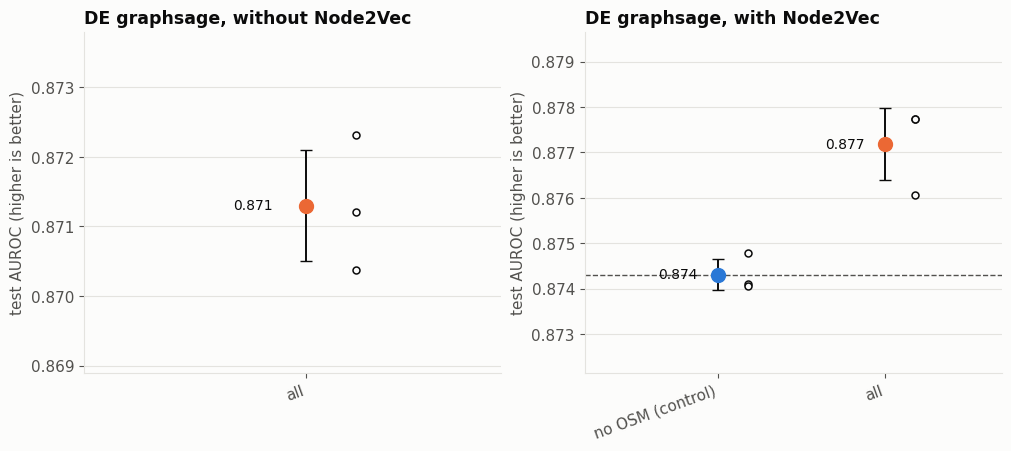

In [26]:
for task in TASKS:
    plot_metric_comparison(runs_here, STATE, task)

In [27]:
def describe_changes(comparison, runs):
    """One sentence per comparison. A change is called clear if there are at least 3 seeds, every seed moves the same way, and the change exceeds the control's seed-to-seed spread."""
    lines = []
    for _, row in comparison[comparison["metric"].isin(["AUROC", "MAE"])].iterrows():
        same = (runs["state"] == row["state"]) & (runs["model"] == row["model"]) & (runs["task"] == row["task"]) & (runs["n2v"] == row["node2vec"])
        control = runs[same & (runs["label"] == "none")]
        control = (control if len(control) else runs[same & (runs["label"] == "committed baseline")]).iloc[0]
        spread = float(np.std(list(metric_by_seed(control, row["metric"]).values())))
        won, total = map(int, row["seeds_improved"].split("/"))
        direction_ok = won == total or won == 0
        clear = direction_ok and abs(row["change"]) > spread
        better = (row["change"] > 0) == HIGHER_IS_BETTER[row["metric"]]
        verdict = (("clearly better" if better else "clearly worse") if clear else "not distinguishable from seed noise")
        if total < 3:
            verdict = "too few seeds to judge (needs 3)"
        lines.append(f"{row['state']} {row['model']} {row['task']} ({'with' if row['node2vec'] else 'without'} Node2Vec), OSM '{row['variant']}': "
                     f"{row['metric']} {row['control']:.4f} -> {row['variant_value']:.4f} ({row['change']:+.4f}, {row['seeds_improved']} seeds improved; "
                     f"control seed spread {spread:.4f}; control {row['control_source']}): {verdict}")
    return lines

print("\n".join(describe_changes(comparison, runs_here)))

DE graphsage classification (without Node2Vec), OSM 'all': AUROC 0.8461 -> 0.8713 (+0.0252, 3/3 seeds improved; control seed spread 0.0037; control team's committed run): clearly better
DE graphsage classification (with Node2Vec), OSM 'all': AUROC 0.8743 -> 0.8772 (+0.0029, 3/3 seeds improved; control seed spread 0.0003; control trained here): clearly better


### 8.1 The 2 x 2: Node2Vec and the OSM features together
The four corners show whether the two sources of information **add up** or **overlap**. If the OSM gain is clearly larger without Node2Vec than with it,
the OSM features describe some of what Node2Vec already provides (for example, both can tell the model which part of the network a road lies in).
If the OSM gain is about the same either way, they contribute separately, and overlap does not explain the small gain.

DE graphsage classification: test AUROC


,control (no OSM),with OSM 'all'
Node2Vec,,
without,0.8461 ± 0.0037,0.8713 ± 0.0008
with,0.8743 ± 0.0003,0.8772 ± 0.0008


,value
Node2Vec gain (control),0.0282
OSM gain without Node2Vec,0.0252
OSM gain with Node2Vec,0.0029
share of the OSM gain lost once Node2Vec is present,0.8862


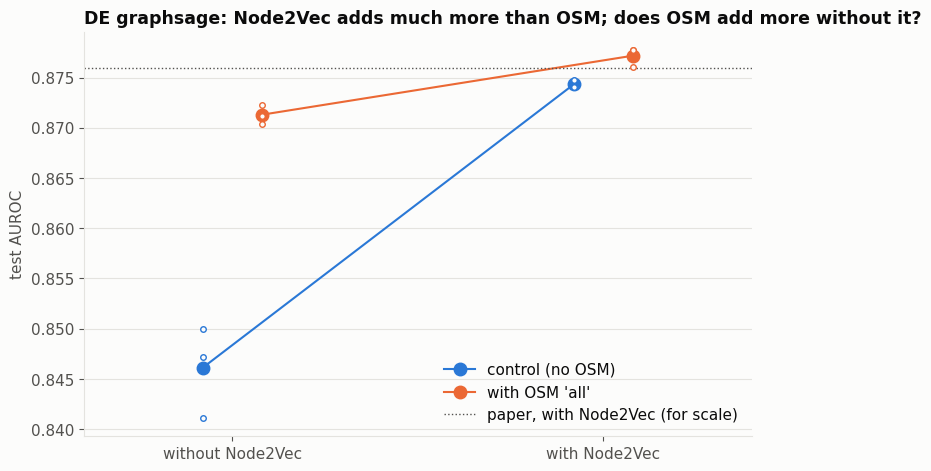

In [28]:
for model in MODELS:
    for task in TASKS:
        table, gains = two_by_two(runs_here, STATE, model, task)
        print(f"{STATE} {model} {task}: test {PRIMARY_METRIC[task]}")
        display(table)
        display(pd.Series(gains, name="value").round(4).to_frame())
        plot_two_by_two(runs_here, STATE, model, task)

## 9. Which feature groups does the model rely on?
For a trained model, one feature group at a time is **shuffled across roads** (the same shuffle every month) and the test months are scored again with the baseline's own evaluation.
A group the model ignores can be shuffled with no change; a group it relies on makes the score worse. It is run for the `all` model with and without Node2Vec:
if the OSM groups matter more without Node2Vec, that is direct evidence of overlap.

Reading it: a large drop means the model uses that group, not that the group causes accidents. Groups with overlapping information share the credit.

In [29]:
PERMUTATION_LABELS = ["all"]   # analysed for every Node2Vec setting in the plan

def permutation_is_current(name):
    """True if the run's permutation importance was computed on the current feature table (it is recomputed after retraining)."""
    path = Path("results") / name / "permutation_importance.json"
    return path.exists() and json.loads(path.read_text()).get("pipeline_version") == CURRENT_TABLE_VERSION
for model, task, n2v, label, groups in PLAN:
    name = run_name(model, task, n2v, label)
    if label not in PERMUTATION_LABELS or not groups or not is_complete(name):
        continue
    if permutation_is_current(name) and not FORCE_RERUN:
        print(f"Skipping {name} (already done)", flush=True)
        continue
    if not GPU:
        raise RuntimeError(f"permutation importance for {name} still needs computing, which needs a GPU: switch to a GPU runtime and run again")
    print(f"\n=== permutation importance: {name}", flush=True)
    command = [TRAIN_PYTHON, "-u", "osm_train.py", "--state", STATE, "--model", model, "--task", task,
               "--seeds", *SEEDS, "--run-name", name]
    if not n2v:
        command.append("--without-node2vec")
    run_live(command + ["--osm-groups", *groups, "--permutation-importance"])

Skipping DE_graphsage_classification_n2v_osm_all (already done)
Skipping DE_graphsage_classification_no_n2v_osm_all (already done)



DE_graphsage_classification_n2v_osm_all


,feature set,columns,worsening,std over seeds,unshuffled,shuffled
0,baseline road flags and length,25,0.1199,0.0009,0.8772,0.7573
1,all OSM columns,70,0.0791,0.0022,0.8772,0.7980
2,OSM nearby_places,35,0.0454,0.0012,0.8772,0.8317
3,OSM road_character,14,0.0061,0.0003,0.8772,0.8711
4,OSM intersection_control,12,0.0046,0.0004,0.8772,0.8726
5,OSM road_shape,2,0.0023,0.0000,0.8772,0.8749
6,traffic (AADT),2,-0.0000,0.0000,0.8772,0.8772
7,OSM cycle_pedestrian_lighting,6,-0.0001,0.0000,0.8772,0.8773


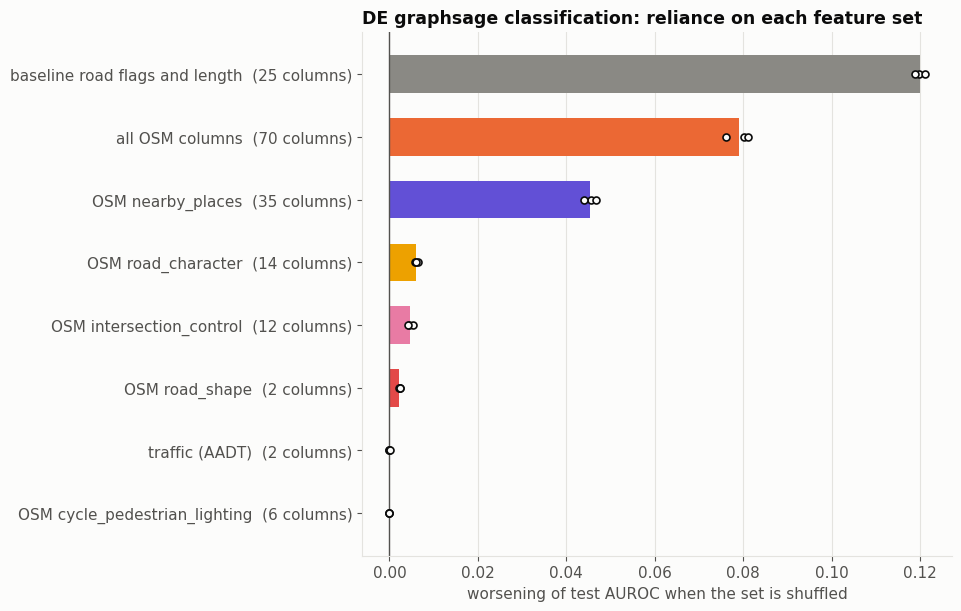


DE_graphsage_classification_no_n2v_osm_all


,feature set,columns,worsening,std over seeds,unshuffled,shuffled
0,baseline road flags and length,25,0.1377,0.0039,0.8713,0.7336
1,all OSM columns,70,0.0908,0.0091,0.8713,0.7805
2,OSM nearby_places,35,0.0555,0.0040,0.8713,0.8158
3,OSM road_character,14,0.0064,0.0006,0.8713,0.8649
4,OSM intersection_control,12,0.0035,0.0006,0.8713,0.8678
5,OSM road_shape,2,0.0029,0.0005,0.8713,0.8684
6,OSM cycle_pedestrian_lighting,6,0.0001,0.0001,0.8713,0.8712
7,traffic (AADT),2,-0.0001,0.0000,0.8713,0.8714


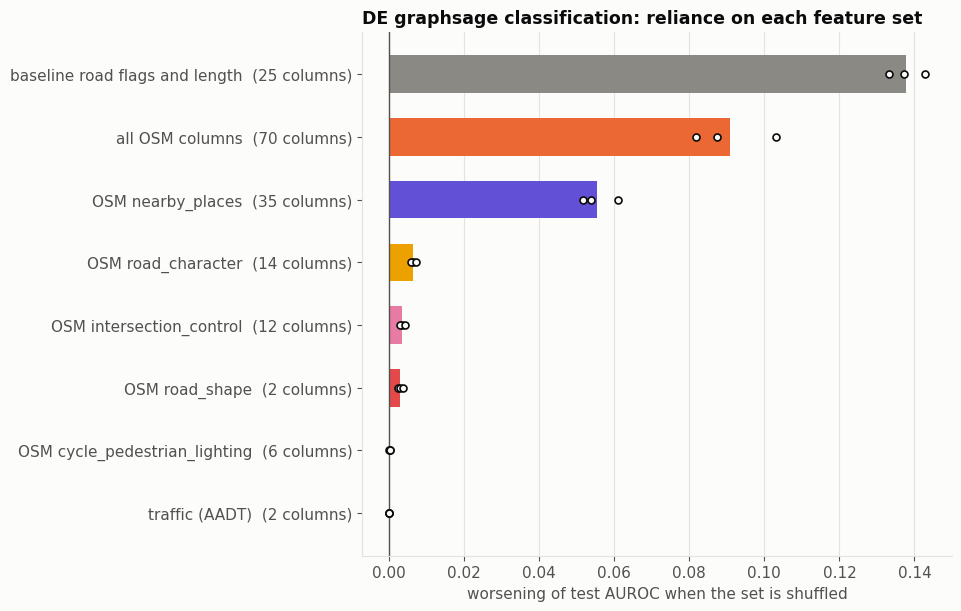

In [30]:
for model, task, n2v, label, groups in PLAN:
    name = run_name(model, task, n2v, label)
    importance = load_permutation_importance("results", name)
    if importance is None:
        continue
    print(f"\n{name}")
    display(permutation_table(importance).round(4))
    plot_permutation_importance(importance, f"{STATE} {model} {task}: reliance on each feature set")

### 9.1 Why is the traffic (AADT) importance zero?
Shuffling the traffic columns changed the score by exactly 0.0000 in every seed. Either the model ignores traffic, or the traffic input is **the same for every road**
in the test years (for example, if no annual traffic count is available for them), in which case shuffling it cannot change anything.
This check reads the inputs the model actually receives: for each year, the share of roads with a reported AADT, and how many distinct values the two traffic columns take.

In [31]:
run_live([TRAIN_PYTHON, "osm_train.py", "--state", STATE, "--traffic-check", "--osm-groups"])

split  year  share_of_roads_with_AADT  traffic_column_std  traffic_distinct_values  missing_flag_distinct_values
train  2009                    0.0058              0.0778                      636                             2
train  2010                    0.0058              0.0767                      641                             2
train  2011                    0.0058              0.0754                      649                             2
train  2012                    0.0058              0.0743                      645                             2
valid  2013                    0.0058              0.0728                      645                             2
valid  2014                    0.0105              0.0931                     1121                             2
valid  2015                    0.0106              0.0927                     1132                             2
valid  2016                    0.0106              0.0917                     1131              

## 10. Where does it help?

The control and an OSM model scored on the same groups of roads, over all test months: road type, length, whether the road was matched to OpenStreetMap, whether a speed limit is tagged, and whether a signal is within 250 m. For classification the scores are the pooled AUROC and the average precision (AP); for regression the MAE. Seeds are averaged. Small groups give noisy scores, so read the road counts alongside.

Set `FOCUS` to choose the setting and the variant to compare with the control.

In [33]:
FOCUS = {"model": MODELS[0], "task": TASKS[0], "n2v": USE_NODE2VEC[0], "variant": "all"}

control_name = run_name(FOCUS["model"], FOCUS["task"], FOCUS["n2v"], "none")
variant_name = run_name(FOCUS["model"], FOCUS["task"], FOCUS["n2v"], FOCUS["variant"])
seeds = [int(s) for s in SEEDS]
control_predictions = load_predictions("results", control_name, seeds)
variant_predictions = load_predictions("results", variant_name, seeds)
subgroups = compare_subgroups(STATE, FOCUS["task"], control_predictions, variant_predictions, "data")
print(f"{variant_name} against {control_name}")
display(subgroups.round(4))

DE_graphsage_classification_n2v_osm_all against DE_graphsage_classification_n2v_osm_none


,group,roads,accident rate,AUROC control,AUROC OSM,AUROC change,AP control,AP OSM,AP change
0,road type: motorway,706,0.2074,0.8297,0.8439,0.0142,0.5596,0.5817,0.0221
1,road type: trunk,3884,0.1246,0.7736,0.7815,0.0079,0.3389,0.3551,0.0162
2,road type: primary,3812,0.1233,0.7552,0.7624,0.0072,0.3122,0.3205,0.0084
3,road type: secondary,3730,0.0913,0.7414,0.7484,0.0070,0.2300,0.2382,0.0082
4,road type: tertiary,7123,0.0574,0.7635,0.7688,0.0053,0.1846,0.1965,0.0119
5,road type: residential,44294,0.0123,0.8391,0.8420,0.0029,0.0939,0.1018,0.0079
6,road type: other,1703,0.0296,0.8360,0.8430,0.0070,0.2112,0.2166,0.0053
7,length: under 100 m,30068,0.0223,0.8713,0.8741,0.0027,0.1499,0.1602,0.0103
8,length: 100 to 300 m,24419,0.0354,0.8656,0.8675,0.0019,0.2299,0.2377,0.0077
9,length: 300 m to 1 km,8797,0.0740,0.8425,0.8478,0.0053,0.3366,0.3524,0.0158


## 11. Is the change consistent across months?

For each test month, the change in the primary metric (OSM minus control), averaged over seeds. The interval resamples whole months, so it shows month-to-month variation (neighbouring months resemble each other, so it is somewhat too narrow). It does not include variation between training runs; the per-seed changes in section 8 show that.

{'overall change': np.float64(0.0029), 'interval low': 0.0026, 'interval high': 0.0031, 'months improved': '57/57'}


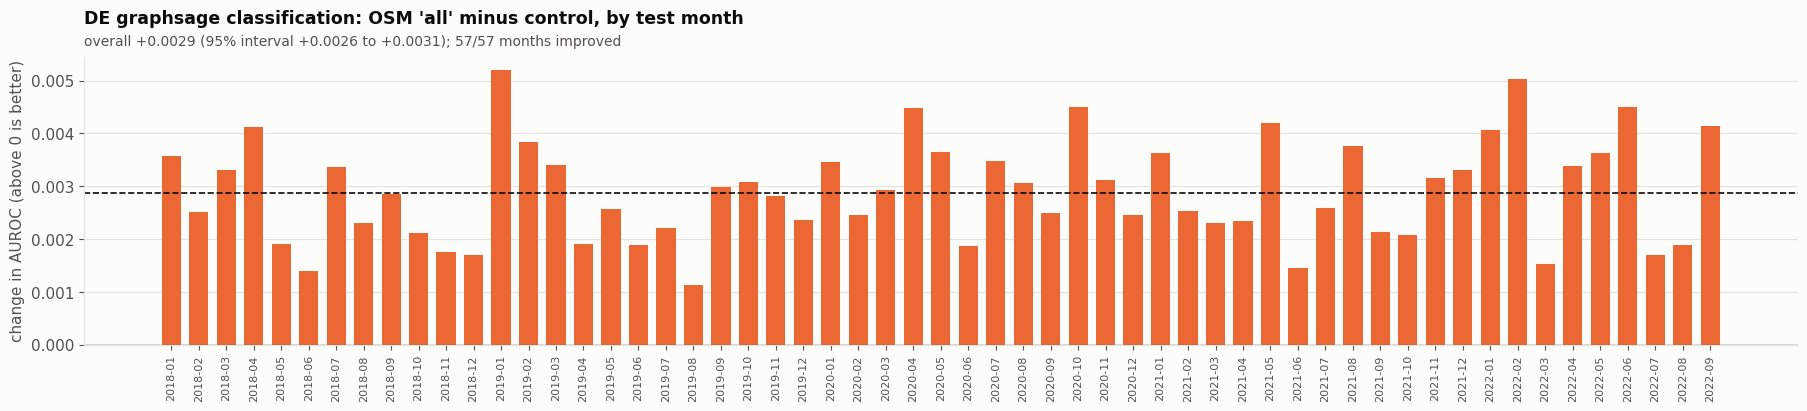

In [34]:
table, summary = compare_months(control_predictions, variant_predictions, FOCUS["task"])
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in summary.items()})
plot_monthly_change(table, summary, FOCUS["task"], f"{STATE} {FOCUS['model']} {FOCUS['task']}: OSM '{FOCUS['variant']}' minus control, by test month")

## 12. Why is the result what it is?
Each paragraph below is generated from a table above and names the section that supports it. They are **explanations with evidence**, not proofs:
the snapshot date, reverse causality and the single embedding seed limit how far they go.

In [35]:
show = lambda text: display(Markdown(text))
from IPython.display import Markdown
show(why_this_result(runs_here, STATE, MODELS[0], TASKS[0], subgroups=subgroups))

**1. Node2Vec adds more than the OSM features.** Without OSM, Node2Vec raises test AUROC by +0.0282. The OSM features add +0.0029 with Node2Vec and +0.0252 without it (Section 8.1). Without Node2Vec, the OSM features recover 89% of what Node2Vec adds, from interpretable road attributes instead of a learned embedding.

About 89% of the OSM gain disappears once Node2Vec is present: the two **overlap**, because both help the model recognise where a road is (see `notebooks/osm_node2vec_density_check.ipynb`).

**2. Which features the model uses** (Section 9): the OSM group it relies on most is `nearby_places` (shuffling it lowers AUROC by 0.0454). Fill rates (share of directed roads with a value): speed limit 14%, lanes 13%, surface 17%, lighting 1%, signal at the start node 90%, nearby places (signals within 250 m) 100%, curviness 99%. The tag-based features are present on only 1-17% of roads, so they can carry little for most roads, whatever their relevance. Without Node2Vec, shuffling `nearby_places` lowers AUROC by 0.0555, against 0.0454 with it: the model leans on it more when the embedding is absent, as the overlap explanation predicts.

**3. The traffic input** (Section 9.1): traffic volume (AADT) is reported for only 1.0% of roads in the test years (the rest carry the missing value), so shuffling it moves real values across very few roads and can barely change the score: the near-zero importance is a **coverage effect**. It is also a finding about the benchmark: the exposure measure that would separate busy from dangerous roads is missing for almost every road.

**4. Where the gain is** (Section 10): among groups of at least 100 roads, it is largest for `road type: motorway` (706 roads); the full table shows how it compares on short and residential roads, which are most of the network.

**5. Limits of this explanation.** One OSM snapshot (2026) for 2009-2022 accidents, and some control may have been added *because* of accidents (reverse causality); one fixed Node2Vec embedding, one split, one state and three seeds; the team's pipeline is a modified reproduction of the paper's.

## 13. Summary
**Headline** (generated below): the change in test AUROC from adding the OSM features to the paper's setting, with and without Node2Vec, and whether it is clear.

**How to read it.** A small but consistent gain means the features carry real information, but most of it is either already in the baseline's inputs (road type, length, Node2Vec) or
missing from OpenStreetMap for most roads. Sections 8.1 and 9 say which of the two dominates. A follow-up check (`osm_node2vec_density_check.ipynb`) shows how the
overlap with Node2Vec arises: Node2Vec predicts a road's surroundings well only in areas it has seen (R² about 0.7 against about 0.06 in unseen areas), so it works as a
location identifier. Because training and testing use the same roads in different years, recognising a road already carries much of its risk, and the OSM features add little on top. The hypothesis that richer data would raise the gain is plausible, not shown:
it would be tested with more complete attribute sources (paid road data, state DOT inventories) and a historical OSM snapshot matched to each accident year.

**Caveats to state with the result**
- **Three seeds and one fixed Node2Vec embedding**: the seed spread covers model initialisation only, not the embedding or the split.
- **One OSM snapshot (2026) for accidents from 2009-2022.** Infrastructure added later can look like it explains older accidents, and some control may have been installed *because* of accidents (reverse causality).
- **Missing tags.** Speed limit, lanes and surface are known on a minority of roads; with `road_character` the model gets a "missing" indicator, with `road_character_filled` flagged estimates.
- **The control is the team's pipeline**, a modified reproduction of the paper's; compare it with the paper's 87.6 for scale only.
- **Delaware only.** Maryland has a different split and mapping quality, and about five times the roads; it was not run because of the memory and compute available.

In [36]:
headline = []
comparison = compare_with_control(runs_here, secondary=False)
for _, row in comparison.iterrows():
    headline.append(f"* {'with' if row['node2vec'] else 'without'} Node2Vec, OSM '{row['variant']}': {row['metric']} {row['control']:.4f} -> {row['variant_value']:.4f} "
                    f"({row['change']:+.4f}; {row['seeds_improved']} seeds improved; control {row['control_source']})")
show("**Headline**\n\n" + "\n".join(headline) + "\n\nThe verdict for each line (clear or within seed noise) is in Section 8.")

**Headline**

* without Node2Vec, OSM 'all': AUROC 0.8461 -> 0.8713 (+0.0252; 3/3 seeds improved; control team's committed run)
* with Node2Vec, OSM 'all': AUROC 0.8743 -> 0.8772 (+0.0029; 3/3 seeds improved; control trained here)

The verdict for each line (clear or within seed noise) is in Section 8.

## 14. Adding the OSM features to the other baseline settings
Sections 6-13 study the paper's setting, GraphSAGE classification. The final report compares every input setting for both baseline models
(MLP and GraphSAGE) and both tasks (classification and count regression), so this section trains the three remaining OSM runs with the
same driver, feature table and settings: Delaware, Node2Vec embeddings, all five feature groups, seeds 0-2, 100 epochs.

| | classification | regression |
|---|---|---|
| MLP | **trained here** | **trained here** |
| GraphSAGE | Section 6 | **trained here** |

Each run is compared with the team's committed baseline run for the same model and task (with Node2Vec, no OSM features). Section 6 showed that
the control trained by this notebook reproduces that committed run to four decimals, so no further controls are trained.

**To run this section only:** run Sections 1 and 2 (setup and the driver), then the two cells below. Sections 3-13 are not needed.
On a T4 GPU the three runs take about 1.5-2 hours, and about 30 minutes on an A100 or L4. A finished seed is never trained again,
so after a disconnection, rerun Sections 1 and 2 and then this section.

In [19]:
# Self-contained: uses only what Sections 1 and 2 define (STATE, TRAIN_PYTHON, GPU, run_live, zip_fingerprints, zips_before).
import json
from pathlib import Path

OTHER_SETTINGS_RUNS = [("mlp", "classification"), ("mlp", "regression"), ("graphsage", "regression")]
OTHER_SETTINGS_GROUPS = ["road_character", "intersection_control", "cycle_pedestrian_lighting", "nearby_places", "road_shape"]
OTHER_SETTINGS_SEEDS = ["0", "1", "2"]
OTHER_SETTINGS_EPOCHS = 100


def osm_run_name(model, task):
    """Run folder name, matching Section 4's naming for the GraphSAGE classification run (DE_graphsage_classification_n2v_osm_all)."""
    return f"{STATE}_{model}_{task}_n2v_osm_all"


def run_is_finished(name):
    """True if every seed of the run finished with the full number of epochs."""
    path = Path("results") / name / "metrics.json"
    if not path.exists():
        return False
    result = json.loads(path.read_text())
    return (bool(result.get("complete")) and len(result["runs"]) == len(OTHER_SETTINGS_SEEDS)
            and result["config"]["epochs"] == OTHER_SETTINGS_EPOCHS)


runs_to_train = [osm_run_name(m, t) for m, t in OTHER_SETTINGS_RUNS if not run_is_finished(osm_run_name(m, t))]
print("to train:", runs_to_train or "nothing, all three runs are finished")
if runs_to_train and not GPU:
    raise RuntimeError("training needs a GPU: switch to a GPU runtime and rerun Sections 1, 2 and this cell")

# Node2Vec embeddings are cached on Drive by the earlier runs, so this normally only confirms the file exists.
run_live([TRAIN_PYTHON, "-u", "-m", "src.data.node2vec", "--state", STATE])

for model, task in OTHER_SETTINGS_RUNS:
    name = osm_run_name(model, task)
    if run_is_finished(name):
        print(f"Skipping {name} (finished)", flush=True)
        continue
    print(f"\n=== {name}  (OSM groups: all five)", flush=True)
    run_live([TRAIN_PYTHON, "-u", "osm_train.py", "--state", STATE, "--model", model, "--task", task,
              "--epochs", str(OTHER_SETTINGS_EPOCHS), "--seeds", *OTHER_SETTINGS_SEEDS, "--select-protocol", "all",
              "--run-name", name, "--osm-groups", *OTHER_SETTINGS_GROUPS], quiet=True)
assert zip_fingerprints() == zips_before, "a zip in the data folder changed or was removed"
print("Zips in data/ still untouched.")

to train: ['DE_mlp_classification_n2v_osm_all', 'DE_mlp_regression_n2v_osm_all', 'DE_graphsage_regression_n2v_osm_all']
DE: reusing /content/baseline_osm/data/embeddings/node2vec_merged/DE_128.npy

=== DE_mlp_classification_n2v_osm_all  (OSM groups: all five)
DE: reusing /content/baseline_osm/data/embeddings/node2vec_merged/DE_128.npy
Data coverage: {'num_nodes': 49023, 'num_roads': 65252, 'target_unit': 'physical', 'months': {'train': 48, 'valid': 60, 'test': 57}}
[seed 0] trained: best epoch 25, valid AUROC 0.8855, test AUROC 0.8806
[seed 1] trained: best epoch 30, valid AUROC 0.8855, test AUROC 0.8806
[seed 2] trained: best epoch 25, valid AUROC 0.8855, test AUROC 0.8809

DE_mlp_classification_n2v_osm_all: test results over seeds [0, 1, 2]
  all: AUROC 0.8807 ± 0.0001, PR-AUC 0.2822 ± 0.0030, precision@0.5 0.1364 ± 0.0069, recall@0.5 0.7984 ± 0.0202, AUROC (pooled) 0.8802 ± 0.0003, precision@top1% 0.4872 ± 0.0054, recall@top1% 0.1303 ± 0.0014
  balanced: AUROC 0.8808 ± 0.0001, PR-AU

### 14.1 Results against the committed baselines
Test scores over the three seeds (mean ± population standard deviation), the change from the baseline, and how many seeds improved
(seeds are paired by number; higher is better for the classification metrics, lower for MAE and MSE). The last column confirms that every
OSM run was trained on the same feature table as the GraphSAGE classification run. After this cell, copy the three run folders from
`My Drive/cs5284_project/results/` into the repository's `results/osm/`.

In [20]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

COMPARED_METRICS = {"classification": ["AUROC", "PR-AUC", "precision@top1%", "recall@top1%"], "regression": ["MAE", "MSE"]}
LOWER_IS_BETTER = {"MAE", "MSE"}
feature_table_version = json.loads(Path(f"data/{STATE}_osm_features_meta.json").read_text())["pipeline_version"]


def test_scores_by_seed(metrics_path, metric):
    """Test score of each seed on all roads, keyed by seed."""
    result = json.loads(Path(metrics_path).read_text())
    return {run["seed"]: run["test"]["all"][metric] for run in result["runs"]}


comparison_rows = []
for model in ("mlp", "graphsage"):
    for task in ("classification", "regression"):
        osm_path = Path("results") / f"{STATE}_{model}_{task}_n2v_osm_all" / "metrics.json"
        baseline_path = COMMITTED_DIR / f"{STATE}_{model}_{task}_n2v" / "metrics.json"
        if not osm_path.exists():
            print(f"not trained yet: {osm_path.parent.name}")
            continue
        trained_on = ((json.loads(osm_path.read_text()).get("provenance") or {}).get("osm") or {}).get("pipeline_version")
        for metric in COMPARED_METRICS[task]:
            baseline, with_osm = test_scores_by_seed(baseline_path, metric), test_scores_by_seed(osm_path, metric)
            seeds = sorted(set(baseline) & set(with_osm))
            sign = -1 if metric in LOWER_IS_BETTER else 1
            improved = sum(sign * (with_osm[s] - baseline[s]) > 0 for s in seeds)
            base_values, osm_values = [baseline[s] for s in seeds], [with_osm[s] for s in seeds]
            comparison_rows.append({
                "model": model, "task": task, "metric": metric,
                "baseline": f"{np.mean(base_values):.4f} ± {np.std(base_values):.4f}",
                "with OSM": f"{np.mean(osm_values):.4f} ± {np.std(osm_values):.4f}",
                "change": round(float(np.mean(osm_values) - np.mean(base_values)), 4),
                "seeds improved": f"{improved}/{len(seeds)}",
                "feature table": trained_on,
            })

other_settings_comparison = pd.DataFrame(comparison_rows)
display(other_settings_comparison)
stale = other_settings_comparison.loc[other_settings_comparison["feature table"] != feature_table_version, "model"]
assert stale.empty, f"some runs were trained on another feature table than {feature_table_version}"
print(f"All runs use feature table version {feature_table_version}.")

,model,task,metric,baseline,with OSM,change,seeds improved,feature table
0,mlp,classification,AUROC,0.8780 ± 0.0002,0.8807 ± 0.0001,0.0027,3/3,3.1
1,mlp,classification,PR-AUC,0.2788 ± 0.0016,0.2822 ± 0.0030,0.0034,3/3,3.1
2,mlp,classification,precision@top1%,0.4822 ± 0.0022,0.4872 ± 0.0054,0.0050,3/3,3.1
3,mlp,classification,recall@top1%,0.1289 ± 0.0005,0.1303 ± 0.0014,0.0013,3/3,3.1
4,mlp,regression,MAE,0.2201 ± 0.0040,0.2122 ± 0.0057,-0.0078,3/3,3.1
5,mlp,regression,MSE,0.1693 ± 0.0023,0.1672 ± 0.0042,-0.0021,2/3,3.1
6,graphsage,classification,AUROC,0.8743 ± 0.0003,0.8772 ± 0.0008,0.0029,3/3,3.1
7,graphsage,classification,PR-AUC,0.2627 ± 0.0013,0.2740 ± 0.0017,0.0113,3/3,3.1
8,graphsage,classification,precision@top1%,0.4585 ± 0.0031,0.4714 ± 0.0015,0.0129,3/3,3.1
9,graphsage,classification,recall@top1%,0.1226 ± 0.0009,0.1261 ± 0.0003,0.0035,3/3,3.1


All runs use feature table version 3.1.


## 15. Adding the OSM features to GatedGCN and Graph Transformer
The final report compares four architectures. This notebook's pinned baseline code contains only MLP and GraphSAGE, so
GatedGCN and Graph Transformer are trained with the team's main training script, `src/model/train.py`, which builds the
OSM columns with the same encoding as `osm_train.py` above (`src/data/osm.py`). Each architecture is trained for both tasks
with all five OSM groups, Node2Vec, no accident history, seeds 0-2 and 100 epochs, the settings of its control run
without OSM, `results/DE_<model>_<task>_n2v_hist_none`. The reported runs were trained on the same machine (RTX 5080) as
those controls, and their results are in `results/osm/DE_<model>_<task>_n2v_osm_all_hist_none/`.

**To retrain:** run the next cell from inside the repository, on a GPU machine whose `data/` folder holds the Delaware
dataset, the OSM feature table and the Node2Vec embedding used by the controls, with `RUN_ARCHITECTURE_TRAINING = True`.
It does not need Sections 1-14. A finished seed is not trained again. The cells after it read stored scores and need no GPU.

In [ ]:
RUN_ARCHITECTURE_TRAINING = False   # True retrains the four runs (about an hour on an RTX 5080)

import os
import subprocess
import sys
from pathlib import Path


def repository_root(start):
    """The nearest folder above `start` whose training code includes GatedGCN and Graph Transformer."""
    for folder in [start, *start.parents]:
        if (folder / "src" / "model" / "train.py").is_file() and (folder / "src" / "model" / "gatedgcn").is_dir():
            return folder
    raise FileNotFoundError("run this cell from inside the team repository, for example from its notebooks/ folder")


def run_streaming(command, cwd):
    """Run a command and print its output in the notebook as it arrives (progress bars hidden)."""
    environment = dict(os.environ, PYTHONUNBUFFERED="1", TQDM_DISABLE="1")
    with subprocess.Popen(command, cwd=cwd, env=environment, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                          text=True, bufsize=1) as process:
        for line in process.stdout:
            print(line, end="", flush=True)
    if process.returncode:
        raise subprocess.CalledProcessError(process.returncode, command)


ARCHITECTURE_SETTINGS = ["--history-mode", "none", "--osm-groups", "all", "--epochs", "100", "--seeds", "0", "1", "2",
                         "--hidden-channels", "256", "--num-layers", "2", "--num-heads", "4", "--dropout", "0.0",
                         "--lr", "0.001", "--eval-every", "5", "--select-protocol", "all", "--resume"]

if RUN_ARCHITECTURE_TRAINING:
    repository = repository_root(Path.cwd().resolve())
    for model in ("gatedgcn", "graph_transformer"):
        for task in ("classification", "regression"):
            print(f"\n=== DE_{model}_{task}_n2v_osm_all_hist_none", flush=True)
            run_streaming([sys.executable, "-u", "-m", "src.model.train", "--state", "DE", "--model", model,
                           "--task", task, *ARCHITECTURE_SETTINGS], cwd=repository)
    print("Finished. The runs are in results/DE_<model>_<task>_n2v_osm_all_hist_none/; the report reads them from results/osm/.")
else:
    print("Training skipped (RUN_ARCHITECTURE_TRAINING = False); the comparison below uses the stored scores.")

In [ ]:
# Test scores per seed (all roads) of the four reported OSM runs and their controls, copied from their metrics.json files.
ARCHITECTURE_RUNS = json.loads(r'''{"gatedgcn|classification|control": {"source": "results/DE_gatedgcn_classification_n2v_hist_none", "gpu": "NVIDIA GeForce RTX 5080", "test_by_seed": {"0": {"AUROC": 0.8737987087401494, "PR-AUC": 0.2747648768477579, "precision@top1%": 0.4809113135058166, "recall@top1%": 0.1286034954170526}, "1": {"AUROC": 0.8761003839031202, "PR-AUC": 0.27217369936548585, "precision@top1%": 0.4726364149270574, "recall@top1%": 0.12654395616760813}, "2": {"AUROC": 0.8743112410807747, "PR-AUC": 0.2672058667933906, "precision@top1%": 0.4661615754547164, "recall@top1%": 0.12482592048226213}}}, "gatedgcn|classification|with OSM": {"source": "results/osm/DE_gatedgcn_classification_n2v_osm_all_hist_none", "gpu": "NVIDIA GeForce RTX 5080", "test_by_seed": {"0": {"AUROC": 0.8774791581096724, "PR-AUC": 0.2733059490957574, "precision@top1%": 0.47228714972730446, "recall@top1%": 0.12628275744290515}, "1": {"AUROC": 0.8778184431928701, "PR-AUC": 0.2770871733775512, "precision@top1%": 0.4846726310416163, "recall@top1%": 0.12971948472542158}, "2": {"AUROC": 0.8759421420606637, "PR-AUC": 0.27625739131385385, "precision@top1%": 0.480803847290508, "recall@top1%": 0.12851135026417015}}}, "gatedgcn|regression|control": {"source": "results/DE_gatedgcn_regression_n2v_hist_none", "gpu": "NVIDIA GeForce RTX 5080", "test_by_seed": {"0": {"AUROC": 0.8324322580726483, "PR-AUC": 0.2130896488758396, "precision@top1%": 0.34961446495258053, "recall@top1%": 0.09361449096405446, "MAE": 0.17634474602001854, "MSE": 0.16777809608119942}, "1": {"AUROC": 0.8411340088079049, "PR-AUC": 0.21689039363668144, "precision@top1%": 0.33569759007012173, "recall@top1%": 0.0898936137372896, "MAE": 0.18376478400603474, "MSE": 0.17099899206913355}, "2": {"AUROC": 0.8418853992654622, "PR-AUC": 0.21702761718325914, "precision@top1%": 0.33892157652937865, "recall@top1%": 0.09070628249528573, "MAE": 0.1835991798589963, "MSE": 0.1655524923727457}}}, "gatedgcn|regression|with OSM": {"source": "results/osm/DE_gatedgcn_regression_n2v_osm_all_hist_none", "gpu": "NVIDIA GeForce RTX 5080", "test_by_seed": {"0": {"AUROC": 0.833751872679522, "PR-AUC": 0.21390976553862603, "precision@top1%": 0.34456355283307816, "recall@top1%": 0.09225484187572669, "MAE": 0.17894593592303668, "MSE": 0.169470646865192}, "1": {"AUROC": 0.8323848985143144, "PR-AUC": 0.2081679067523201, "precision@top1%": 0.344348620402461, "recall@top1%": 0.09214131581588371, "MAE": 0.17200452714874492, "MSE": 0.1620521561301921}, "2": {"AUROC": 0.8586909596950985, "PR-AUC": 0.23228797931613962, "precision@top1%": 0.35764756454689556, "recall@top1%": 0.09579331497528425, "MAE": 0.17829428683420082, "MSE": 0.15203831371896873}}}, "graph_transformer|classification|control": {"source": "results/DE_graph_transformer_classification_n2v_hist_none", "gpu": "NVIDIA GeForce RTX 5080", "test_by_seed": {"0": {"AUROC": 0.8739183798556508, "PR-AUC": 0.26770545348049213, "precision@top1%": 0.46366298594879235, "recall@top1%": 0.1239044436366568}, "1": {"AUROC": 0.8732279675190856, "PR-AUC": 0.2688369844059682, "precision@top1%": 0.46718250450014775, "recall@top1%": 0.12504846864920657}, "2": {"AUROC": 0.8729335487422155, "PR-AUC": 0.27125111662709567, "precision@top1%": 0.4705408237285404, "recall@top1%": 0.12579501147997169}}}, "graph_transformer|classification|with OSM": {"source": "results/osm/DE_graph_transformer_classification_n2v_osm_all_hist_none", "gpu": "NVIDIA GeForce RTX 5080", "test_by_seed": {"0": {"AUROC": 0.8767118855564864, "PR-AUC": 0.27662805175854066, "precision@top1%": 0.47811719190779395, "recall@top1%": 0.1278454630429356}, "1": {"AUROC": 0.8756114038943942, "PR-AUC": 0.2652480813257345, "precision@top1%": 0.44622659251497815, "recall@top1%": 0.11938984724844676}, "2": {"AUROC": 0.8744091987074109, "PR-AUC": 0.2737086396618022, "precision@top1%": 0.47140055345100884, "recall@top1%": 0.12611238209907463}}}, "graph_transformer|regression|control": {"source": "results/DE_graph_transformer_regression_n2v_hist_none", "gpu": "NVIDIA GeForce RTX 5080", "test_by_seed": {"0": {"AUROC": 0.822237460296843, "PR-AUC": 0.19640734729785633, "precision@top1%": 0.31600440611482766, "recall@top1%": 0.08454115843174441, "MAE": 0.19139451031034058, "MSE": 0.18898291906675077}, "1": {"AUROC": 0.8351352097251286, "PR-AUC": 0.20963777921059698, "precision@top1%": 0.31578947368421056, "recall@top1%": 0.08453158484131024, "MAE": 0.18946098711084325, "MSE": 0.17245021559427323}, "2": {"AUROC": 0.8123496092869988, "PR-AUC": 0.18701586555357325, "precision@top1%": 0.28814378979608285, "recall@top1%": 0.07719399992701592, "MAE": 0.18383622572164202, "MSE": 0.1850975744229966}}}, "graph_transformer|regression|with OSM": {"source": "results/osm/DE_graph_transformer_regression_n2v_osm_all_hist_none", "gpu": "NVIDIA GeForce RTX 5080", "test_by_seed": {"0": {"AUROC": 0.8234203624432184, "PR-AUC": 0.19318199146307932, "precision@top1%": 0.284731737460036, "recall@top1%": 0.07617648382323951, "MAE": 0.17923563797860326, "MSE": 0.17582785609378257}, "1": {"AUROC": 0.8224157615693551, "PR-AUC": 0.19743000031945518, "precision@top1%": 0.3174820665753204, "recall@top1%": 0.08490290252147836, "MAE": 0.17968772783540204, "MSE": 0.17305948480223313}, "2": {"AUROC": 0.8197738241334832, "PR-AUC": 0.20639261261481198, "precision@top1%": 0.3442142876333253, "recall@top1%": 0.09211903098544816, "MAE": 0.1711883655569215, "MSE": 0.1687095350404754}}}}''')

### 15.1 Results against the controls
Test scores over the three seeds (mean ± population standard deviation), the change from the control without OSM, and how
many seeds improved (seeds paired by number).

In [ ]:
import json

import numpy as np
import pandas as pd

COMPARED_METRICS = {"classification": ["AUROC", "PR-AUC", "precision@top1%", "recall@top1%"], "regression": ["MAE", "MSE"]}
LOWER_IS_BETTER = {"MAE", "MSE"}

rows = []
for model in ("gatedgcn", "graph_transformer"):
    for task in ("classification", "regression"):
        control = ARCHITECTURE_RUNS[f"{model}|{task}|control"]["test_by_seed"]
        osm = ARCHITECTURE_RUNS[f"{model}|{task}|with OSM"]["test_by_seed"]
        seeds = sorted(set(control) & set(osm))
        for metric in COMPARED_METRICS[task]:
            sign = -1 if metric in LOWER_IS_BETTER else 1
            control_values = [control[s][metric] for s in seeds]
            osm_values = [osm[s][metric] for s in seeds]
            rows.append({"model": model, "task": task, "metric": metric,
                         "control": f"{np.mean(control_values):.4f} ± {np.std(control_values):.4f}",
                         "with OSM": f"{np.mean(osm_values):.4f} ± {np.std(osm_values):.4f}",
                         "change": round(float(np.mean(osm_values) - np.mean(control_values)), 4),
                         "seeds improved": f"{sum(sign * (osm[s][metric] - control[s][metric]) > 0 for s in seeds)}/{len(seeds)}"})
architecture_osm_comparison = pd.DataFrame(rows)
display(architecture_osm_comparison)

,model,task,metric,control,with OSM,change,seeds improved
0,gatedgcn,classification,AUROC,0.8747 ± 0.0010,0.8771 ± 0.0008,0.0023,3/3
1,gatedgcn,classification,PR-AUC,0.2714 ± 0.0031,0.2756 ± 0.0016,0.0042,2/3
2,gatedgcn,classification,precision@top1%,0.4732 ± 0.0060,0.4793 ± 0.0052,0.0060,2/3
3,gatedgcn,classification,recall@top1%,0.1267 ± 0.0015,0.1282 ± 0.0014,0.0015,2/3
4,gatedgcn,regression,MAE,0.1812 ± 0.0035,0.1764 ± 0.0031,-0.0048,2/3
5,gatedgcn,regression,MSE,0.1681 ± 0.0022,0.1612 ± 0.0071,-0.0069,2/3
6,graph_transformer,classification,AUROC,0.8734 ± 0.0004,0.8756 ± 0.0009,0.0022,3/3
7,graph_transformer,classification,PR-AUC,0.2693 ± 0.0015,0.2719 ± 0.0048,0.0026,2/3
8,graph_transformer,classification,precision@top1%,0.4671 ± 0.0028,0.4652 ± 0.0137,-0.0019,2/3
9,graph_transformer,classification,recall@top1%,0.1249 ± 0.0008,0.1244 ± 0.0036,-0.0005,2/3
